In [49]:
import os
import numpy as np
# import matplotlib.pyplot as pl
import matplotlib.pyplot as plt
import pandas as pd
import pooch
import seaborn as sns
from tqdm.auto import tqdm
import xarray as xr
import numpy as np
import scipy.signal
import scipy
from IPython.display import display, Math

import seaborn as sns
import itertools
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from scipy import stats

from scipy.stats import ks_2samp
from scipy.stats import ttest_ind
from xhistogram.xarray import histogram

In [50]:
# import seaborn.objects as so

In [51]:
ls ../../fair_carbon/output/ -larth

total 4.6G
-rw-r--r--  1 gshum atgstaff  23M Mar 24 12:36 'flat10_all-output_fair2.1.3 2.nc'
-rw-r--r--  1 gshum atgstaff 129K Mar 24 12:36  flat10_key-metrics_fair2.1.3csv
-rw-r--r--  1 gshum atgstaff 129K Mar 24 12:36  flat10_key-metrics_fair2.1.3.csv
-rw-r--r--  1 gshum atgstaff  23M Mar 24 12:36  flat10_all-output_fair2.1.3.nc
-rw-r--r--  1 gshum atgstaff  17M Mar 24 12:36  flat10zec_all-output_fair2.1.3_gems_cal_1_2_0_df.nc
-rw-r--r--  1 gshum atgstaff 9.2M Mar 24 12:36  gcb_hist_short_all-output_fair2.1.3_gems_cal_1_2_0_df.nc
-rw-r--r--  1 gshum atgstaff  27M Mar 24 12:36  gcbhist_all-output_fair2.1.3_gems_cal_1_2_0_df.nc
-rw-r--r--  1 gshum atgstaff  50M Mar 24 12:36  gcbhist_modpico2_all-output_fair2.1.3_gems_cal_1_2_0_df.nc
-rw-r--r--  1 gshum atgstaff 5.5M Mar 25 10:12  f_nonSD_200ens_all-output_fair2.1.3_cal_1_2_0_df.nc
drwxr-xr-x  2 gshum atgstaff   62 Mar 25 15:20  .ipynb_checkpoints/
-rw-r--r--  1 gshum atgstaff 8.5M Mar 28 17:44  f_gcb_200ens_all-output_fair2.1.3_cal_1_2

In [52]:
ds_fair_flat10 = xr.open_dataset('../SWANN/PPE/f_nonSD_1000ens_all-output_gems_uncal_param_df_sansSD_2024_04_26.nc')
ds_fairSD_flat10 = xr.open_dataset('../../fair_carbon/output/f_yesSD_1000ens_all-output_gems_uncal_param_df_withSDextended_2024_05_20.nc')
ds_fairSDck_flat10 = xr.open_dataset('../../fair_carbon/output/f_yesSD_1000ens_all-output_gems_uncal_param_df_withSD_constkappa_2024_05_14.nc')
ds_fairSDckp_flat10 = xr.open_dataset('../../fair_carbon/output/f_yesSD_1000ens_all-output_gems_uncal_param_df_withSD_correlatedkappapsi_1000_2024_05_15.nc')

In [53]:
ls ../../fair_carbon/output/curve-fit_params_fair/

curve-fit_params_1xp_all_total_2024_04_16.csv
curve-fit_params_2xp_all_total_2024_04_16.csv
curve-fit_params_3xp_all_total_2024_04_16.csv
curve-fit_params_3xp_all_total_2024_04_21.csv
curve-fit_params_3xp_all_total_2024_05_31_co2T.csv


In [153]:
params_fair = pd.read_csv('../../fair_carbon/src/fair_local/defaults/data/SD_gems/gems_uncal_param_df_sansSD_2024_04_07.csv')

params_fairSD = pd.read_csv('../../fair_carbon/src/fair_local/defaults/data/SD_gems/gems_uncal_param_df_withSD_2024_04_05.csv')

params_fairSDck = pd.read_csv('../../fair_carbon/src/fair_local/defaults/data/SD_gems/gems_uncal_param_df_withSD_constkappa_2024_05_12_withkappas.csv')

params_fairSDckp = pd.read_csv('../../fair_carbon/src/fair_local/defaults/data/SD_gems/gems_uncal_param_df_withSD_corrpsi_1000_2024_05_13.csv')

In [154]:
ds_params_fair = xr.Dataset(params_fair,
          coords = {'config': ds_fair_flat10.config})
ds_params_fairSD = xr.Dataset(params_fairSD,
          coords = {'config': ds_fairSD_flat10.config})
ds_params_fairSDck = xr.Dataset(params_fairSDck,
          coords = {'config': ds_fairSDck_flat10.config})
ds_params_fairSDckp = xr.Dataset(params_fairSDckp,
          coords = {'config': ds_fairSDckp_flat10.config})

In [155]:
# import taus:

curvefit_params_3xp_fair = pd.read_csv('../../fair_carbon/output/curve-fit_params_fair/curve-fit_params_3xp_all_total_2024_04_21.csv')
curvefit_params_3xp_fair = curvefit_params_3xp_fair[curvefit_params_3xp_fair.columns[1:]]
curvefit_params_3xp_SD100 = pd.read_csv('../../fair_carbon/output/curve-fit_params_SD/curve-fit_params_3xp_total_2024_04_11.csv')
curvefit_params_3xp_SD100 = curvefit_params_3xp_SD100[curvefit_params_3xp_SD100.columns[1:]]
curvefit_params_3xp_SDck100 = pd.read_csv('../../fair_carbon/output/curve-fit_params_SDck/curve-fit_params_3xp_all_total_2024_05_23_co2T.csv')
curvefit_params_3xp_SDck100 = curvefit_params_3xp_SDck100[curvefit_params_3xp_SDck100.columns[1:]]
curvefit_params_3xp_SDckp100 = pd.read_csv('../../fair_carbon/output/curve-fit_params_SDckp/curve-fit_params_3xp_all_total_2024_05_19_co2T.csv')
curvefit_params_3xp_SDckp100 = curvefit_params_3xp_SDckp100[curvefit_params_3xp_SDckp100.columns[1:]]
curvefit_params_3xp_SDckp100

curvefit_params_3xp_fairco2T = pd.read_csv('../../fair_carbon/output/curve-fit_params_fair/curve-fit_params_3xp_all_total_2024_05_31_co2T.csv')
curvefit_params_3xp_fairco2T = curvefit_params_3xp_fairco2T[curvefit_params_3xp_fairco2T.columns[1:]]
curvefit_params_3xp_SD100co2T = pd.read_csv('../../fair_carbon/output/curve-fit_params_SD/curve-fit_params_3xp_all_total_2024_05_23_co2T.csv')
curvefit_params_3xp_SD100co2T = curvefit_params_3xp_SD100co2T[curvefit_params_3xp_SD100co2T.columns[1:]]
curvefit_params_3xp_SDck100co2T = pd.read_csv('../../fair_carbon/output/curve-fit_params_SDck/curve-fit_params_3xp_all_total_2024_05_19_co2T.csv')
curvefit_params_3xp_SDck100co2T = curvefit_params_3xp_SDck100co2T[curvefit_params_3xp_SDck100co2T.columns[1:]]
curvefit_params_3xp_SDckp100co2T = pd.read_csv('../../fair_carbon/output/curve-fit_params_SDckp/curve-fit_params_3xp_all_total_2024_05_19_co2T.csv')
curvefit_params_3xp_SDckp100co2T = curvefit_params_3xp_SDckp100co2T[curvefit_params_3xp_SDckp100co2T.columns[1:]]
curvefit_params_3xp_SDckp100co2T

,tau1_total_decarb,tau2_total_decarb,tau3_total_decarb,a1_total_decarb,a2_total_decarb,a3_total_decarb
0,2.980012,32.281104,261.142598,0.147315,0.010974,0.000454
1,0.572185,51.947195,7.933222,0.873581,0.006607,0.047823
2,3.227864,38.891564,339.897549,0.129527,0.009589,0.000297
3,0.494881,49.469629,7.564936,1.303758,0.007192,0.055829
4,2.732617,47.412314,287.409671,0.149715,0.006498,0.000479
...,...,...,...,...,...,...
146,2.975738,32.204556,260.464424,0.162527,0.011269,0.000343
147,2.984636,46.357459,689.474409,0.164908,0.006039,0.000262
148,2.993580,36.515766,351.684074,0.146239,0.009855,0.000318
149,2.477821,41.678648,307.243330,0.176074,0.008864,0.000320


In [156]:
curvefit_params_3xp_fairco2T

,tau1_total_decarb,tau2_total_decarb,tau3_total_decarb,a1_total_decarb,a2_total_decarb,a3_total_decarb
0,2.419930,35.812475,35.812742,0.223423,0.008301,0.001638
1,1.890200,9.935172,150.282321,0.237459,0.024615,0.001321
2,2.784188,80.886763,509.802761,0.211333,0.001561,0.000312
3,1.604644,7.986857,157.506810,0.293303,0.029639,0.001300
4,2.139664,51.416191,6.454002,0.166668,0.006426,0.030436
...,...,...,...,...,...,...
106,1.950330,60.538422,8.035194,0.214389,0.004316,0.027340
107,2.224076,11.955502,107.781296,0.175131,0.022306,0.002053
108,1.884919,115.311579,9.448970,0.197738,0.002123,0.028411
109,1.534779,7.294715,115.265308,0.300533,0.035713,0.001783


In [157]:


constrained_by_co2_SD = np.load('constrained_by_co2_SD.npy').tolist()
constrained_by_co2_SDck = np.load('constrained_by_co2_SDck.npy').tolist()
constrained_by_co2_SDckp = np.load('constrained_by_co2_SDckp.npy').tolist()

constrained_by_co2T_fair = np.load('constrained_by_co2T_fair.npy').tolist()
constrained_by_co2T_SD = np.load('constrained_by_co2T_SD.npy').tolist()
constrained_by_co2T_SDck = np.load('constrained_by_co2T_SDck.npy').tolist()
constrained_by_co2T_SDckp = np.load('constrained_by_co2T_SDckp.npy').tolist()
top100_co2_SD = np.load('top100_co2_SD.npy').tolist()
top100_co2_SDck = np.load('top100_co2_SDck.npy').tolist()
top100_co2_SDckp = np.load('top100_co2_SDckp.npy').tolist()

In [158]:
Tf = ds_fair_flat10.temperature.isel(scenario = 0)#.isel(layer=0)
Tog = ds_fairSD_flat10.temperature.isel(scenario = 0).isel(layer=0)
Tck = ds_fairSDck_flat10.temperature.isel(scenario = 0)
Tckp = ds_fairSDckp_flat10.temperature.isel(scenario = 0).isel(layer=0)

In [159]:
C_per_CO2 = 12.011 / 44.009; print(C_per_CO2)

Cf = ds_fair_flat10.co2_concentration.isel(scenario = 0) * C_per_CO2
Cog = ds_fairSD_flat10.co2_concentration.isel(scenario = 0) * C_per_CO2
Cck = ds_fairSDck_flat10.co2_concentration.isel(scenario = 0) * C_per_CO2
Cckp = ds_fairSDckp_flat10.co2_concentration.isel(scenario = 0) * C_per_CO2

0.27292144788565975


In [160]:
Tog_all = ds_fairSD_flat10.temperature.isel(scenario = 0)
Tckp_all = ds_fairSDckp_flat10.temperature.isel(scenario = 0)

In [161]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
# Define a single color, in this case, grey
grey_color = (0.9, 0.9, 0.9)  # RGB values, where 0 is darkest and 1 is brightest

# Create a colormap with just one color
grey_colormap = LinearSegmentedColormap.from_list('grey', [grey_color, grey_color])


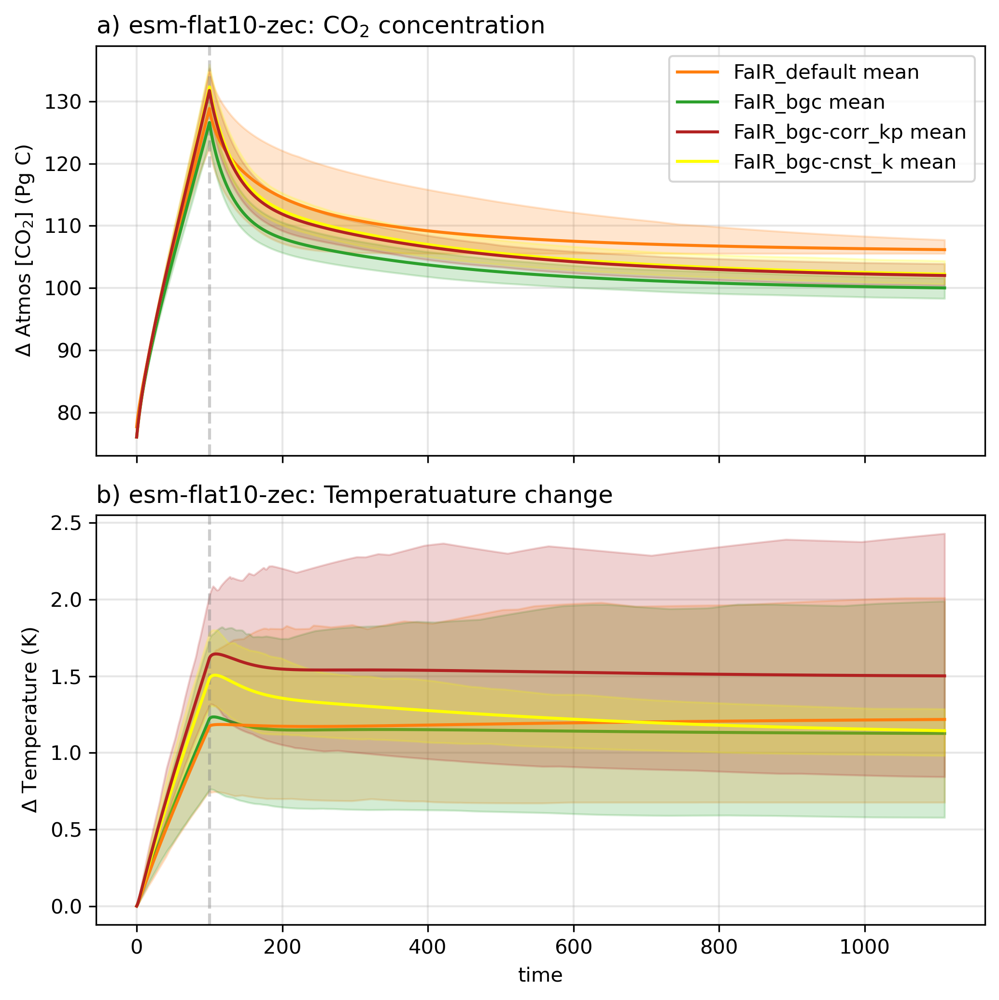

In [356]:
fig, ax = plt.subplots(2,1, figsize = (7,7), dpi = 300, sharex = True)


# CO2 CONCENTRATION


ax[0].plot(Cf[:,constrained_by_co2T_fair].mean('config'), label = r'FaIR_default mean', color = 'tab:orange',zorder = 5,)
ax[0].fill_between(Cf[:,constrained_by_co2T_fair].time, 
                              np.percentile(Cf[:,constrained_by_co2T_fair], 10, axis=1), 
                              np.percentile(Cf[:,constrained_by_co2T_fair], 90, axis=1), 
                              alpha=0.2, color = 'tab:orange',zorder = 2, label = r'_FaIR_default (10th - 90th percentile)')

ax[0].plot(Cog[:,constrained_by_co2T_SD].mean('config'), label = r'FaIR_bgc mean', color = 'tab:green',zorder = 5,)
ax[0].fill_between(Cog[:,constrained_by_co2T_SD].time, 
                              np.percentile(Cog[:,constrained_by_co2T_SD], 10, axis=1), 
                              np.percentile(Cog[:,constrained_by_co2T_SD], 90, axis=1), 
                              alpha=0.2, color = 'tab:green',zorder = 2, label = r'_FaIR_bgc (10th - 90th percentile)')

ax[0].plot(Cckp[:,constrained_by_co2T_SDckp].mean('config'), label = r'FaIR_bgc-corr_kp mean', color = 'firebrick',zorder = 6,
        # alpha = 0
          )
ax[0].fill_between(Cckp[:,constrained_by_co2T_SDckp].time, 
                              np.percentile(Cckp[:,constrained_by_co2T_SDckp], 10, axis=1), 
                              np.percentile(Cckp[:,constrained_by_co2T_SDckp], 90, axis=1), 
                              alpha=0.2, 
                   # alpha = 0,
                   color = 'firebrick',zorder = 2, label = r'_FaIR_bgc-corr_kp (10th - 90th percentile)')



ax[0].plot(Cck[:,constrained_by_co2T_SDck].mean('config'), label = r'FaIR_bgc-cnst_k mean', color = 'yellow',zorder = 5,
        # alpha = 0,
          )
ax[0].fill_between(Cck[:,constrained_by_co2T_SDck].time, 
                              np.percentile(Cck[:,constrained_by_co2T_SDck], 10, axis=1), 
                              np.percentile(Cck[:,constrained_by_co2T_SDck], 90, axis=1), 
                              alpha=0.2,
                 # alpha = 0,
                 color = 'yellow',zorder = 2, label = r'_FaIR_bgc-cnst_k (10th - 90th percentile)')


# TEMPERATURE


ax[1].plot(Tf[:,constrained_by_co2T_fair].mean('config'), label = r'FaIR mean', color = 'tab:orange',zorder = 5,)
ax[1].fill_between(Tf[:,constrained_by_co2T_fair].time, 
                              np.percentile(Tf[:,constrained_by_co2T_fair], 10, axis=1), 
                              np.percentile(Tf[:,constrained_by_co2T_fair], 90, axis=1), 
                              alpha=0.2, color = 'tab:orange',zorder = 2, label = r'_FaIR (10th - 90th percentile)')

ax[1].plot(Tog[:,constrained_by_co2T_SD].mean('config'), label = r'FaIR_bgc mean', color = 'tab:green')
ax[1].fill_between(Tog[:,constrained_by_co2T_SD].time, 
                              np.percentile(Tog[:,constrained_by_co2T_SD], 10, axis=1), 
                              np.percentile(Tog[:,constrained_by_co2T_SD], 90, axis=1), 
                              alpha=0.2, color = 'tab:green',zorder = 2, label = r'_FaIR_bgc (10th - 90th percentile)')
ax[1].plot(Tckp[:,constrained_by_co2T_SDckp].mean('config'), label = r'FaIR_bgc-corr_kp mean', color = 'firebrick',zorder = 6,
        # alpha = 0
          )
ax[1].fill_between(Tckp[:,constrained_by_co2T_SDckp].time, 
                              np.percentile(Tckp[:,constrained_by_co2T_SDckp], 10, axis=1), 
                              np.percentile(Tckp[:,constrained_by_co2T_SDckp], 90, axis=1), 
                   # alpha = 0,
                              alpha=0.2, 
                   color = 'firebrick',zorder = 2, label = r'FaIR_bgc-corr_kp (10th - 90th percentile)')

ax[1].plot(Tck[:,constrained_by_co2T_SDck].mean('config'), label = r'FaIR_bgc-cnst_k mean', color = 'yellow',zorder = 5,
           # alpha = 0,
        )
ax[1].fill_between(Tck[:,constrained_by_co2T_SDck].time, 
                              np.percentile(Tck[:,constrained_by_co2T_SDck], 10, axis=1), 
                              np.percentile(Tck[:,constrained_by_co2T_SDck], 90, axis=1), 
                              alpha=0.2,
                 # alpha = 0,
                 color = 'yellow',zorder = 2, label = r'_FaIR_bgc-cnst_k (10th - 90th percentile)')

ax[0].set_title(r'a) esm-flat10-zec: CO$_2$ concentration', loc = 'left')
ax[1].set_title(r'b) esm-flat10-zec: Temperatuature change', loc = 'left')

for axis in fig.get_axes():
    axis.axvline(100, alpha = 0.4, color = 'grey', ls = 'dashed')
    axis.grid(alpha = 0.3, lw = 1)
ax[0].legend(loc = 'upper right')
ax[0].set_ylabel(r'$\Delta$ Atmos [CO$_2$] (Pg C)')
ax[1].set_ylabel(r'$\Delta$ Temperature (K)')
plt.xlabel('time')
# plt.suptitle('CO$_2$ & T constrained')
plt.tight_layout()
plt.savefig('figures/tseries_T_def_SD_co2T_ckckp.png')

plt.show();plt.close()

In [163]:
sns.color_palette('pastel')

[(0.6313725490196078, 0.788235294117647, 0.9568627450980393),
 (1.0, 0.7058823529411765, 0.5098039215686274),
 (0.5529411764705883, 0.8980392156862745, 0.6313725490196078),
 (1.0, 0.6235294117647059, 0.6078431372549019),
 (0.8156862745098039, 0.7333333333333333, 1.0),
 (0.8705882352941177, 0.7333333333333333, 0.6078431372549019),
 (0.9803921568627451, 0.6901960784313725, 0.8941176470588236),
 (0.8117647058823529, 0.8117647058823529, 0.8117647058823529),
 (1.0, 0.996078431372549, 0.6392156862745098),
 (0.7254901960784313, 0.9490196078431372, 0.9411764705882353)]

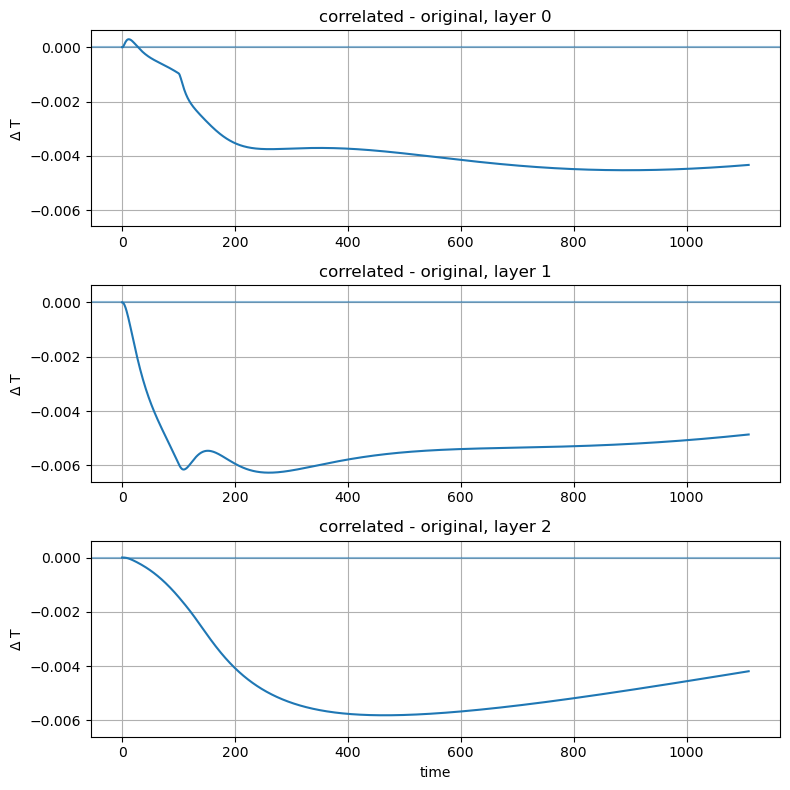

In [164]:
fig, ax = plt.subplots(3,1, figsize = (8,8), sharey=True)

palette = sns.color_palette('pastel')
for i in range(3):
    ax[i].plot(Tckp_all.mean('config').isel(layer = i) - Tog_all.mean('config').isel(layer = i),label = f'{i}')
    ax[i].set_title(f'correlated - original, layer {i}')
    ax[i].axhline(0, alpha = 0.5)
    ax[i].set_ylabel(r'$\Delta$ T')
    ax[i].grid()
    # ax[i].fill_between(Tckp_all.time, 
    #                               np.percentile(Tog_all.isel(layer = i), 10, axis=1), 
    #                               np.percentile(Tog_all.isel(layer = i), 90, axis=1), 
    #                               alpha=0.2,zorder = 2, )
# for i in range(3):
#     ax[1].plot(Tckp_all.mean('config').isel(layer = i),label = i)
#     ax[1].fill_between(Tckp_all.time, 
#                                   np.percentile(Tckp_all.isel(layer = i), 10, axis=1), 
#                                   np.percentile(Tckp_all.isel(layer = i), 90, axis=1), 
#                                   alpha=0.2,zorder = 2, )
# ax[0].set_title('layer 0')
# ax[1].set_title('FaIR_SDckp')
# plt.legend(loc = 'lower right', )


plt.xlabel('time')
plt.tight_layout()

plt.show();plt.close()

In [88]:
cum_emit = np.linspace(10,1000,100) # cumulative emissions for esm-flat10-zec

<Axes: >

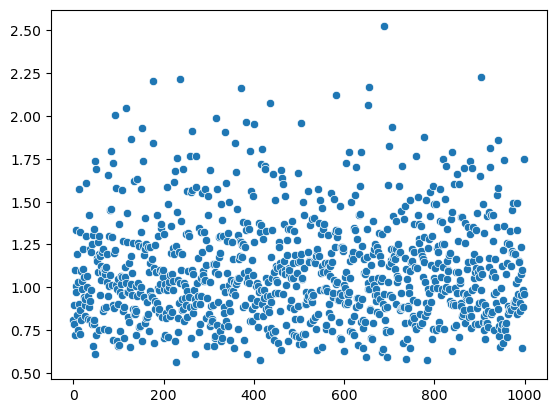

In [89]:
# here calculating TCRE for constant kappa run

tcre1000_SDck = []

for c in range(1000):
    tcre1000_SDck.append(stats.linregress(x = cum_emit,y=Tck[:100,c])[0]*1000)
sns.scatterplot(tcre1000_SDck)

<Axes: >

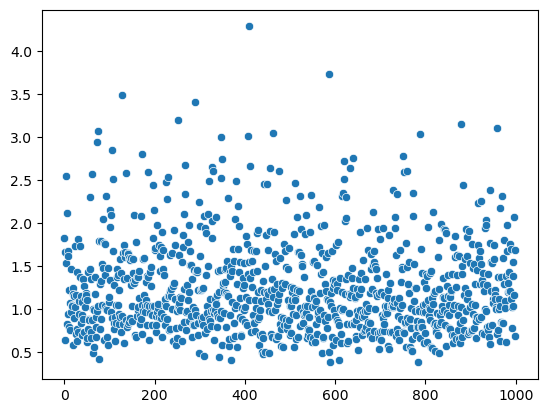

In [90]:
# here calculating TCRE for correlated kappa,psiscalar run

tcre1000_SDckp = []

for c in range(1000):
    tcre1000_SDckp.append(stats.linregress(x = cum_emit,y=Tckp[:100,c])[0]*1000)
sns.scatterplot(tcre1000_SDckp)

<Axes: >

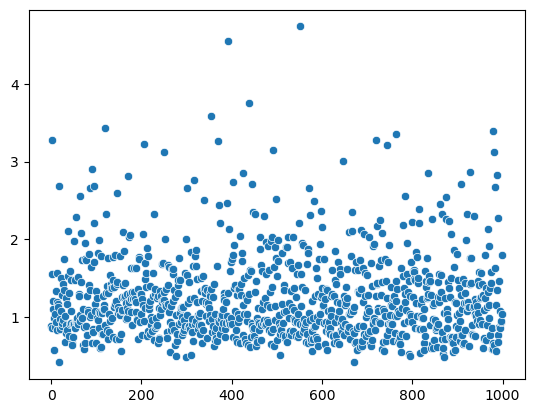

In [91]:
# here calculating TCRE for the SD run

tcre1000_SD = []

for c in range(1000):
    tcre1000_SD.append(stats.linregress(x = cum_emit,y=Tog[:100,c])[0]*1000)
sns.scatterplot(tcre1000_SD)

<Axes: >

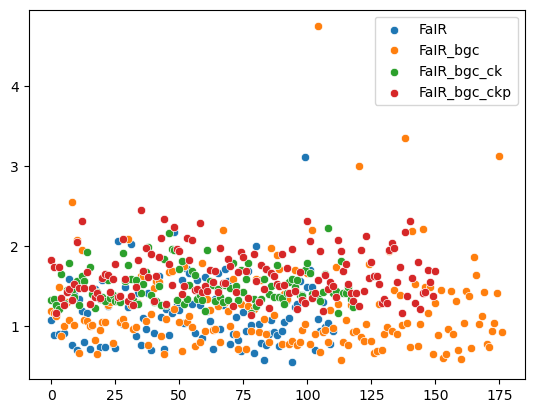

In [92]:
# here calculating TCRE for the fair default run

tcre1000_fair = []

for c in range(1000):
    tcre1000_fair.append(stats.linregress(x = cum_emit,y=Tf[:100,c])[0]*1000)
sns.scatterplot(np.array(tcre1000_fair)[constrained_by_co2T_fair], label = 'FaIR')
sns.scatterplot(np.array(tcre1000_SD)[constrained_by_co2T_SD], label = 'FaIR_bgc')
sns.scatterplot(np.array(tcre1000_SDck)[constrained_by_co2T_SDck], label = 'FaIR_bgc_ck')
sns.scatterplot(np.array(tcre1000_SDckp)[constrained_by_co2T_SDckp],  label = 'FaIR_bgc_ckp')

In [93]:
ZECf = (ds_fair_flat10.temperature.isel(scenario = 0) - tcre1000_fair).isel(time = slice(100,1111))
ZECog = (ds_fairSD_flat10.temperature.isel(scenario = 0).isel(layer=0) - tcre1000_SD).isel(time = slice(100,1111))
ZECck = (ds_fairSDck_flat10.temperature.isel(scenario = 0) - tcre1000_SDck).isel(time = slice(100,1111))
ZECckp = (ds_fairSDckp_flat10.temperature.isel(scenario = 0).isel(layer=0) - tcre1000_SDckp).isel(time = slice(100,1111))

done saving file


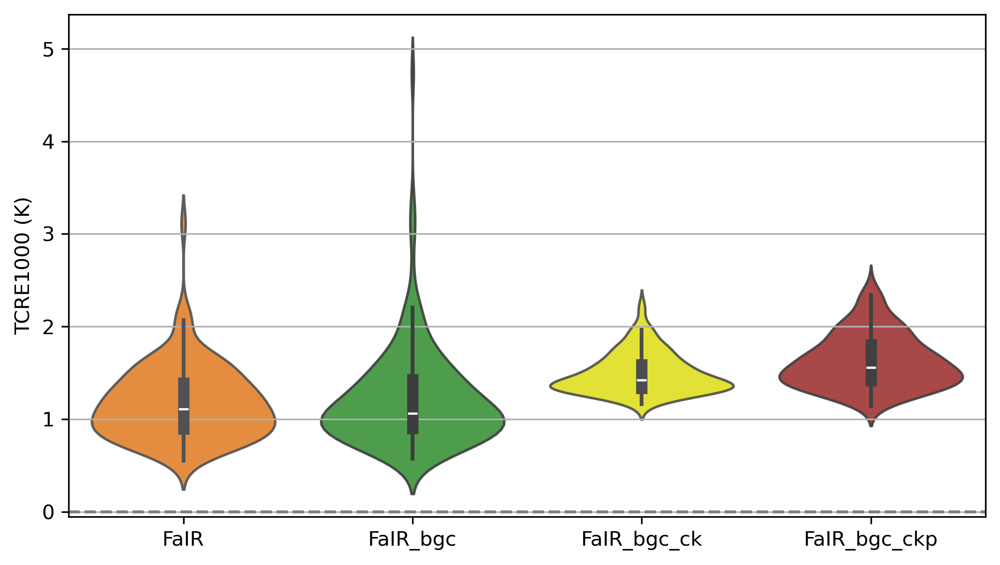

In [94]:
fig, ax = plt.subplots( figsize = (7,4), sharex = True,# sharey = True,
                       dpi = 300, )

constrain_label = 'co2T'

pfair = sns.violinplot(x = 0, y= np.array(tcre1000_fair)[constrained_by_co2T_fair], 
                     # ax = ax[0],
                     alpha = 0.9, color = 'tab:orange')

pSD = sns.violinplot(x = 1, y= np.array(tcre1000_SD)[constrained_by_co2T_SD], 
                     # ax = ax[0],
                     alpha = 0.9, color = 'tab:green')
pSDck = sns.violinplot(x = 2, y= np.array(tcre1000_SDck)[constrained_by_co2T_SDck], 
                     # ax = ax[0],
                     alpha = 0.9, color = 'yellow')
pSDckp = sns.violinplot(x = 3, y= np.array(tcre1000_SDckp)[constrained_by_co2T_SDckp], 
                     # ax = ax[0],
                     alpha = 0.9, color = 'firebrick')
ax.yaxis.grid(True)

ax.set_ylabel('TCRE1000 (K)')
# ax[1].set_ylabel('ZEC 500 (K)')
# ax[2].set_ylabel('ZEC 1000 (K)')

for axis in fig.get_axes():
    axis.axhline(0, ls = 'dashed',c='grey')
    axis.set_xticks([0,1,2,3], ['FaIR', 'FaIR_bgc', 'FaIR_bgc_ck', 'FaIR_bgc_ckp'])

plt.tight_layout();

fpath = 'figures/'
fname = f'TCRE_violin_fair_SD_ck_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


done saving file


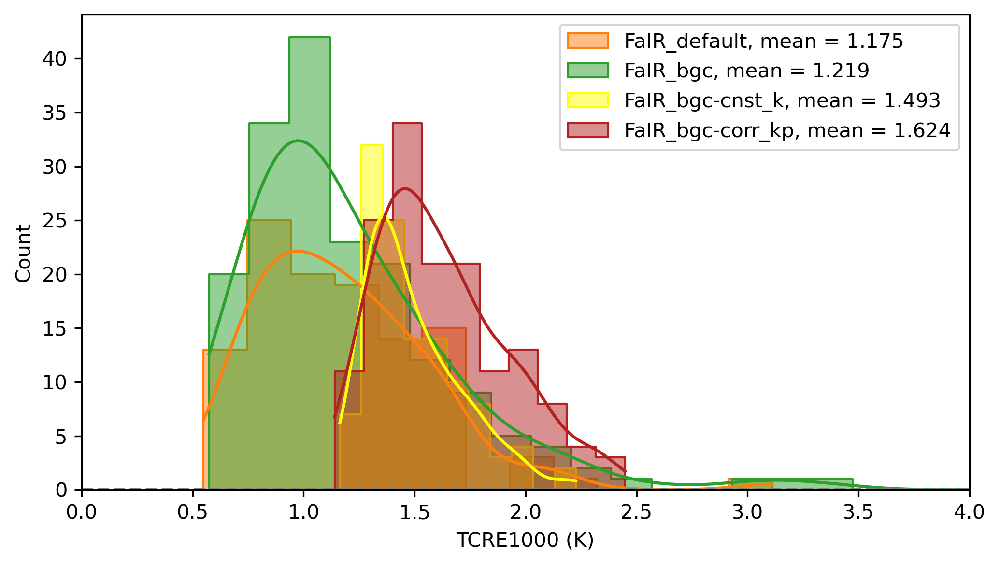

In [117]:
fig, ax = plt.subplots( figsize = (7,4), sharex = True,# sharey = True,
                       dpi = 300, )

constrain_label = 'co2T'

pfair = sns.histplot(np.array(tcre1000_fair)[constrained_by_co2T_fair], kde=True, 
                     # ax = ax[0],
                     fill=True, element="step", color = 'tab:orange', label = f'FaIR_default, mean = {np.round(np.array(tcre1000_fair)[constrained_by_co2T_fair].mean(),3)}', )
pSD = sns.histplot(np.array(tcre1000_SD)[constrained_by_co2T_SD], kde=True, 
                     # ax = ax[0],
                     fill=True, element="step", color = 'tab:green', label = f'FaIR_bgc, mean = {np.round(np.array(tcre1000_SD)[constrained_by_co2T_SD].mean(),3)}', )
pSDck = sns.histplot(np.array(tcre1000_SDck)[constrained_by_co2T_SDck], kde=True, 
                     # ax = ax[0],
                     fill=True, element="step", color = 'yellow', label = f'FaIR_bgc-cnst_k, mean = {np.round(np.array(tcre1000_SDck)[constrained_by_co2T_SDck].mean(),3)}', )
pSDckp = sns.histplot(np.array(tcre1000_SDckp)[constrained_by_co2T_SDckp], kde=True, 
                     # alpha = 0,lw = 0,
                     fill=True, element="step", color = 'firebrick', label = f'FaIR_bgc-corr_kp, mean = {np.round(np.array(tcre1000_SDckp)[constrained_by_co2T_SDckp].mean(),3)}', )



ax.set_xlabel('TCRE1000 (K)')

for axis in fig.get_axes():
    axis.axhline(0, ls = 'dashed',c='grey')
    axis.set_xlim(0, 4)
plt.tight_layout();
plt.legend()

fpath = 'figures/'
fname = f'TCRE_hist_fair_SD_ck_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


In [96]:
np.array(ds_params_fairSDckp['gems_PsiScalar'])[constrained_by_co2T_SDckp]

array([1.391402  , 1.38549464, 1.09161579, 1.56639663, 1.26557262,
       1.20408578, 0.68115738, 0.947829  , 0.9392002 , 0.83792278,
       1.65037522, 0.8185693 , 1.34075244, 1.5228316 , 1.0323216 ,
       1.02655492, 1.40296361, 1.28976967, 1.45664215, 1.36799799,
       0.9352398 , 1.90588571, 1.41585133, 0.81456239, 0.83170359,
       1.61560196, 1.71740778, 1.45426808, 1.06184221, 1.60047238,
       1.33749924, 0.99645723, 1.02451324, 1.31907621, 1.31657803,
       0.72899767, 1.25797694, 0.75666693, 1.0048635 , 1.19895431,
       1.0875881 , 1.02612975, 1.22508466, 1.4174632 , 0.98760276,
       1.33919178, 1.76357711, 0.5683266 , 1.33278394, 1.47771211,
       1.0095368 , 0.78577201, 1.28380606, 1.47889779, 1.2175208 ,
       1.21481356, 0.98964153, 1.14391877, 0.58095111, 0.89346868,
       1.25557913, 1.07569515, 1.00511033, 1.38436868, 1.37107225,
       1.25673347, 1.33056842, 0.98096275, 1.57600014, 1.33869633,
       0.72718214, 1.15518491, 1.28357611, 0.80890916, 1.35163

done saving file


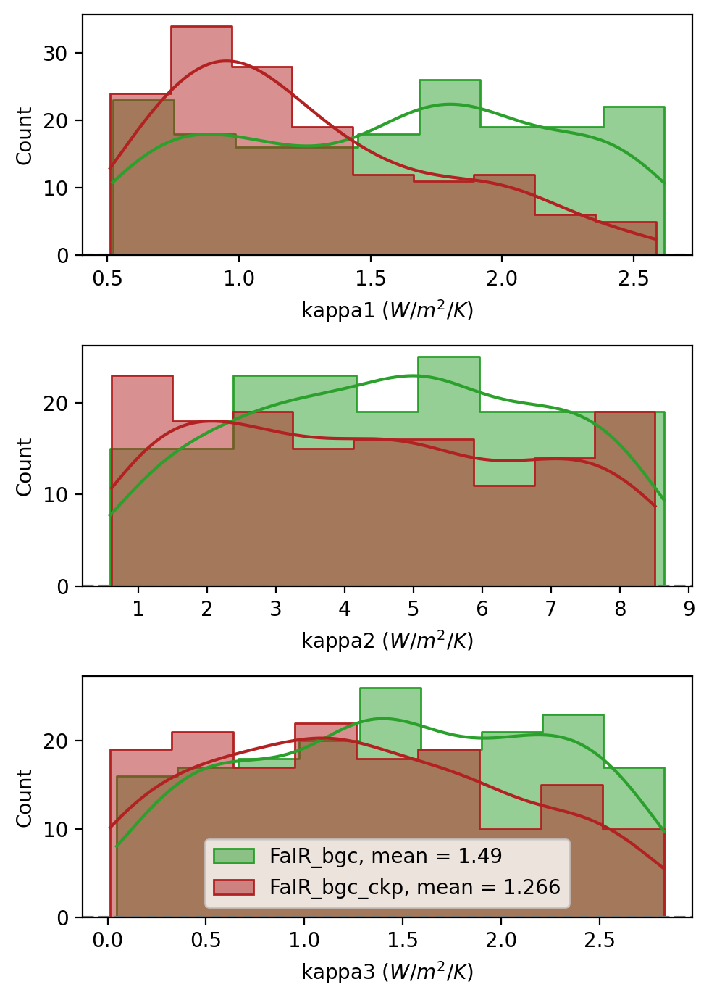

In [98]:
fig, ax = plt.subplots(3,1, figsize = (5,7), sharex = False,# sharey = True,
                       dpi = 200, )

constrain_label = 'co2T'


for i, plot_param in enumerate(['clim_kappa1', 'clim_kappa2','clim_kappa3']):
    p00 = sns.histplot(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD],
                       kde=True, 
                         ax = ax[i],
                         fill=True, element="step", color = 'tab:green', label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', )
    
    p02 = sns.histplot(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp],
                       kde=True, 
                         ax = ax[i],
                         fill=True, element="step", color = 'firebrick', label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', )



ax[0].set_xlabel(r'kappa1 ($W/m^2/K$)')
ax[1].set_xlabel(r'kappa2 ($W/m^2/K$)')
ax[2].set_xlabel(r'kappa3 ($W/m^2/K$)')

for axis in fig.get_axes():
    axis.axhline(0, ls = 'dashed',c='grey')
    # axis.set_xlim(0, 4)
plt.tight_layout();
plt.legend()

fpath = 'figures/'
fname = f'kappas_hist_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


done saving file


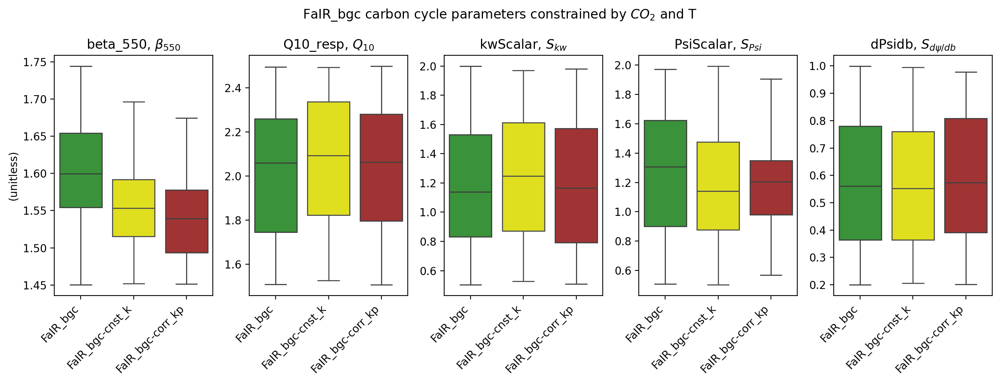

In [120]:
fig, ax = plt.subplots(1,5, figsize = (13,5), sharex = False,# sharey = True,
                       dpi = 200, )

constrain_label = 'co2T'


for i, plot_param in enumerate([#'clim_kappa1', 'clim_kappa2', 'clim_kappa3',
                                'gems_beta_550','gems_Q10_resp', 'gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']):
    
    p00 = sns.boxplot(x = 0, y = (np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD],
                         ax = ax[i],
                         fill=True, color = 'tab:green', showfliers=False,
                      # label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', 
                     )
    p01 = sns.boxplot(x = 1, y = (np.array(ds_params_fairSDck[plot_param])[constrained_by_co2T_SDck])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fairSDck[plot_param])[constrained_by_co2T_SDck],
                         ax = ax[i],
                         fill=True, color = 'yellow', showfliers=False,
                      # label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', 
                     )
    p02 = sns.boxplot(x = 2, y = (np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp],
                         ax = ax[i],
                         fill=True, color = 'firebrick', showfliers=False,
                      # label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', 
                     )
    ax[i].set_title(plot_param[5:])



ax[0].set_ylabel(r'(unitless)')
ax[0].set_title(r'beta_550, $\beta_{550}$')
ax[1].set_title(r'Q10_resp, $Q_{10}$')
ax[2].set_title(r'kwScalar, $S_{kw}$')
ax[3].set_title(r'PsiScalar, $S_{Psi}$')
ax[4].set_title(r'dPsidb, $S_{d\psi/db}$')

for axis in fig.get_axes():
    axis.set_xticks([0,1,2], ['FaIR_bgc','FaIR_bgc-cnst_k', 'FaIR_bgc-corr_kp'], rotation = 45, ha='right')
    
    # axis.axhline(0, ls = 'dashed',c='grey')
    # axis.set_xlim(0, 4)

plt.suptitle(r'FaIR_bgc carbon cycle parameters constrained by $CO_2$ and T')
plt.tight_layout();

fpath = 'figures/'
fname = f'FaIRbgc_box_ccparams_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


done saving file


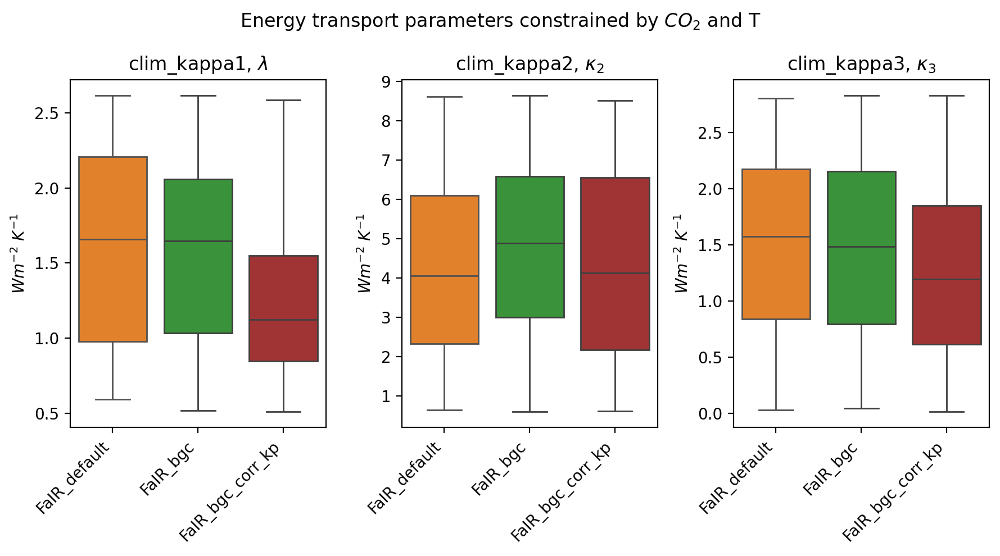

In [122]:
fig, ax = plt.subplots(1,3, figsize = (9,5), sharex = False,# sharey = True,
                       dpi = 200, )

constrain_label = 'co2T'


for i, plot_param in enumerate(['clim_kappa1', 'clim_kappa2','clim_kappa3']):
    p00 = sns.boxplot(x = 0, y = np.array(ds_params_fair[plot_param])[constrained_by_co2T_fair],
                         ax = ax[i],
                         fill=True, color = 'tab:orange', showfliers=False,
                      # label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', 
                     )
    p00 = sns.boxplot(x = 1, y = np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD],
                         ax = ax[i],
                         fill=True, color = 'tab:green', showfliers=False,
                      # label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}',  
                     )
    p03 = sns.boxplot(x = 2, y = np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp],
                         ax = ax[i],
                         fill=True, color = 'firebrick', showfliers=False,
                      # label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', 
                     )



ax[0].set_title(r'clim_kappa1, $\lambda$')
ax[0].set_ylabel(r'$Wm^{-2}~K^{-1}$')
ax[1].set_title(r'clim_kappa2, $\kappa_2$')
ax[1].set_ylabel(r'$Wm^{-2}~K^{-1}$')
ax[2].set_title(r'clim_kappa3, $\kappa_3$')
ax[2].set_ylabel(r'$Wm^{-2}~K^{-1}$')

for axis in fig.get_axes():
    axis.set_xticks([0,1,2], ['FaIR_default','FaIR_bgc', 'FaIR_bgc_corr_kp'], fontsize = 10, rotation = 45, ha='right')
    # axis.axhline(0, ls = 'dashed',c='grey')
    # axis.set_xlim(0, 4)

plt.suptitle(r'Energy transport parameters constrained by $CO_2$ and T')
plt.tight_layout();

fpath = 'figures/'
fname = f'kappas_hist_lambda_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


done saving file


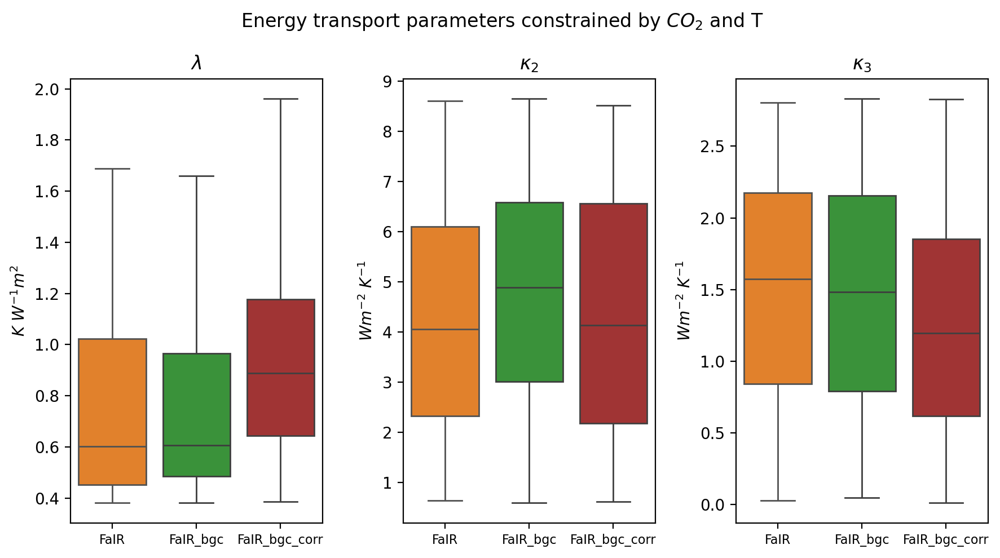

In [2678]:
fig, ax = plt.subplots(1,3, figsize = (9,5), sharex = False,# sharey = True,
                       dpi = 200, )

constrain_label = 'co2T'


for i, plot_param in enumerate(['clim_kappa1', 'clim_kappa2','clim_kappa3']):
    p00 = sns.boxplot(x = 0, y = (np.array(ds_params_fair[plot_param])[constrained_by_co2T_fair])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fair[plot_param])[constrained_by_co2T_fair],
                         ax = ax[i],
                         fill=True, color = 'tab:orange', showfliers=False,
                      # label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', 
                     )
    p01 = sns.boxplot(x = 1, y = (np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD],
                         ax = ax[i],
                         fill=True, color = 'tab:green', showfliers=False,
                      # label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', 
                     )
    p02 = sns.boxplot(x = 2, y = (np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp],
                         ax = ax[i],
                         fill=True, color = 'firebrick', showfliers=False,
                      # label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', 
                     )



ax[0].set_title(r'$\lambda$')
ax[0].set_ylabel(r'$K~W^{-1}m^{2}$')
ax[1].set_title(r'$\kappa_2$')
ax[1].set_ylabel(r'$Wm^{-2}~K^{-1}$')
ax[2].set_title(r'$\kappa_3$')
ax[2].set_ylabel(r'$Wm^{-2}~K^{-1}$')

for axis in fig.get_axes():
    axis.set_xticks([0,1,2], ['FaIR','FaIR_bgc', 'FaIR_bgc_corr'], fontsize = 8)
    # axis.axhline(0, ls = 'dashed',c='grey')
    # axis.set_xlim(0, 4)

plt.suptitle(r'Energy transport parameters constrained by $CO_2$ and T')
plt.tight_layout();

fpath = 'figures/'
fname = f'kappas_box_lambda_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


done saving file


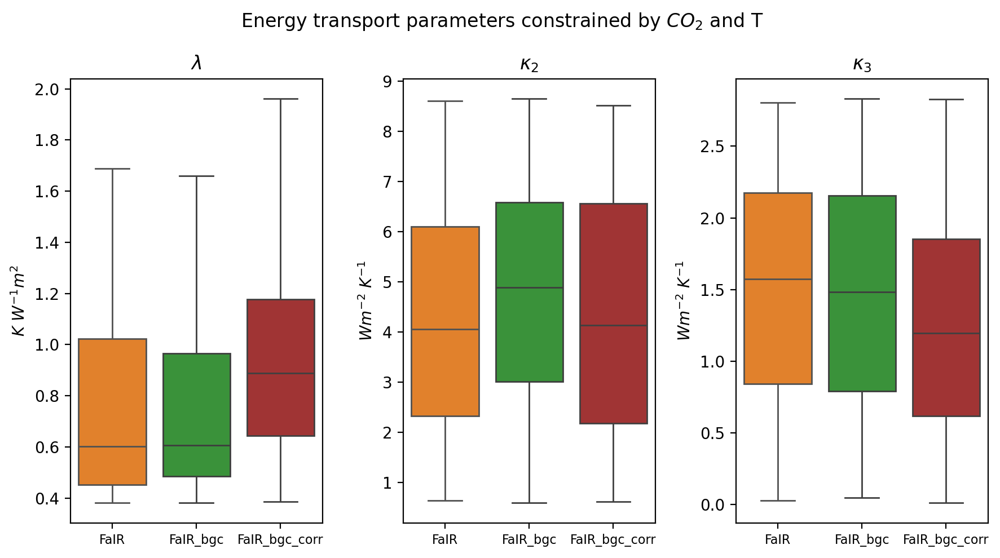

In [2609]:
fig, ax = plt.subplots(1,3, figsize = (9,5), sharex = False,# sharey = True,
                       dpi = 200, )

constrain_label = 'co2T'


for i, plot_param in enumerate(['clim_kappa1', 'clim_kappa2','clim_kappa3']):
    p00 = sns.boxplot(x = 0, y = (np.array(ds_params_fair[plot_param])[constrained_by_co2T_fair])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fair[plot_param])[constrained_by_co2T_fair],
                         ax = ax[i],
                         fill=True, color = 'tab:orange', showfliers=False,
                      # label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', 
                     )
    p01 = sns.boxplot(x = 1, y = (np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD],
                         ax = ax[i],
                         fill=True, color = 'tab:green', showfliers=False,
                      # label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', 
                     )
    p02 = sns.boxplot(x = 2, y = (np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp])**-1 if plot_param == 'clim_kappa1' else np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp],
                         ax = ax[i],
                         fill=True, color = 'firebrick', showfliers=False,
                      # label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', 
                     )



ax[0].set_title(r'$\lambda$')
ax[0].set_ylabel(r'$K~W^{-1}m^{2}$')
ax[1].set_title(r'$\kappa_2$')
ax[1].set_ylabel(r'$Wm^{-2}~K^{-1}$')
ax[2].set_title(r'$\kappa_3$')
ax[2].set_ylabel(r'$Wm^{-2}~K^{-1}$')

for axis in fig.get_axes():
    axis.set_xticks([0,1,2], ['FaIR','FaIR_bgc', 'FaIR_bgc_corr'], fontsize = 8)
    # axis.axhline(0, ls = 'dashed',c='grey')
    # axis.set_xlim(0, 4)

plt.suptitle(r'Energy transport parameters constrained by $CO_2$ and T')
plt.tight_layout();

fpath = 'figures/'
fname = f'kappas_hist_lambda_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


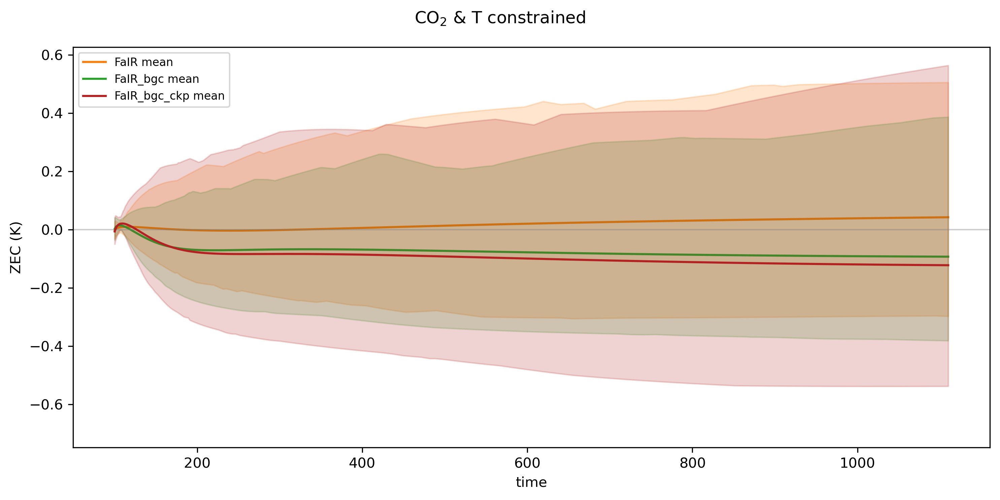

In [123]:
plt.figure(figsize = (10,5), dpi = 300, )


# ZEC CONCENTRATION


plt.plot(ZECf[:,constrained_by_co2T_fair].time, ZECf[:,constrained_by_co2T_fair].mean('config'), label = r'FaIR mean', color = 'tab:orange')
plt.fill_between(ZECf[:,constrained_by_co2T_fair].time, 
                              np.percentile(ZECf[:,constrained_by_co2T_fair], 10, axis=1), 
                              np.percentile(ZECf[:,constrained_by_co2T_fair], 90, axis=1), 
                              alpha=0.2, color = 'tab:orange',zorder = 2, label = r'_FaIR (10th - 90th percentile)')

plt.plot(ZECog[:,constrained_by_co2T_SD].time, ZECog[:,constrained_by_co2T_SD].mean('config'), label = r'FaIR_bgc mean', color = 'tab:green')
plt.fill_between(ZECog[:,constrained_by_co2T_SD].time, 
                              np.percentile(ZECog[:,constrained_by_co2T_SD], 10, axis=1), 
                              np.percentile(ZECog[:,constrained_by_co2T_SD], 90, axis=1), 
                              alpha=0.2, color = 'tab:green',zorder = 2, label = r'_FaIR_bgc (10th - 90th percentile)')

plt.plot(ZECckp[:,constrained_by_co2T_SDckp].time, ZECckp[:,constrained_by_co2T_SDckp].mean('config'), label = r'FaIR_bgc_ckp mean', color = 'firebrick',zorder = 6,
        # alpha = 0
          )
plt.fill_between(ZECckp[:,constrained_by_co2T_SDckp].time, 
                              np.percentile(ZECckp[:,constrained_by_co2T_SDckp], 10, axis=1), 
                              np.percentile(ZECckp[:,constrained_by_co2T_SDckp], 90, axis=1), 
                              # alpha=0.2, 
                   alpha = 0.2,
                   color = 'firebrick',zorder = 2, label = r'_FaIR_bgc corr. $\kappa_3, S_{\psi}$ (10th - 90th percentile)')


plt.plot(ZECck[:,constrained_by_co2T_SDck].time, ZECck[:,constrained_by_co2T_SDck].mean('config'), label = r'_FaIR_bgc const. $\kappa_3$ mean', color = 'yellow',
        alpha = 0,
          )
plt.fill_between(ZECck[:,constrained_by_co2T_SDck].time, 
                              np.percentile(ZECck[:,constrained_by_co2T_SDck], 10, axis=1), 
                              np.percentile(ZECck[:,constrained_by_co2T_SDck], 90, axis=1), 
                              # alpha=0.2,
                 alpha = 0,
                 color = 'yellow',zorder = 2, label = r'_FaIR_bgc const. $\kappa_3$ (10th - 90th percentile)')




# plt.axvline(140, alpha = 0.4, lw = 1, color = 'grey', ls = 'dashed')
# plt.axvline(160, alpha = 0.4, lw = 1, color = 'grey', ls = 'dashed')
# plt.axvline(590, alpha = 0.4, lw = 1, color = 'grey', ls = 'dashed')
# plt.axvline(610, alpha = 0.4, lw = 1, color = 'grey', ls = 'dashed')
# plt.axvline(1090, alpha = 0.4, lw = 1, color = 'grey', ls = 'dashed')
# plt.axvline(1110, alpha = 0.4, lw = 1, color = 'grey', ls = 'dashed')
plt.axhline(0, alpha = 0.4, lw = 1, color = 'grey', )

plt.legend(loc = 'upper left', fontsize = 8)
plt.ylabel(r'ZEC (K)')
plt.xlabel('time')
plt.suptitle('CO$_2$ & T constrained')
plt.tight_layout()
plt.savefig('figures/ZECtseries_T_def_SD_ckp_co2T.png')

plt.show();plt.close()

In [380]:
print('help')

help


In [124]:
# calculating ZEC for constant kappa run

temperature_fair = ds_fair_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec',)]#.isel(config = constraint_SD)                              

ZEC20_fair_ck = temperature_fair.loc[dict(time = np.array([110,130]))].mean('time') - tcre1000_fair
ZEC50_fair_ck = temperature_fair.loc[dict(time = np.array([140,160]))].mean('time') - tcre1000_fair
ZEC100_fair_ck = temperature_fair.loc[dict(time = np.array([190,210]))].mean('time') - tcre1000_fair
ZEC500_fair_ck = temperature_fair.loc[dict(time = np.array([590,610]))].mean('time') - tcre1000_fair
ZEC1000_fair_ck = temperature_fair.loc[dict(time = np.array([1090,1110]))].mean('time') - tcre1000_fair

In [125]:
# calculating ZEC for constant kappa run

temperature_SDck = ds_fairSDck_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec',)]#.isel(config = constraint_SD)                              

ZEC20_SD_ck = temperature_SDck.loc[dict(time = np.array([110,130]))].mean('time') - tcre1000_SDck
ZEC50_SD_ck = temperature_SDck.loc[dict(time = np.array([140,160]))].mean('time') - tcre1000_SDck
ZEC100_SD_ck = temperature_SDck.loc[dict(time = np.array([190,210]))].mean('time') - tcre1000_SDck
ZEC500_SD_ck = temperature_SDck.loc[dict(time = np.array([590,610]))].mean('time') - tcre1000_SDck
ZEC1000_SD_ck = temperature_SDck.loc[dict(time = np.array([1090,1110]))].mean('time') - tcre1000_SDck

In [126]:
# FCO2_20_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([110,130]))].mean('time').isel(scenario = 0)
# FCO2_50_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([140,160]))].mean('time').isel(scenario = 0)
# FCO2_100_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([190,210]))].mean('time').isel(scenario = 0)
# FCO2_500_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([590, 610]))].mean('time').isel(scenario = 0)
# FCO2_1000_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([1090, 1110]))].mean('time').isel(scenario = 0)

In [127]:
ds_fair_flat10['forcing']

<xarray.DataArray 'forcing' (time: 1111, scenario: 1, config: 1000)>
[1111000 values with dtype=float64]
Coordinates:
  * time      (time) int32 0 1 2 3 4 5 6 ... 1104 1105 1106 1107 1108 1109 1110
  * config    (config) int32 0 1 2 3 4 5 6 7 ... 992 993 994 995 996 997 998 999
  * scenario  (scenario) object 'esm-flat10_zec'

In [128]:
FCO2_20_fair = ds_fair_flat10['forcing'].loc[dict(time= np.array([110,130]))].mean('time').isel(scenario = 0)
FCO2_50_fair = ds_fair_flat10['forcing'].loc[dict(time= np.array([140,160]))].mean('time').isel(scenario = 0)
FCO2_100_fair = ds_fair_flat10['forcing'].loc[dict(time= np.array([190,210]))].mean('time').isel(scenario = 0)
FCO2_500_fair = ds_fair_flat10['forcing'].loc[dict(time= np.array([590, 610]))].mean('time').isel(scenario = 0)
FCO2_1000_fair = ds_fair_flat10['forcing'].loc[dict(time= np.array([1090, 1110]))].mean('time').isel(scenario = 0)

In [129]:
FCO2_20_SDck = ds_fairSDck_flat10['co2_forcing'].loc[dict(time= np.array([110,130]))].mean('time').isel(scenario = 0)
FCO2_50_SDck = ds_fairSDck_flat10['co2_forcing'].loc[dict(time= np.array([140,160]))].mean('time').isel(scenario = 0)
FCO2_100_SDck = ds_fairSDck_flat10['co2_forcing'].loc[dict(time= np.array([190,210]))].mean('time').isel(scenario = 0)
FCO2_500_SDck = ds_fairSDck_flat10['co2_forcing'].loc[dict(time= np.array([590, 610]))].mean('time').isel(scenario = 0)
FCO2_1000_SDck = ds_fairSDck_flat10['co2_forcing'].loc[dict(time= np.array([1090, 1110]))].mean('time').isel(scenario = 0)

In [130]:
def ZEC(data, N, TCRE):
    ZEC = data.loc[dict(time=np.array([100+N-10, 100+N+10]))].mean('time') - TCRE
    return ZEC
def Tmean(data, N):
    T = data.loc[dict(time=np.array([100+N-10, 100+N+10]))].mean('time')
    return T

In [131]:
# calculating ZEC for original run

temperature_SD = ds_fairSD_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec',layer = 0)]#.isel(config = constraint_SD)            

ZEC20_SD = ZEC(temperature_SD, 20, tcre1000_SD)
ZEC50_SD = ZEC(temperature_SD, 50, tcre1000_SD)
ZEC100_SD = ZEC(temperature_SD, 100, tcre1000_SD)
ZEC500_SD = ZEC(temperature_SD, 500, tcre1000_SD)
ZEC1000_SD = ZEC(temperature_SD, 1000, tcre1000_SD)
# ZEC1000_SD_ckp = temperature_SDckp.loc[dict(time = np.array([100+990,100+1010]))].mean('time') - tcre1000_SDckp

In [132]:
FCO2_20_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([110,130]))].mean('time').isel(scenario = 0)
FCO2_50_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([140,160]))].mean('time').isel(scenario = 0)
FCO2_100_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([190,210]))].mean('time').isel(scenario = 0)
FCO2_500_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([590, 610]))].mean('time').isel(scenario = 0)
FCO2_1000_SD = ds_fairSD_flat10['co2_forcing'].loc[dict(time= np.array([1090, 1110]))].mean('time').isel(scenario = 0)

In [133]:
# calculating ZEC for correlated kappa run

temperature_SDckp = ds_fairSDckp_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec',layer = 0)]#.isel(config = constraint_SD)                              

ZEC20_SD_ckp = ZEC(temperature_SDckp, 20, tcre1000_SDckp)
ZEC50_SD_ckp = ZEC(temperature_SDckp, 50, tcre1000_SDckp)
ZEC100_SD_ckp = ZEC(temperature_SDckp, 100, tcre1000_SDckp)
ZEC500_SD_ckp = ZEC(temperature_SDckp, 500, tcre1000_SDckp)
ZEC1000_SD_ckp = ZEC(temperature_SDckp, 1000, tcre1000_SDckp)
# ZEC1000_SD_ckp = temperature_SDckp.loc[dict(time = np.array([100+990,100+1010]))].mean('time') - tcre1000_SDckp

In [134]:
FCO2_20_SDckp = ds_fairSDckp_flat10['co2_forcing'].loc[dict(time= np.array([110,130]))].mean('time').isel(scenario = 0)
FCO2_50_SDckp = ds_fairSDckp_flat10['co2_forcing'].loc[dict(time= np.array([140,160]))].mean('time').isel(scenario = 0)
FCO2_100_SDckp = ds_fairSDckp_flat10['co2_forcing'].loc[dict(time= np.array([190,210]))].mean('time').isel(scenario = 0)
FCO2_500_SDckp = ds_fairSDckp_flat10['co2_forcing'].loc[dict(time= np.array([590, 610]))].mean('time').isel(scenario = 0)
FCO2_1000_SDckp = ds_fairSDckp_flat10['co2_forcing'].loc[dict(time= np.array([1090, 1110]))].mean('time').isel(scenario = 0)

In [135]:
TL0_fair = ds_fair_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec')]#.isel(config = constraint_SD)             

TL0_ckp = ds_fairSDckp_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec',layer = 0)]#.isel(config = constraint_SD)
TL1_ckp = ds_fairSDckp_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec',layer = 1)]#.isel(config = constraint_SD)         
TL2_ckp = ds_fairSDckp_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec',layer = 2)]#.isel(config = constraint_SD)            

TL0_ck = ds_fairSDck_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec')]#.isel(config = constraint_SD)             
# TL1_ck = ds_fairSDck_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec')]#.isel(config = constraint_SD)         
# TL2_ck = ds_fairSDck_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec')]#.isel(config = constraint_SD)                         

TL0 = ds_fairSD_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec', layer = 0)]#.isel(config = constraint_SD)             
TL1 = ds_fairSD_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec', layer = 1)]#.isel(config = constraint_SD)         
TL2 = ds_fairSD_flat10.temperature.loc[dict(scenario = 'esm-flat10_zec', layer = 2)]#.isel(config = constraint_SD)                         

In [136]:
TL0_20_SD = Tmean(TL0, 20)
TL0_50_SD = Tmean(TL0, 50)
TL0_100_SD = Tmean(TL0, 100)
TL0_500_SD = Tmean(TL0, 500)
TL0_1000_SD = Tmean(TL0, 1000)


TL0_20_fair = Tmean(TL0_fair, 20)
TL0_50_fair = Tmean(TL0_fair, 50)
TL0_100_fair = Tmean(TL0_fair, 100)
TL0_500_fair = Tmean(TL0_fair, 500)
TL0_1000_fair = Tmean(TL0_fair, 1000)


TL0_20_SD_ck = Tmean(TL0_ck, 20)
TL0_50_SD_ck = Tmean(TL0_ck, 50)
TL0_100_SD_ck = Tmean(TL0_ck, 100)
TL0_500_SD_ck = Tmean(TL0_ck, 500)
TL0_1000_SD_ck = Tmean(TL0_ck, 1000)


TL0_20_SD_ckp = Tmean(TL0_ckp, 20)
TL0_50_SD_ckp = Tmean(TL0_ckp, 50)
TL0_100_SD_ckp = Tmean(TL0_ckp, 100)
TL0_500_SD_ckp = Tmean(TL0_ckp, 500)
TL0_1000_SD_ckp = Tmean(TL0_ckp, 1000)

TL1_20_SD_ckp = Tmean(TL1_ckp, 20)
TL1_50_SD_ckp = Tmean(TL1_ckp, 50)
TL1_100_SD_ckp = Tmean(TL1_ckp, 100)
TL1_500_SD_ckp = Tmean(TL1_ckp, 500)
TL1_1000_SD_ckp = Tmean(TL1_ckp, 1000)

TL2_20_SD_ckp = Tmean(TL2_ckp, 20)
TL2_50_SD_ckp = Tmean(TL2_ckp, 50)
TL2_100_SD_ckp = Tmean(TL2_ckp, 100)
TL2_500_SD_ckp = Tmean(TL2_ckp, 500)
TL2_1000_SD_ckp = Tmean(TL2_ckp, 1000)

Text(0.5, 1.0, 'correlated kappa3:psiscalar')

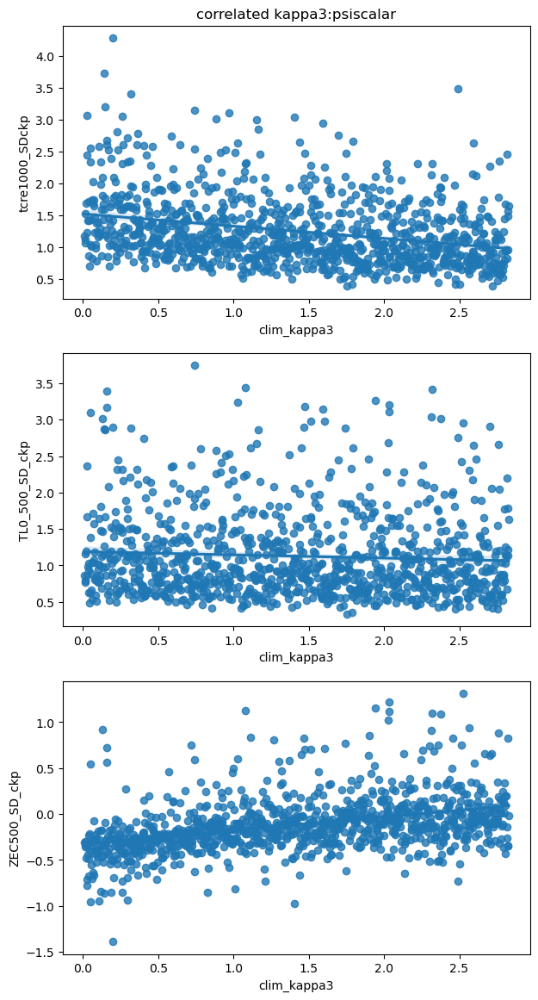

In [137]:
fig, ax = plt.subplots(3,1, figsize = (7,14))
# sns.regplot(x = ds_params_fairSDck['gems_PsiScalar'], y = tcre1000_SDck, ax = ax[0,0]);ax[0,0].set_ylabel('tcre1000_SDckp', )
sns.regplot(x = ds_params_fairSDckp['clim_kappa3'], y = tcre1000_SDckp, ax = ax[0]);ax[0].set_ylabel('tcre1000_SDckp', )

# sns.regplot(x = ds_params_fairSDck['gems_PsiScalar'], y = TL0_500_SD_ck, ax = ax[1,0]);ax[1,0].set_ylabel('TL0_500_SD_ckp', )
sns.regplot(x = ds_params_fairSDckp['clim_kappa3'], y = TL0_500_SD_ckp, ax = ax[1]);ax[1].set_ylabel('TL0_500_SD_ckp', )

# sns.regplot(x = ds_params_fairSDck['gems_PsiScalar'], y = ZEC500_SD_ck, ax = ax[2,0]);ax[2,0].set_ylabel('ZEC500_SD_ckp', )
sns.regplot(x = ds_params_fairSDckp['clim_kappa3'], y = ZEC500_SD_ckp, ax = ax[2]);ax[2].set_ylabel('ZEC500_SD_ckp', )

ax[0].set_title('correlated kappa3:psiscalar')

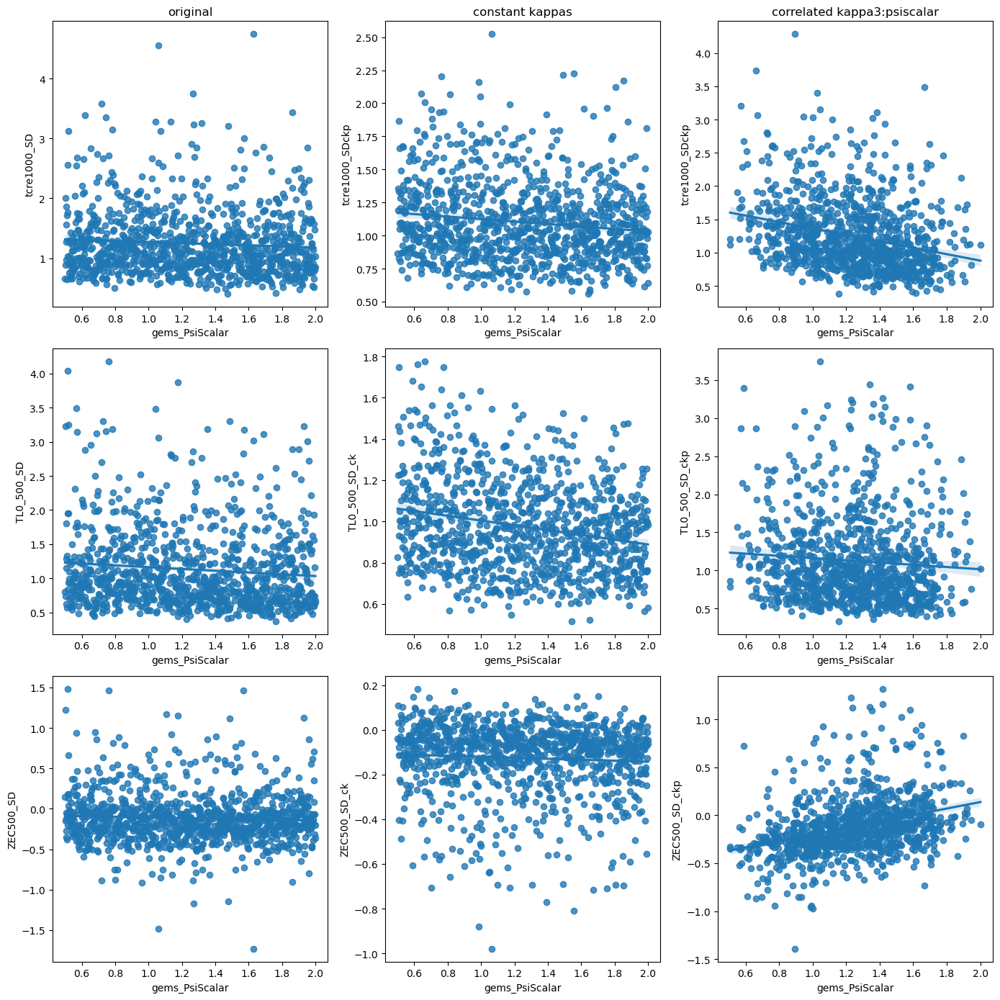

In [138]:
fig, ax = plt.subplots(3,3, figsize = (14,14))
sns.regplot(x = ds_params_fairSD['gems_PsiScalar'], y = tcre1000_SD, ax = ax[0,0]);ax[0,0].set_ylabel('tcre1000_SD', )
sns.regplot(x = ds_params_fairSDck['gems_PsiScalar'], y = tcre1000_SDck, ax = ax[0,1]);ax[0,1].set_ylabel('tcre1000_SDckp', )
sns.regplot(x = ds_params_fairSDckp['gems_PsiScalar'], y = tcre1000_SDckp, ax = ax[0,2]);ax[0,2].set_ylabel('tcre1000_SDckp', )

sns.regplot(x = ds_params_fairSD['gems_PsiScalar'], y = TL0_500_SD, ax = ax[1,0]);ax[1,0].set_ylabel('TL0_500_SD', )
sns.regplot(x = ds_params_fairSDck['gems_PsiScalar'], y = TL0_500_SD_ck, ax = ax[1,1]);ax[1,1].set_ylabel('TL0_500_SD_ck', )
sns.regplot(x = ds_params_fairSDckp['gems_PsiScalar'], y = TL0_500_SD_ckp, ax = ax[1,2]);ax[1,2].set_ylabel('TL0_500_SD_ckp', )

sns.regplot(x = ds_params_fairSD['gems_PsiScalar'], y = ZEC500_SD, ax = ax[2,0]);ax[2,0].set_ylabel('ZEC500_SD', )
sns.regplot(x = ds_params_fairSDck['gems_PsiScalar'], y = ZEC500_SD_ck, ax = ax[2,1]);ax[2,1].set_ylabel('ZEC500_SD_ck', )
sns.regplot(x = ds_params_fairSDckp['gems_PsiScalar'], y = ZEC500_SD_ckp, ax = ax[2,2]);ax[2,2].set_ylabel('ZEC500_SD_ckp', )

ax[0,0].set_title('original');
ax[0,1].set_title('constant kappas');
ax[0,2].set_title('correlated kappa3:psiscalar')
plt.tight_layout();
plt.show();plt.close()

<Axes: xlabel='gems_PsiScalar', ylabel='temperature'>

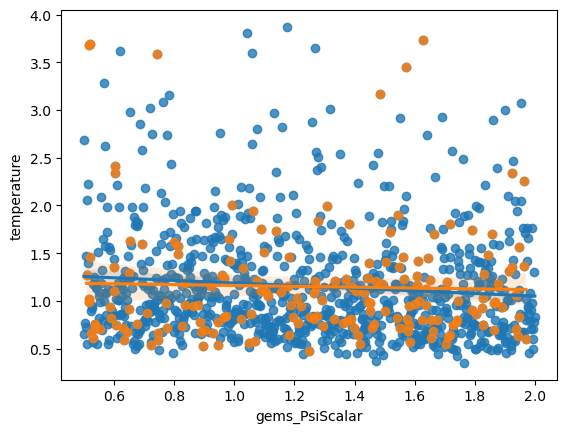

In [139]:
x = ds_params_fairSD['gems_PsiScalar']
y = TL0_100_SD

x_data = ds_params_fairSD['gems_PsiScalar'][np.array(constrained_by_co2T_SD).astype(int)]
y_data = TL0_100_SD[np.array(constrained_by_co2T_SD).astype(int)]

sns.regplot(x = x, y = y)
sns.regplot(x = x_data, y = y_data)

<Axes: xlabel='gems_PsiScalar', ylabel='temperature'>

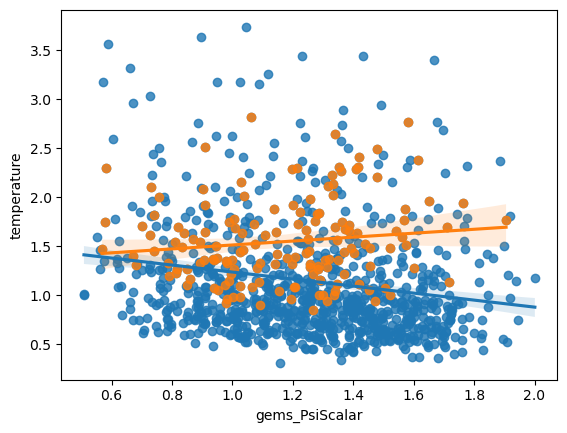

In [140]:
x = ds_params_fairSDckp['gems_PsiScalar']
y = TL0_100_SD_ckp

x_data = ds_params_fairSDckp['gems_PsiScalar'][np.array(constrained_by_co2T_SDckp).astype(int)]
y_data = TL0_100_SD_ckp[np.array(constrained_by_co2T_SDckp).astype(int)]

sns.regplot(x = x, y = y)
sns.regplot(x = x_data, y = y_data)

<Axes: xlabel='gems_PsiScalar', ylabel='clim_kappa1'>

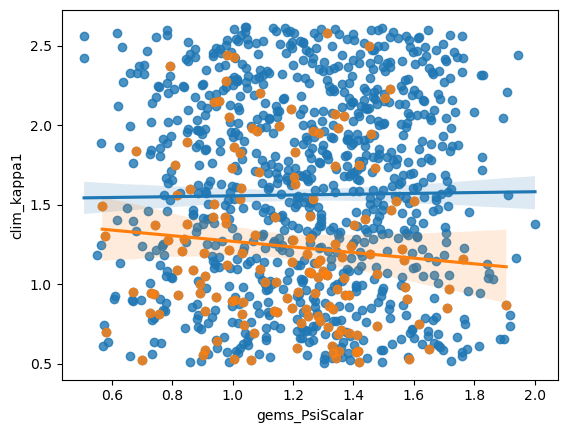

In [141]:
x = ds_params_fairSDckp['gems_PsiScalar']
y = ds_params_fairSDckp['clim_kappa1']

x_data = ds_params_fairSDckp['gems_PsiScalar'][np.array(constrained_by_co2T_SDckp).astype(int)]
y_data = ds_params_fairSDckp['clim_kappa1'][np.array(constrained_by_co2T_SDckp).astype(int)]

sns.regplot(x = x, y = y)
sns.regplot(x = x_data, y = y_data)

In [142]:
df_fair = params_fair
df_fair.head()

df_SD = params_fairSD
df_SD.head()

,Unnamed: 0,clim_gamma,clim_c1,clim_c2,clim_c3,clim_kappa1,clim_kappa2,clim_kappa3,clim_epsilon,clim_sigma_eta,...,fscale_Light absorbing particles on snow and ice,fscale_Contrails,fscale_CO2,cc_co2_concentration_1750,gems_beta_550,gems_Q10_resp,gems_kwScalar,gems_PsiScalar,gems_dPsidb,gems_patm0
0,0,12.778643,5.038750,61.839486,75.864413,0.833950,2.820524,2.018407,1.621496,1.232903,...,3.697161,0.478276,0.817073,273.500568,1.676022,1.599176,1.780284,1.738878,0.656844,285.634319
1,1,15.918183,2.031412,9.592643,112.932836,0.797827,5.407259,2.436824,0.561042,0.139803,...,-0.598942,0.302202,1.194867,278.502030,1.461000,2.471610,0.991562,1.041827,0.864131,285.400708
2,2,1.212660,4.632160,58.196424,184.485234,1.744708,6.519484,0.065019,0.781892,0.912238,...,0.671166,1.817690,0.815879,278.737801,1.638901,1.932569,1.738893,1.997808,0.495008,286.292633
3,3,9.863682,4.420282,56.473843,301.284210,0.856066,4.377888,0.944175,0.617143,0.906194,...,4.263082,0.789416,0.879969,278.533302,1.499753,1.979020,1.853771,0.857460,0.545944,286.335562
4,4,12.355787,4.052604,14.789512,123.556528,0.848744,3.586451,2.438933,2.142365,2.069682,...,-0.897709,0.915876,1.040301,277.774187,1.684121,2.310212,1.324104,1.033145,0.528442,284.857860


In [166]:
df_SDck = params_fairSDck
df_SDck.head()

,Unnamed: 0,clim_gamma,clim_c1,clim_c2,clim_c3,clim_kappa1,clim_kappa2,clim_kappa3,clim_epsilon,clim_sigma_eta,...,fscale_Light absorbing particles on snow and ice,fscale_Contrails,fscale_CO2,cc_co2_concentration_1750,gems_beta_550,gems_Q10_resp,gems_kwScalar,gems_PsiScalar,gems_dPsidb,gems_patm0
0,0,25.519196,2.530800,41.274960,227.087597,1.551037,4.724335,1.437031,1.292563,1.181191,...,2.496578,0.732793,0.831365,275.099484,1.629686,2.338088,1.696589,1.020710,0.287038,285.606955
1,1,25.459277,7.738142,48.655564,159.721691,1.551037,4.724335,1.437031,1.070762,2.097333,...,0.527255,0.165489,0.834787,276.490112,1.460638,1.628927,1.356265,1.204326,0.717351,287.509467
2,2,11.663903,2.367403,14.139887,195.483179,1.551037,4.724335,1.437031,2.081036,1.550035,...,3.005555,0.295560,0.940272,282.475722,1.612830,1.919749,0.661512,1.623947,0.972847,285.279676
3,3,13.033295,4.991198,38.767458,338.480125,1.551037,4.724335,1.437031,1.144404,2.191926,...,-0.598987,0.828696,1.080881,273.299549,1.660363,1.932242,0.548479,0.822196,0.339793,286.632995
4,4,15.141245,7.570447,66.129610,168.570384,1.551037,4.724335,1.437031,1.114476,1.761578,...,2.165083,0.312259,0.822430,275.605899,1.669298,1.760658,0.530000,1.113099,0.689907,285.129449


In [167]:
df_fair['tau1'] = np.nan; df_fair['tau1'][constrained_by_co2T_fair] = curvefit_params_3xp_fairco2T['tau1_total_decarb']
df_fair['tau2'] = np.nan; df_fair['tau2'][constrained_by_co2T_fair] = curvefit_params_3xp_fairco2T['tau2_total_decarb']
df_fair['tau3'] = np.nan; df_fair['tau3'][constrained_by_co2T_fair] = curvefit_params_3xp_fairco2T['tau3_total_decarb']

df_SD['tau1'] = np.nan; df_SD['tau1'][constrained_by_co2T_SD]=curvefit_params_3xp_SD100co2T['tau1_total_decarb']
df_SD['tau2'] = np.nan; df_SD['tau2'][constrained_by_co2T_SD]=curvefit_params_3xp_SD100co2T['tau2_total_decarb']
df_SD['tau3'] = np.nan; df_SD['tau3'][constrained_by_co2T_SD]=curvefit_params_3xp_SD100co2T['tau3_total_decarb']

df_SDck['tau1'] = np.nan; df_SDck['tau1'][constrained_by_co2T_SDck]=curvefit_params_3xp_SDck100co2T['tau1_total_decarb']
df_SDck['tau2'] = np.nan; df_SDck['tau2'][constrained_by_co2T_SDck]=curvefit_params_3xp_SDck100co2T['tau2_total_decarb']
df_SDck['tau3'] = np.nan; df_SDck['tau3'][constrained_by_co2T_SDck]=curvefit_params_3xp_SDck100co2T['tau3_total_decarb']

df_SDckp['tau1'] = np.nan; df_SDckp['tau1'][constrained_by_co2T_SDckp]=curvefit_params_3xp_SDckp100co2T['tau1_total_decarb']
df_SDckp['tau2'] = np.nan; df_SDckp['tau2'][constrained_by_co2T_SDckp]=curvefit_params_3xp_SDckp100co2T['tau2_total_decarb']
df_SDckp['tau3'] = np.nan; df_SDckp['tau3'][constrained_by_co2T_SDckp]=curvefit_params_3xp_SDckp100co2T['tau3_total_decarb']

/tmp/ipykernel_83215/2439025870.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fair['tau1'] = np.nan; df_fair['tau1'][constrained_by_co2T_fair] = curvefit_params_3xp_fairco2T['tau1_total_decarb']
/tmp/ipykernel_83215/2439025870.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_fair['tau2'] = np.nan; df_fair['tau2'][constrained_by_co2T_fair] = curvefit_params_3xp_fairco2T['tau2_total_decarb']
/tmp/ipykernel_83215/2439025870.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_

done saving file


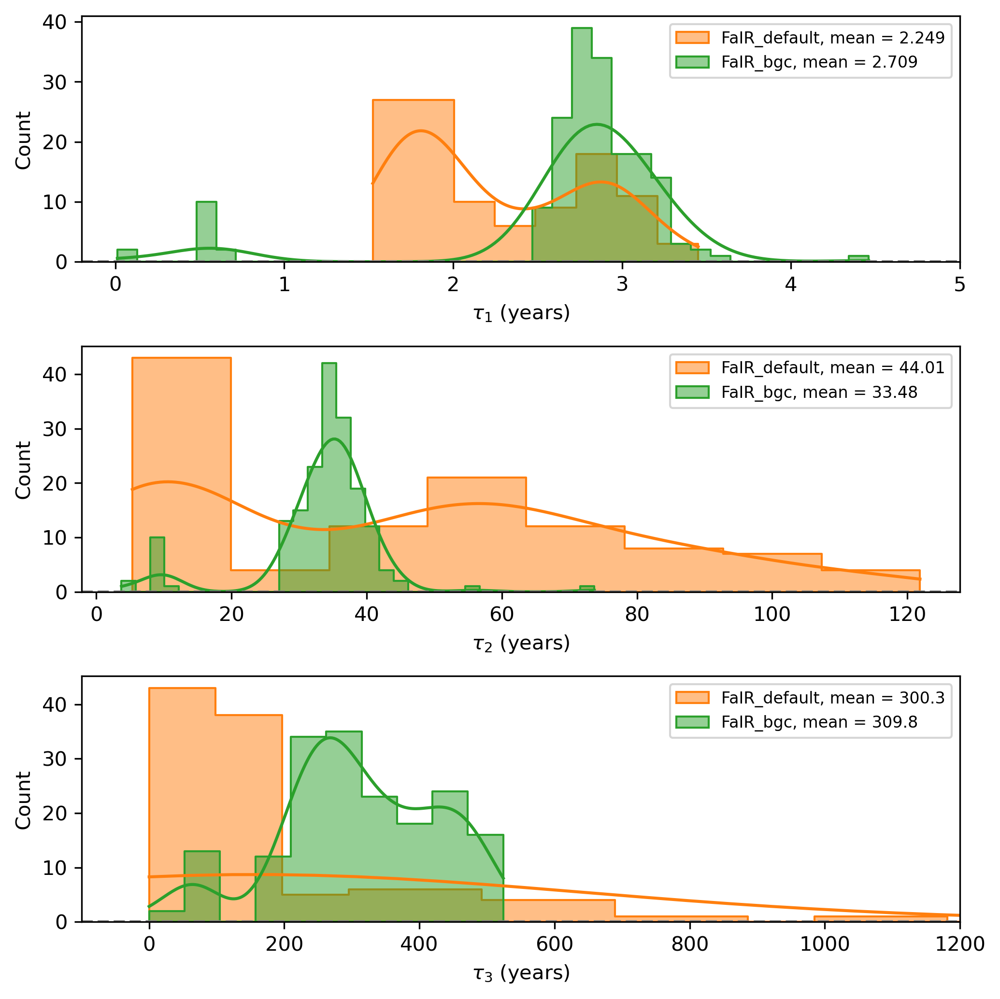

In [173]:
fig, ax = plt.subplots(3,1, figsize = (7,7), 
                       dpi = 300, )

constrain_label = 'co2T'
decimals = {'tau1' : 3,
            'tau2' : 2,
            'tau3' : 1,}

for i, tau in enumerate(['tau1', 'tau2','tau3']):
    p00 = sns.histplot(np.array(df_fair[tau])[constrained_by_co2T_fair],
                       kde=True, 
                         ax = ax[i],
                         fill=True, element="step", color = 'tab:orange', label = f'FaIR_default, mean = {np.round(np.array(df_fair[tau])[constrained_by_co2T_fair].mean(),decimals[tau])}', )

    p00 = sns.histplot(np.array(df_SD[tau])[constrained_by_co2T_SD],
                       kde=True, 
                         ax = ax[i],
                         fill=True, element="step", color = 'tab:green', label = f'FaIR_bgc, mean = {np.round(np.array(df_SD[tau])[constrained_by_co2T_SD].mean(),decimals[tau])}', )
    
    # p02 = sns.histplot(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp],
    #                    kde=True, 
    #                      ax = ax[i],
    #                      fill=True, element="step", color = 'firebrick', label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', )



ax[0].set_xlabel(r'$\tau_1$ (years)')
ax[1].set_xlabel(r'$\tau_2$ (years)')
ax[2].set_xlabel(r'$\tau_3$ (years)')
ax[0].set_xlim(-.2,5)
ax[2].set_xlim(-100,1200)


for axis in fig.get_axes():
    axis.axhline(0, ls = 'dashed',c='grey')
    axis.legend(fontsize = 8)
    # axis.set_xlim(0, 4)
plt.tight_layout();


fpath = 'figures/'
fname = f'hist_tau_3xp'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()

In [174]:
ds_params_fair

<xarray.Dataset>
Dimensions:                                           (dim_0: 1000, config: 1000)
Coordinates:
  * dim_0                                             (dim_0) int64 0 1 ... 999
  * config                                            (config) int32 0 1 ... 999
Data variables: (12/47)
    Unnamed: 0                                        (dim_0) int64 0 1 ... 999
    clim_gamma                                        (dim_0) float64 2.446 ....
    clim_c1                                           (dim_0) float64 2.453 ....
    clim_c2                                           (dim_0) float64 33.29 ....
    clim_c3                                           (dim_0) float64 337.2 ....
    clim_kappa1                                       (dim_0) float64 0.8883 ...
    ...                                                ...
    fscale_solar_amplitude                            (dim_0) float64 0.7393 ...
    fscale_solar_trend                                (dim_0) float64 -0.0087...
    fscale_Light absorbing particles on snow and ice  (dim_0) float64 1.609 ....
    fscale_Contrails                                  (dim_0) float64 0.3404 ...
    fscale_CO2                                        (dim_0) float64 0.8605 ...
    cc_co2_concentration_1750                         (dim_0) float64 283.2 ....

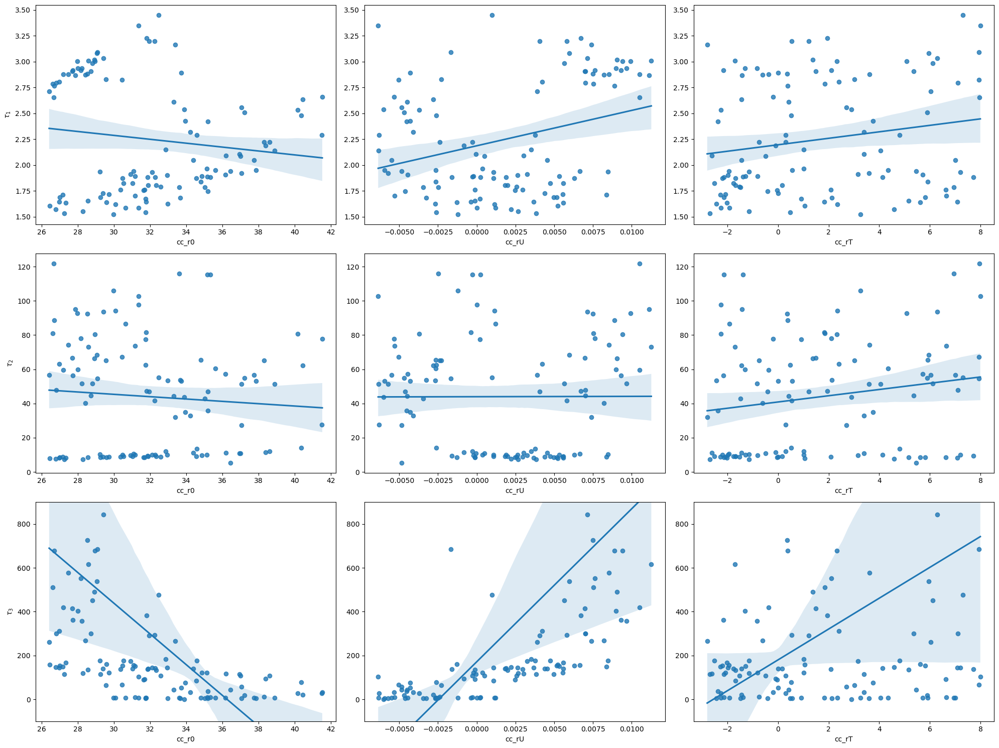

In [175]:
fig, ax = plt.subplots(3, 3, figsize = (20,15), )


for i , param in enumerate(['cc_r0', 'cc_rU', 'cc_rT',]):
    sns.regplot(x = ds_params_fair[param][np.array(constrained_by_co2T_fair).astype(int)], 
                    y = np.array(df_fair['tau1'])[constrained_by_co2T_fair], ax = ax[0,i])
    sns.regplot(x = ds_params_fair[param][np.array(constrained_by_co2T_fair).astype(int)], 
                    y = np.array(df_fair['tau2'])[constrained_by_co2T_fair], ax = ax[1,i])
    sns.regplot(x = ds_params_fair[param][np.array(constrained_by_co2T_fair).astype(int)], 
                    y = np.array(df_fair['tau3'])[constrained_by_co2T_fair], ax = ax[2,i]);ax[2,i].set_ylim(-100,900)
    ax[0,0].set_ylabel(rf'$\tau_1$')
    ax[1,0].set_ylabel(rf'$\tau_2$')
    ax[2,0].set_ylabel(rf'$\tau_3$')

plt.tight_layout();plt.show();plt.close()

done saving file


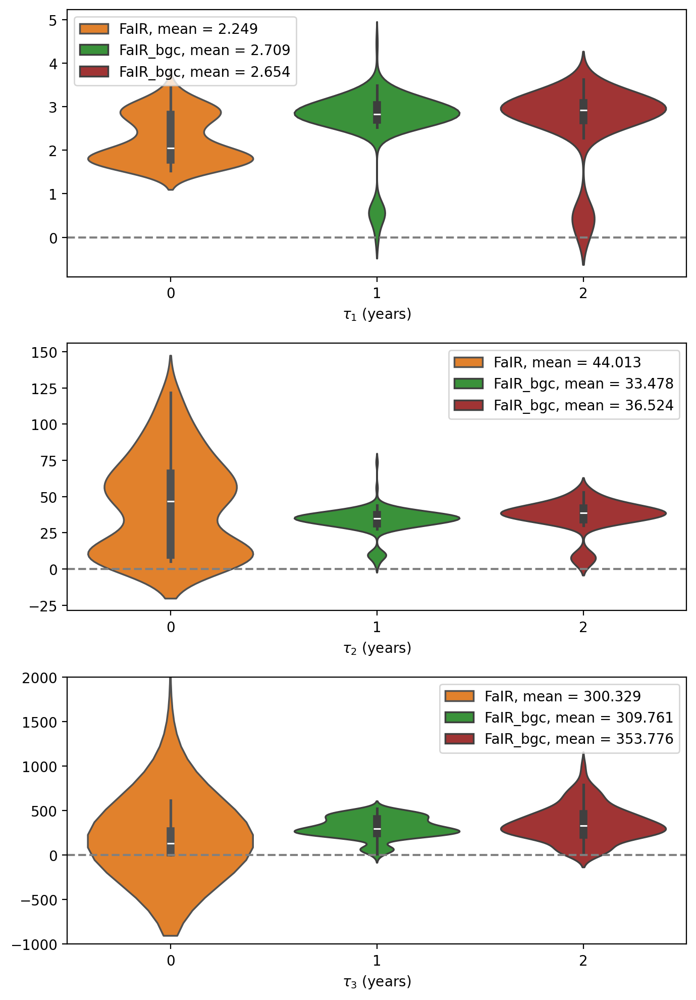

In [176]:
fig, ax = plt.subplots(3,1, figsize = (7,10), 
                       dpi = 200, )

constrain_label = 'co2T'


for i, tau in enumerate(['tau1', 'tau2','tau3']):
    p00 = sns.violinplot(x = 0, y = np.array(df_fair[tau])[constrained_by_co2T_fair],
                       # kde=True, 
                         ax = ax[i],#density_norm = 'count',
                         # fill=True, element="step",
                         color = 'tab:orange', label = f'FaIR, mean = {np.round(np.array(df_fair[tau])[constrained_by_co2T_fair].mean(),3)}', )

    p01 = sns.violinplot(x = 1, y = np.array(df_SD[tau])[constrained_by_co2T_SD],
                       # kde=True, 
                         ax = ax[i],#density_norm = 'count',
                         # fill=True, element="step",
                         color = 'tab:green', label = f'FaIR_bgc, mean = {np.round(np.array(df_SD[tau])[constrained_by_co2T_SD].mean(),3)}', )
    
    p02 = sns.violinplot(x = 2, y = np.array(df_SDckp[tau])[constrained_by_co2T_SDckp],
                       # kde=True, 
                         ax = ax[i],#density_norm = 'count',
                         # fill=True, element="step",
                         color = 'firebrick', label = f'FaIR_bgc, mean = {np.round(np.array(df_SDckp[tau])[constrained_by_co2T_SDckp].mean(),3)}', )



ax[0].set_xlabel(r'$\tau_1$ (years)')
ax[1].set_xlabel(r'$\tau_2$ (years)')
ax[2].set_xlabel(r'$\tau_3$ (years)')
ax[2].set_ylim(-1000,2000)


for axis in fig.get_axes():
    axis.axhline(0, ls = 'dashed',c='grey')
    # axis.set_xlim(0, 4)
plt.tight_layout();
plt.legend()

fpath = 'figures/'
fname = f'kappas_violin_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


In [177]:
# df_SD['tau1'] = np.nan; df_SD['tau1'][top100_co2_SD]=curvefit_params_3xp_SD100['tau1_total_decarb']
# df_SD['tau2'] = np.nan; df_SD['tau2'][top100_co2_SD]=curvefit_params_3xp_SD100['tau2_total_decarb']
# df_SD['tau3'] = np.nan; df_SD['tau3'][top100_co2_SD]=curvefit_params_3xp_SD100['tau3_total_decarb']

# df_SDck['tau1'] = np.nan; df_SDck['tau1'][top100_co2_SDck]=curvefit_params_3xp_SDck100['tau1_total_decarb']
# df_SDck['tau2'] = np.nan; df_SDck['tau2'][top100_co2_SDck]=curvefit_params_3xp_SDck100['tau2_total_decarb']
# df_SDck['tau3'] = np.nan; df_SDck['tau3'][top100_co2_SDck]=curvefit_params_3xp_SDck100['tau3_total_decarb']

# df_SDckp['tau1'] = np.nan; df_SDckp['tau1'][top100_co2_SDckp]=curvefit_params_3xp_SDckp100['tau1_total_decarb']
# df_SDckp['tau2'] = np.nan; df_SDckp['tau2'][top100_co2_SDckp]=curvefit_params_3xp_SDckp100['tau2_total_decarb']
# df_SDckp['tau3'] = np.nan; df_SDckp['tau3'][top100_co2_SDckp]=curvefit_params_3xp_SDckp100['tau3_total_decarb']

done saving file


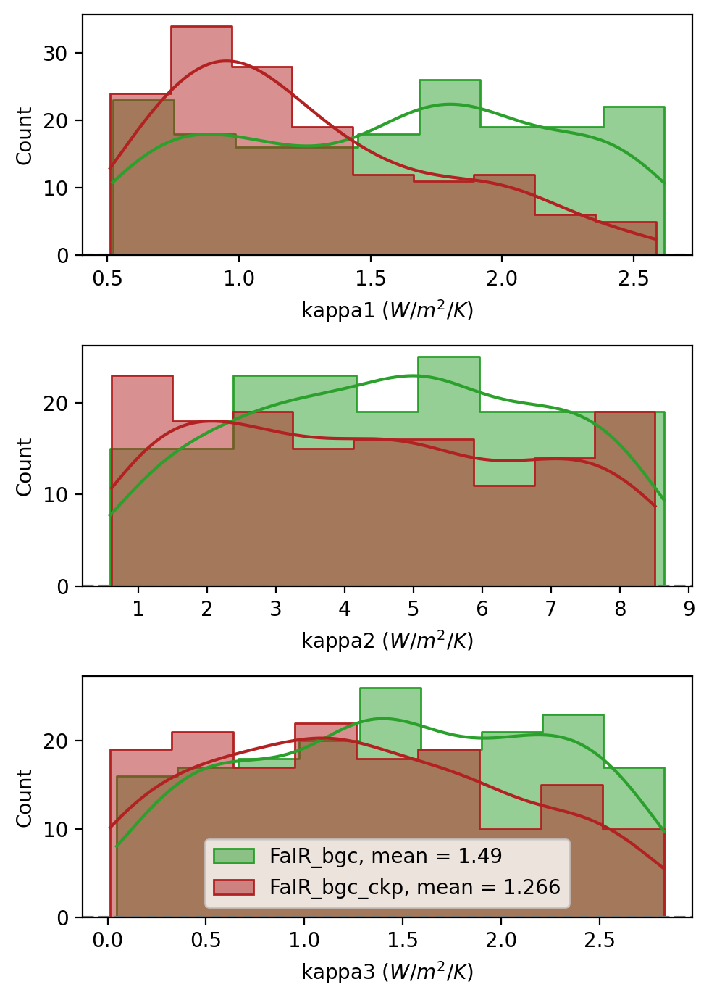

In [178]:
fig, ax = plt.subplots(3,1, figsize = (5,7), sharex = False,# sharey = True,
                       dpi = 200, )

constrain_label = 'co2T'


for i, plot_param in enumerate(['clim_kappa1', 'clim_kappa2','clim_kappa3']):
    p00 = sns.histplot(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD],
                       kde=True, 
                         ax = ax[i],
                         fill=True, element="step", color = 'tab:green', label = f'FaIR_bgc, mean = {np.round(np.array(ds_params_fairSD[plot_param])[constrained_by_co2T_SD].mean(),3)}', )
    
    p02 = sns.histplot(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp],
                       kde=True, 
                         ax = ax[i],
                         fill=True, element="step", color = 'firebrick', label = f'FaIR_bgc_ckp, mean = {np.round(np.array(ds_params_fairSDckp[plot_param])[constrained_by_co2T_SDckp].mean(),3)}', )



ax[0].set_xlabel(r'kappa1 ($W/m^2/K$)')
ax[1].set_xlabel(r'kappa2 ($W/m^2/K$)')
ax[2].set_xlabel(r'kappa3 ($W/m^2/K$)')

for axis in fig.get_axes():
    axis.axhline(0, ls = 'dashed',c='grey')
    # axis.set_xlim(0, 4)
plt.tight_layout();
plt.legend()

fpath = 'figures/'
fname = f'kappas_hist_ckp_co2T'
# save the plot
fig.savefig(fpath+fname +'.png', bbox_inches='tight')
print('done saving file')

plt.show();plt.close()


In [179]:
df_SD['TCRE1000'] = tcre1000_SD
df_SD['ZEC20'] = ZEC20_SD.values
df_SD['ZEC50'] = ZEC50_SD.values
df_SD['ZEC100'] = ZEC100_SD.values
df_SD['ZEC500'] = ZEC500_SD.values
df_SD['ZEC1000'] = ZEC1000_SD.values
df_SD['Fco2_20'] = FCO2_20_SD.values
df_SD['Fco2_50'] = FCO2_50_SD.values
df_SD['Fco2_100'] = FCO2_100_SD.values
df_SD['Fco2_500'] = FCO2_500_SD.values
df_SD['Fco2_1000'] = FCO2_1000_SD.values

df_SD['TL0_20'] = TL0_20_SD.values;
df_SD['TL0_50'] = TL0_50_SD.values;
df_SD['TL0_100'] = TL0_100_SD.values;
df_SD['TL0_500'] = TL0_500_SD.values;
df_SD['TL0_1000'] = TL0_1000_SD.values;

In [180]:
df_fair['TCRE1000'] = tcre1000_fair
df_fair['ZEC20'] = ZEC20_fair_ck.values
df_fair['ZEC50'] = ZEC50_fair_ck.values
df_fair['ZEC100'] = ZEC100_fair_ck.values
df_fair['ZEC500'] = ZEC500_fair_ck.values
df_fair['ZEC1000'] = ZEC1000_fair_ck.values
df_fair['Fco2_20'] = FCO2_20_fair.values
df_fair['Fco2_50'] = FCO2_50_fair.values
df_fair['Fco2_100'] = FCO2_100_fair.values
df_fair['Fco2_500'] = FCO2_500_fair.values
df_fair['Fco2_1000'] = FCO2_1000_fair.values
df_fair['TL0_20'] = TL0_20_fair.values;
df_fair['TL0_50'] = TL0_50_fair.values;
df_fair['TL0_100'] = TL0_100_fair.values;
df_fair['TL0_500'] = TL0_500_fair.values;
df_fair['TL0_1000'] = TL0_1000_fair.values;

In [181]:
df_SDck['TCRE1000'] = tcre1000_SDck
df_SDck['ZEC20'] = ZEC20_SD_ck.values
df_SDck['ZEC50'] = ZEC50_SD_ck.values
df_SDck['ZEC100'] = ZEC100_SD_ck.values
df_SDck['ZEC500'] = ZEC500_SD_ck.values
df_SDck['ZEC1000'] = ZEC1000_SD_ck.values
df_SDck['Fco2_20'] = FCO2_20_SDck.values
df_SDck['Fco2_50'] = FCO2_50_SDck.values
df_SDck['Fco2_100'] = FCO2_100_SDck.values
df_SDck['Fco2_500'] = FCO2_500_SDck.values
df_SDck['Fco2_1000'] = FCO2_1000_SDck.values
df_SDck['TL0_20'] = TL0_20_SD_ck.values;
df_SDck['TL0_50'] = TL0_50_SD_ck.values;
df_SDck['TL0_100'] = TL0_100_SD_ck.values;
df_SDck['TL0_500'] = TL0_500_SD_ck.values;
df_SDck['TL0_1000'] = TL0_1000_SD_ck.values;

In [182]:
print('ZEC100 = ', df_SDckp['ZEC100'][constrained_by_co2T_SDckp].mean())
print('TCRE1000 = ', df_SDckp['TCRE1000'][constrained_by_co2T_SDckp].mean())

ZEC100 =  -0.07683337127617743
TCRE1000 =  1.623956181894998


In [183]:
plt.cm.viridis(params_fairSDck['clim_kappa3'].values)

array([[0.993248, 0.906157, 0.143936, 1.      ],
       [0.993248, 0.906157, 0.143936, 1.      ],
       [0.993248, 0.906157, 0.143936, 1.      ],
       ...,
       [0.993248, 0.906157, 0.143936, 1.      ],
       [0.993248, 0.906157, 0.143936, 1.      ],
       [0.993248, 0.906157, 0.143936, 1.      ]])

In [184]:
norm = Normalize(vmin=params_fairSDckp['clim_kappa3'][constrained_by_co2T_SDckp].min(), vmax=params_fairSDckp['clim_kappa3'][constrained_by_co2T_SDckp].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

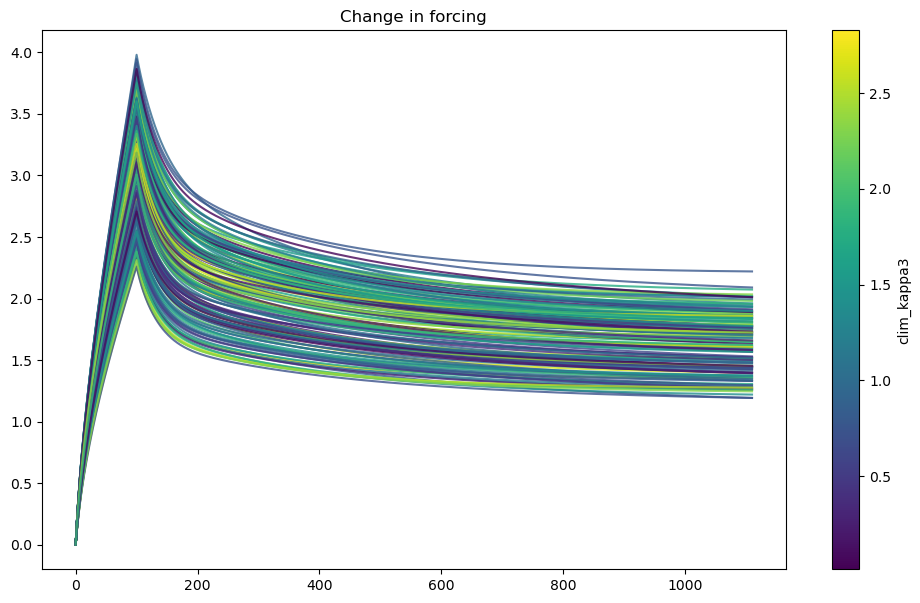

In [185]:
fig, ax = plt.subplots(figsize = (12,7))
for i in constrained_by_co2T_SDckp:
    param = params_fairSDckp['clim_kappa3'][i]
    ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = i),
             color=scalar_map.to_rgba(param), alpha = 0.8)
cb = plt.colorbar(scalar_map, ax = ax)
cb.set_label('clim_kappa3')
ax.set_title(f'Change in forcing')
plt.show();plt.close()

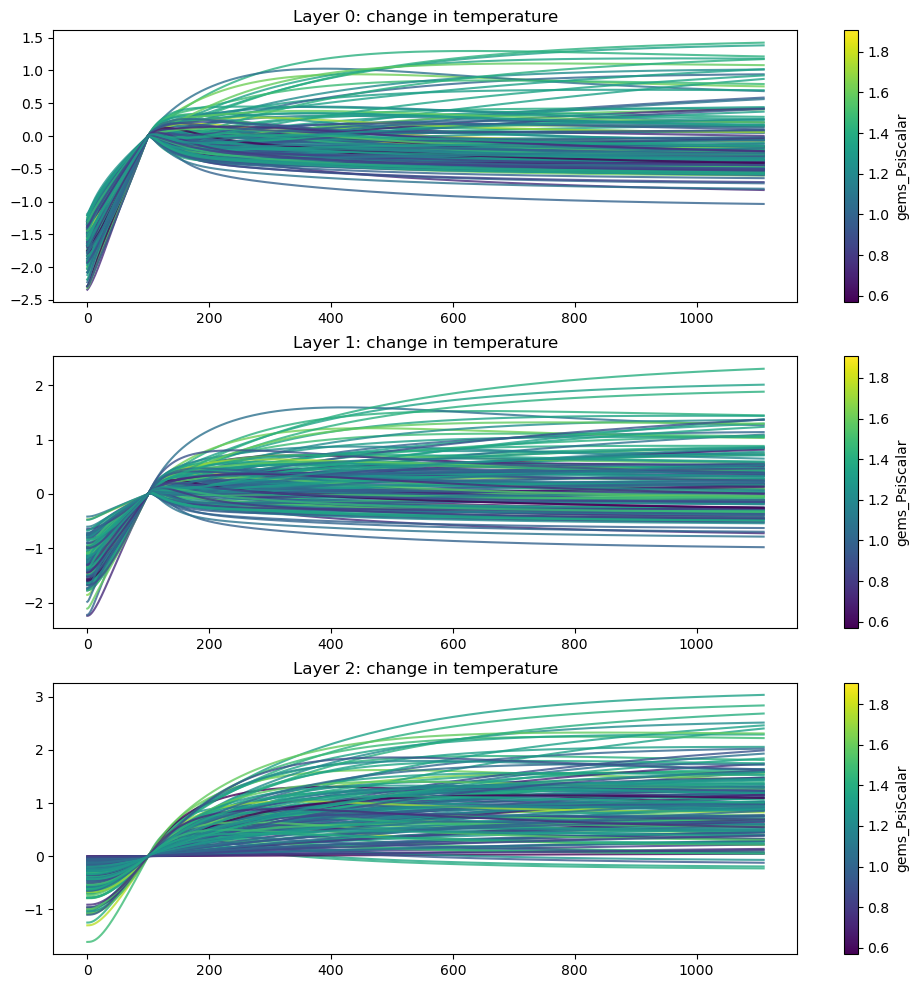

In [186]:
plot_param = 'gems_PsiScalar'

norm = Normalize(vmin=params_fairSDckp[plot_param][constrained_by_co2T_SDckp].min(), vmax=params_fairSDckp[plot_param][constrained_by_co2T_SDckp].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

fig, ax = plt.subplots(3,1, figsize = (12,12))
for l in range(3):
    for i in constrained_by_co2T_SDckp:
        param = params_fairSDckp[plot_param][i]
        ax[l].plot(((ds_fairSDckp_flat10['temperature']-ds_fairSDckp_flat10['temperature'][100]).isel(layer = l)).isel(scenario = 0, config = i),
                 color=scalar_map.to_rgba(param), alpha = 0.8)
    cb = plt.colorbar(scalar_map, ax = ax[l])
    cb.set_label(plot_param)
    ax[l].set_title(f'Layer {l}: change in temperature')
    # ax[l].set_xlim(0,200)

plt.show();plt.close()

Starting individual comparisons of high and low kappa3 & PsiScalar

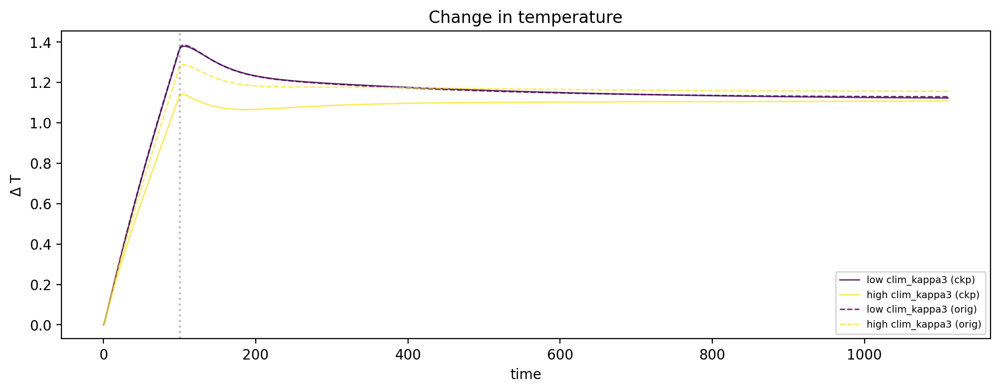

In [1485]:
fig, ax = plt.subplots(figsize = (12,4), dpi = 200)

norm = Normalize(vmin=params_fairSDckp['clim_kappa3'].min(), vmax=params_fairSDckp['clim_kappa3'].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

kmin = params_fairSDckp['clim_kappa3'].min()
T_low = ds_fairSDckp_flat10['temperature'].isel(scenario = 0, layer = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] < params_fairSDckp['clim_kappa3'].mean()].index.values)
ax.plot(T_low.mean('config'), color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low clim_kappa3 (ckp)', lw = 1)
# ax.fill_between(T_low.time, 
#                               np.percentile(T_low, 10, axis=1), 
#                               np.percentile(T_low, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmin), zorder = 2, label = 'low clim_kappa3 (ckp) (10th - 90th percentile)')


kmax = params_fairSDckp['clim_kappa3'].max()
T_high = ds_fairSDckp_flat10['temperature'].isel(scenario = 0, layer = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] > params_fairSDckp['clim_kappa3'].mean()].index.values)
ax.plot(T_high.mean('config'), color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high clim_kappa3 (ckp)', lw = 1)

# ax.fill_between(T_high.time, 
#                               np.percentile(T_high, 10, axis=1), 
#                               np.percentile(T_high, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmax), zorder = 2, label = 'high clim_kappa3 (ckp) (10th - 90th percentile)')

###################### ORIGINAL ######

norm = Normalize(vmin=params_fairSD['clim_kappa3'].min(), vmax=params_fairSD['clim_kappa3'].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

kmin = params_fairSD['clim_kappa3'].min()
T_low = ds_fairSD_flat10['temperature'].isel(scenario = 0, 
                                             layer =0,
                                             config = params_fairSD.loc[params_fairSD['clim_kappa3'] < params_fairSD['clim_kappa3'].mean()].index.values)
ax.plot(T_low.mean('config'), color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low clim_kappa3 (orig)', lw = 1, ls = 'dashed')
# ax.fill_between(T_low.time, 
#                               np.percentile(T_low, 10, axis=1), 
#                               np.percentile(T_low, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmin), zorder = 2, label = 'low clim_kappa3 (orig) (10th - 90th percentile)')


kmax = params_fairSD['clim_kappa3'].max()
T_high = ds_fairSD_flat10['temperature'].isel(scenario = 0, 
                                              layer =0,
                                              config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] > params_fairSD['clim_kappa3'].mean()].index.values)
ax.plot(T_high.mean('config'), color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high clim_kappa3 (orig)', lw = 1, ls = 'dashed')

# ax.fill_between(T_high.time, 
#                               np.percentile(T_high, 10, axis=1), 
#                               np.percentile(T_high, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmax), zorder = 2, label = 'high clim_kappa3 (orig) (10th - 90th percentile)')
####################### ORIGINAL ######



ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.legend(fontsize = 7, loc = 'lower right')
ax.set_ylabel(r'$\Delta$ T');ax.set_xlabel(r'time')
ax.set_title(f'Change in temperature')
plt.show();plt.close()

In [1169]:
temp_high = ds_fairSDckp_flat10['temperature'].isel(scenario = 0, layer = 0, config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2_SD)).values

i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSDckp_flat10['temperature'].isel(scenario = 0, layer = 0)[:,i_high_co2]
temp_high_co2

<xarray.DataArray 'temperature' (time: 1111, config: 221)>
[245531 values with dtype=float64]
Coordinates:
  * time      (time) int32 0 1 2 3 4 5 6 ... 1104 1105 1106 1107 1108 1109 1110
  * config    (config) int32 4 5 6 13 15 22 25 ... 955 958 964 968 981 982 991
    layer     int32 0
    scenario  <U14 'esm-flat10_zec'

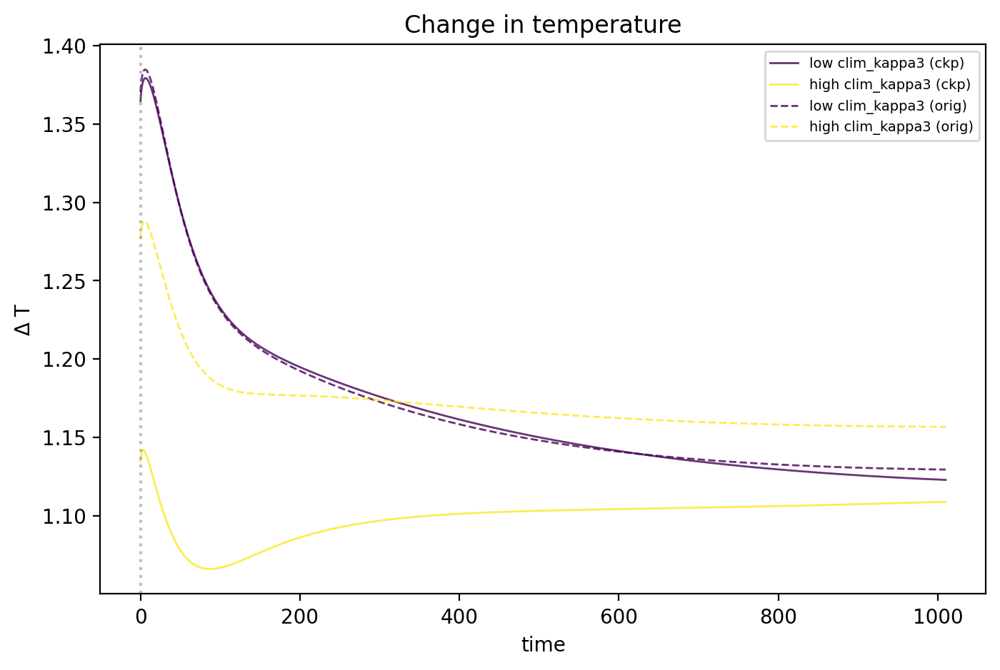

In [1484]:
fig, ax = plt.subplots(figsize = (8,5), dpi = 200)

plot_param = 'clim_kappa3'

norm = Normalize(vmin=params_fairSDckp[plot_param].min(), vmax=params_fairSDckp[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

kmin = params_fairSDckp[plot_param].min()
T_low = ds_fairSDckp_flat10['temperature'].isel(scenario = 0, layer = 0, config = params_fairSDckp.loc[params_fairSDckp[plot_param] < params_fairSDckp[plot_param].mean()].index.values)
ax.plot(T_low.mean('config')[100:], color=scalar_map.to_rgba(kmin), alpha = 0.8, label = f'low {plot_param} (ckp)', lw = 1)
# ax.fill_between(T_low.time, 
#                               np.percentile(T_low, 10, axis=1), 
#                               np.percentile(T_low, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmin), zorder = 2, label = 'low clim_kappa3 (ckp) (10th - 90th percentile)')


kmax = params_fairSDckp[plot_param].max()
T_high = ds_fairSDckp_flat10['temperature'].isel(scenario = 0, layer = 0, config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
ax.plot(T_high.mean('config')[100:], color=scalar_map.to_rgba(kmax), alpha = 0.8, label = f'high {plot_param} (ckp)', lw = 1)

# ax.fill_between(T_high.time, 
#                               np.percentile(T_high, 10, axis=1), 
#                               np.percentile(T_high, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmax), zorder = 2, label = 'high clim_kappa3 (ckp) (10th - 90th percentile)')

###################### ORIGINAL ######

norm = Normalize(vmin=params_fairSD[plot_param].min(), vmax=params_fairSD[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

kmin = params_fairSD[plot_param].min()
T_low = ds_fairSD_flat10['temperature'].isel(scenario = 0, layer = 0, config = params_fairSD.loc[params_fairSD[plot_param] < params_fairSD[plot_param].mean()].index.values)
ax.plot(T_low.mean('config')[100:], color=scalar_map.to_rgba(kmin), alpha = 0.8, label = f'low {plot_param} (orig)', lw = 1, ls = 'dashed')
# ax.fill_between(T_low.time, 
#                               np.percentile(T_low, 10, axis=1), 
#                               np.percentile(T_low, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmin), zorder = 2, label = 'low clim_kappa3 (orig) (10th - 90th percentile)')


kmax = params_fairSD[plot_param].max()
T_high = ds_fairSD_flat10['temperature'].isel(scenario = 0, layer = 0, config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSD[plot_param].mean()].index.values)
ax.plot(T_high.mean('config')[100:], color=scalar_map.to_rgba(kmax), alpha = 0.8, label = f'high {plot_param} (orig)', lw = 1, ls = 'dashed')

# ax.fill_between(T_high.time, 
#                               np.percentile(T_high, 10, axis=1), 
#                               np.percentile(T_high, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmax), zorder = 2, label = 'high clim_kappa3 (orig) (10th - 90th percentile)')
####################### ORIGINAL ######


ax.axvline(0, c = 'grey', ls = 'dotted', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.savefig(f'figures/PCC_EBM_{plot_param}_timeseries.png', dpi = 300)
plt.legend(fontsize = 7, loc = 'best')
ax.set_ylabel(r'$\Delta$ T');ax.set_xlabel(r'time')
ax.set_title(f'Change in temperature')
plt.show();plt.close()

In [1064]:
C_per_CO2 = 12.011 / 44.009; print(C_per_CO2)
PgC_per_ppm = 2.12

0.27292144788565975


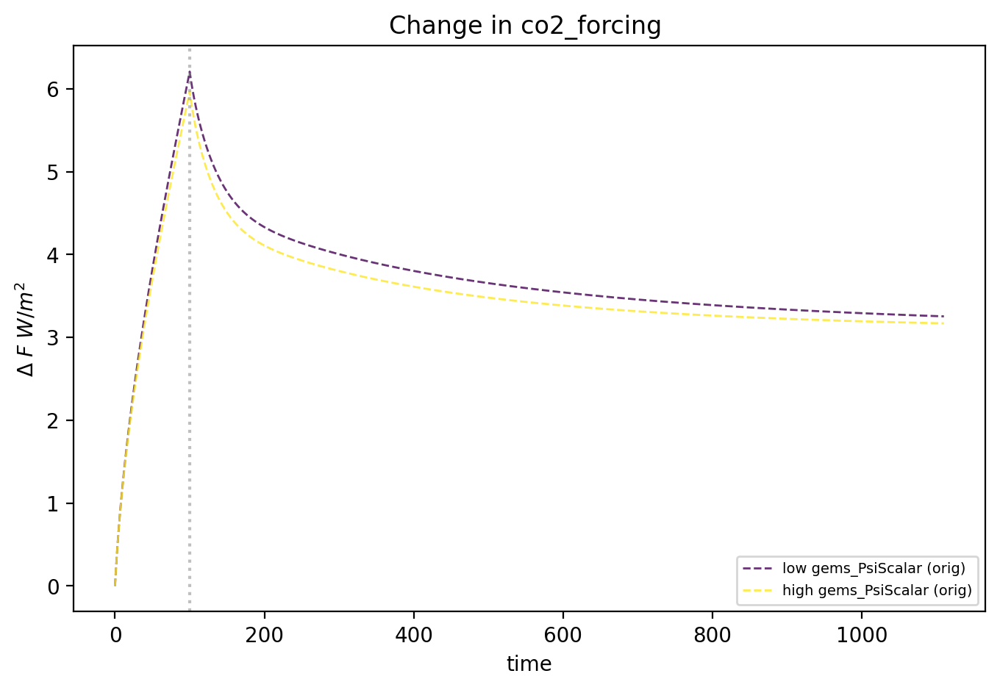

In [1436]:
# unconstrained:

fig, ax = plt.subplots(figsize = (8,5), dpi = 200)

plot_param = 'gems_PsiScalar'
variable = 'co2_forcing'
var= '$F$'
units = '$W/m^2$'

norm = Normalize(vmin=params_fairSDckp[plot_param].min(), vmax=params_fairSDckp[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

kmin = params_fairSDckp[plot_param].min()
T_low = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                           # layer = 0,
                                           config = params_fairSDckp.loc[params_fairSDckp[plot_param] < params_fairSDckp[plot_param].mean()].index.values)
ax.plot((T_low.mean('config')-T_low.mean('config')[0])*PgC_per_ppm, color=scalar_map.to_rgba(kmin), alpha = 0, label = f'_low {plot_param} (ckp)', lw = 1)
# ax.fill_between(T_low.time, 
#                               np.percentile(T_low, 10, axis=1), 
#                               np.percentile(T_low, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmin), zorder = 2, label = 'low clim_kappa3 (ckp) (10th - 90th percentile)')


kmax = params_fairSDckp[plot_param].max()
T_high = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                            # layer = 0,
                                            config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
ax.plot((T_high.mean('config')-T_high.mean('config')[0])*PgC_per_ppm, color=scalar_map.to_rgba(kmax), alpha = 0, label = f'_high {plot_param} (ckp)', lw = 1)

# ax.fill_between(T_high.time, 
#                               np.percentile(T_high, 10, axis=1), 
#                               np.percentile(T_high, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmax), zorder = 2, label = 'high clim_kappa3 (ckp) (10th - 90th percentile)')

###################### ORIGINAL ######

norm = Normalize(vmin=params_fairSD[plot_param].min(), vmax=params_fairSD[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

kmin = params_fairSD[plot_param].min()
T_low = ds_fairSD_flat10[variable].isel(scenario = 0, config = params_fairSD.loc[params_fairSD[plot_param] < params_fairSD[plot_param].mean()].index.values)
ax.plot((T_low.mean('config')-T_low.mean('config')[0])*PgC_per_ppm, color=scalar_map.to_rgba(kmin), alpha = 0.8, label = f'low {plot_param} (orig)', lw = 1, ls = 'dashed')
# ax.fill_between(T_low.time, 
#                               np.percentile(T_low, 10, axis=1), 
#                               np.percentile(T_low, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmin), zorder = 2, label = 'low clim_kappa3 (orig) (10th - 90th percentile)')


kmax = params_fairSD[plot_param].max()
T_high = ds_fairSD_flat10[variable].isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSD[plot_param].mean()].index.values)
ax.plot((T_high.mean('config')-T_high.mean('config')[0])*PgC_per_ppm, color=scalar_map.to_rgba(kmax), alpha = 0.8, label = f'high {plot_param} (orig)', lw = 1, ls = 'dashed')

# ax.fill_between(T_high.time, 
#                               np.percentile(T_high, 10, axis=1), 
#                               np.percentile(T_high, 90, axis=1), 
#                               alpha=0.2, color=scalar_map.to_rgba(kmax), zorder = 2, label = 'high clim_kappa3 (orig) (10th - 90th percentile)')
####################### ORIGINAL ######



ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.savefig(f'figures/PCC_EBM_{plot_param}_timeseries.png', dpi = 300)
plt.legend(fontsize = 7, loc = 'lower right')
ax.set_ylabel(rf'$\Delta$ {var} {units}');ax.set_xlabel(r'time')
ax.set_title(f'Change in {variable} ')
plt.show();plt.close()

In [1221]:
# Constrained by CO2

In [1381]:
params_fairSDckp['gems_Q10_resp']

0      1.652862
1      1.787361
2      2.224598
3      1.602298
4      2.343242
         ...   
995    1.931248
996    1.761434
997    1.775696
998    2.218748
999    2.428559
Name: gems_Q10_resp, Length: 1000, dtype: float64

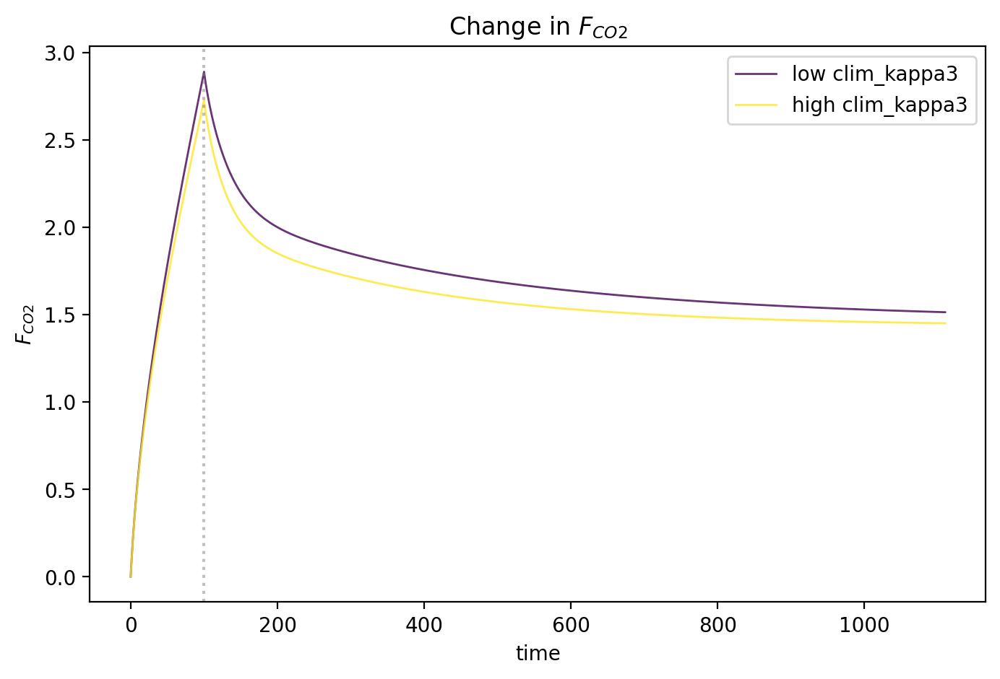

In [902]:
fig, ax = plt.subplots(figsize = (8,5), dpi = 200)

norm = Normalize(vmin=params_fairSDckp['clim_kappa3'].min(), vmax=params_fairSDckp['clim_kappa3'].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)

kmin = params_fairSDckp['clim_kappa3'].min()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] < params_fairSDckp['clim_kappa3'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low clim_kappa3', lw = 1)
# kmed = params_fairSDckp['clim_kappa3'].median()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] == kmed].index.values),
#          color=scalar_map.to_rgba(kmed), alpha = 0.8)
kmax = params_fairSDckp['clim_kappa3'].max()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] > params_fairSDckp['clim_kappa3'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high clim_kappa3', lw = 1)
ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.legend()
ax.set_ylabel(r'$F_{CO2}$');ax.set_xlabel(r'time')
ax.set_title(r'Change in $F_{CO2}$')
plt.show();plt.close()

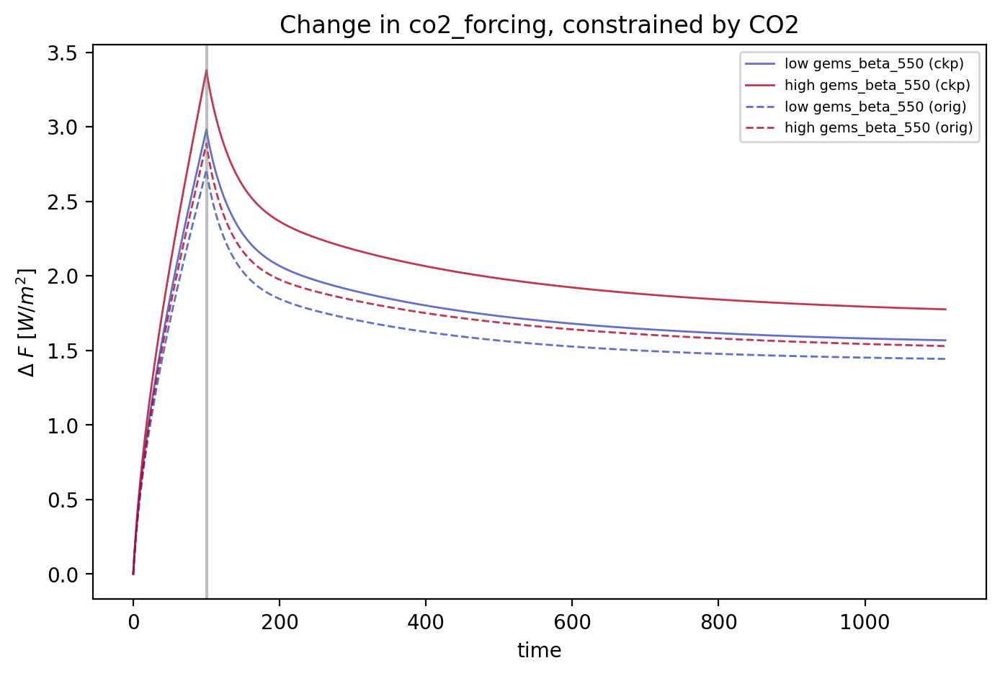

In [2109]:
fig, ax = plt.subplots(figsize = (8,5), dpi = 200)

plot_param = 'gems_beta_550'
variable = 'co2_forcing'
var= '$F$'
units = r'$W/m^2$'

norm = Normalize(vmin=params_fairSDckp[plot_param].min(), vmax=params_fairSDckp[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.coolwarm)

kmin = params_fairSDckp[plot_param].min()
temp_low = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                   # layer = 0, 
                                                   config = params_fairSDckp.loc[params_fairSDckp[plot_param] < params_fairSDckp[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2_SDckp)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                       # layer = 0
                                                      )[:,i_low_co2]
ax.plot((temp_low_co2.mean('config')),
        color=scalar_map.to_rgba(kmin),
        alpha = 0.8, label = f'low {plot_param} (ckp)', lw = 1)


kmax = params_fairSDckp[plot_param].max()
temp_high = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                    # layer = 0, 
                                                    config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2_SDckp)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                        # layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')),
        color=scalar_map.to_rgba(kmax),
        alpha = 0.8, label = f'high {plot_param} (ckp)', lw = 1)

###################### ORIGINAL ######

norm = Normalize(vmin=params_fairSD[plot_param].min(), vmax=params_fairSD[plot_param].max())
scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.coolwarm)

kmin = params_fairSD[plot_param].min()
temp_low = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                # layer = 0, 
                                                config = params_fairSD.loc[params_fairSD[plot_param] < params_fairSD[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2_SD)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                    # layer = 0
                                                   )[:,i_low_co2]

ax.plot((temp_low_co2.mean('config')), color=scalar_map.to_rgba(kmin), alpha = 0.8, label = f'low {plot_param} (orig)', lw = 1, ls = 'dashed')


kmax = params_fairSD[plot_param].max()
temp_high = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                 # layer = 0, 
                                                 config = params_fairSD.loc[params_fairSD[plot_param] > params_fairSD[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2_SD)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                        # layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')), color=scalar_map.to_rgba(kmax), alpha = 0.8, label = f'high {plot_param} (orig)', lw = 1, ls = 'dashed')


####################### ORIGINAL ######


# plt.ylim(360,490)
# plt.xlim(90,110)
ax.axvline(100, c = 'grey', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.savefig(f'figures/PCC_EBM_{plot_param}_timeseries_constrained_by_CO2.png', dpi = 300)
plt.legend(fontsize = 7, loc = 'best')
ax.set_ylabel(rf'$\Delta$ {var} [{units}]');ax.set_xlabel(r'time')
ax.set_title(f'Change in {variable}, constrained by CO2')
plt.show();plt.close()

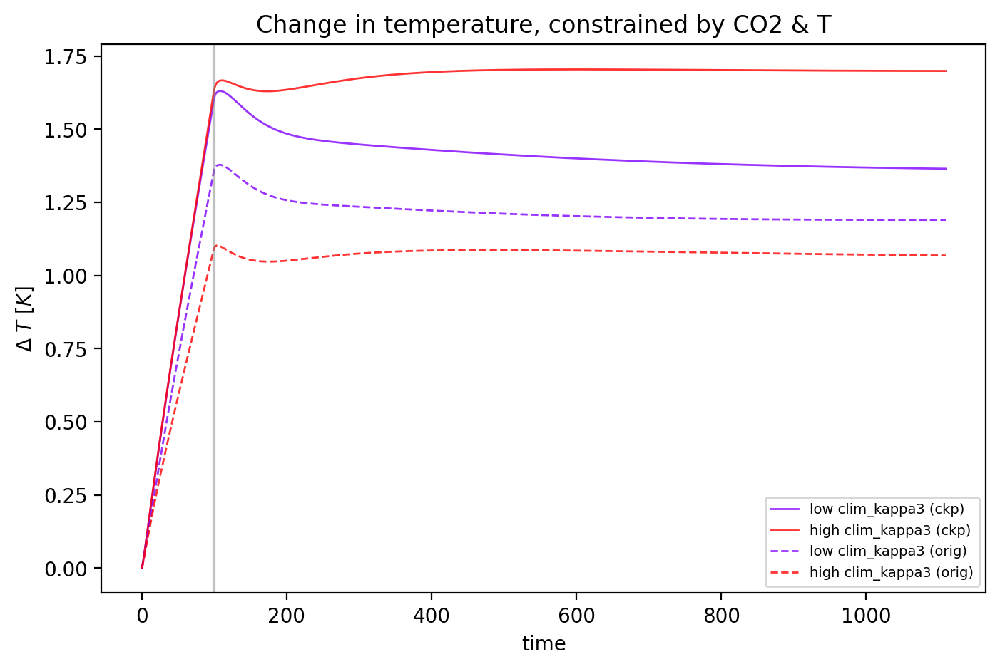

In [2108]:
fig, ax = plt.subplots(figsize = (8,5), dpi = 200)

plot_param = 'clim_kappa3'
variable = 'temperature'
var= '$T$'
units = '$K$'

norm = Normalize(vmin=params_fairSDckp[plot_param].min(), vmax=params_fairSDckp[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)

kmin = params_fairSDckp[plot_param].min()
temp_low = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                   layer = 0, 
                                                   config = params_fairSDckp.loc[params_fairSDckp[plot_param] < params_fairSDckp[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SDckp)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                       layer = 0
                                                      )[:,i_low_co2]
ax.plot((temp_low_co2.mean('config')),
        color=scalar_map.to_rgba(kmin),
        alpha = 0.8, label = f'low {plot_param} (ckp)', lw = 1)


kmax = params_fairSDckp[plot_param].max()
temp_high = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                    layer = 0, 
                                                    config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SDckp)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                        layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')),
        color=scalar_map.to_rgba(kmax),
        alpha = 0.8, label = f'high {plot_param} (ckp)', lw = 1)

###################### ORIGINAL ######

norm = Normalize(vmin=params_fairSD[plot_param].min(), vmax=params_fairSD[plot_param].max())
scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)

kmin = params_fairSD[plot_param].min()
temp_low = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                layer = 0, 
                                                config = params_fairSD.loc[params_fairSD[plot_param] < params_fairSD[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SD)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                    layer = 0
                                                   )[:,i_low_co2]

ax.plot((temp_low_co2.mean('config')), color=scalar_map.to_rgba(kmin), alpha = 0.8, label = f'low {plot_param} (orig)', lw = 1, ls = 'dashed')


kmax = params_fairSD[plot_param].max()
temp_high = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                 layer = 0, 
                                                 config = params_fairSD.loc[params_fairSD[plot_param] > params_fairSD[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SD)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                        layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')), color=scalar_map.to_rgba(kmax), alpha = 0.8, label = f'high {plot_param} (orig)', lw = 1, ls = 'dashed')


####################### ORIGINAL ######


# plt.ylim(360,490)
# plt.xlim(90,110)
ax.axvline(100, c = 'grey', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.savefig(f'figures/PCC_EBM_{plot_param}_timeseries_constrained_by_CO2T.png', dpi = 300)
plt.legend(fontsize = 7, loc = 'best')
ax.set_ylabel(rf'$\Delta$ {var} [{units}]');ax.set_xlabel(r'time')
ax.set_title(f'Change in {variable}, constrained by CO2 & T')
plt.show();plt.close()

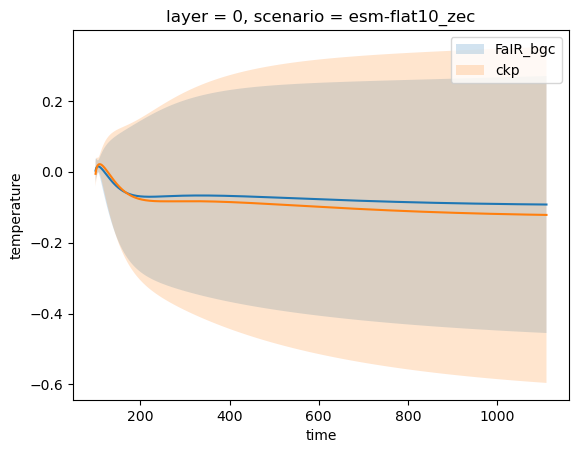

In [2186]:
var = 'temperature'


plot_data = (ds_fairSD_flat10[var].sel(layer = 0, scenario = 'esm-flat10_zec') - tcre1000_SD).sel(config = constrained_by_co2T_SD, time = slice(100,1111) )

plot_data.mean('config').plot.line(x='time')

plt.fill_between(plot_data.time, 
                 plot_data.mean('config')+plot_data.std('config'),
                 plot_data.mean('config')-plot_data.std('config'),
                 alpha = .2, label = 'FaIR_bgc')



plot_data_ckp = (ds_fairSDckp_flat10[var].sel(layer = 0, scenario = 'esm-flat10_zec') - tcre1000_SDckp).sel(config = constrained_by_co2T_SDckp, time = slice(100,1111) )

plot_data_ckp.mean('config').plot.line(x='time')

plt.fill_between(plot_data_ckp.time, 
                 plot_data_ckp.mean('config')+plot_data_ckp.std('config'),
                 plot_data_ckp.mean('config')-plot_data_ckp.std('config'),
                 alpha = .2, label = 'ckp')
plt.legend()

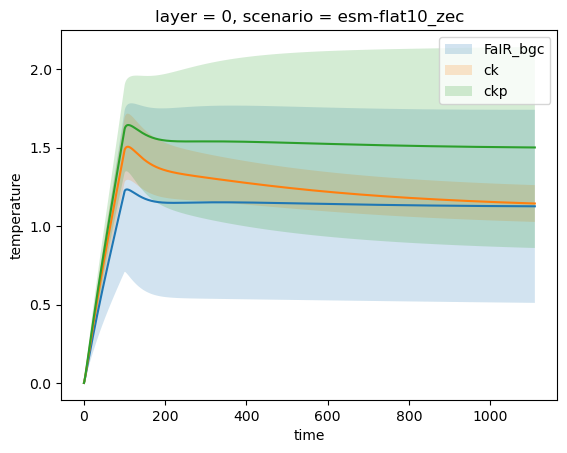

In [2185]:
var = 'temperature'


plot_data = (ds_fairSD_flat10[var].sel(layer = 0, scenario = 'esm-flat10_zec')).sel(config = constrained_by_co2T_SD, )

plot_data.mean('config').plot.line(x='time')

plt.fill_between(plot_data.time, 
                 plot_data.mean('config')+plot_data.std('config'),
                 plot_data.mean('config')-plot_data.std('config'),
                 alpha = .2, label = 'FaIR_bgc')



plot_data_ck = (ds_fairSDck_flat10[var].sel(scenario = 'esm-flat10_zec')).sel(config = constrained_by_co2T_SDck, )

plot_data_ck.mean('config').plot.line(x='time')

plt.fill_between(plot_data_ck.time, 
                 plot_data_ck.mean('config')+plot_data_ck.std('config'),
                 plot_data_ck.mean('config')-plot_data_ck.std('config'),
                 alpha = .2, label = 'ck')



plot_data_ckp = (ds_fairSDckp_flat10[var].sel(layer = 0, scenario = 'esm-flat10_zec')).sel(config = constrained_by_co2T_SDckp, )

plot_data_ckp.mean('config').plot.line(x='time')

plt.fill_between(plot_data_ckp.time, 
                 plot_data_ckp.mean('config')+plot_data_ckp.std('config'),
                 plot_data_ckp.mean('config')-plot_data_ckp.std('config'),
                 alpha = .2, label = 'ckp')
plt.legend()

In [2195]:

total_3xp_timescales = pd.DataFrame()
total_3xp_timescales['FaIR_SD_tau1'] = df_SD['tau1'][constrained_by_co2T_SD]
total_3xp_timescales['FaIR_SD_tau2'] = df_SD['tau2'][constrained_by_co2T_SD]
total_3xp_timescales['FaIR_SD_tau3'] = df_SD['tau3'][constrained_by_co2T_SD]

In [2196]:
total_3xp_timescales

,FaIR_SD_tau1,FaIR_SD_tau2,FaIR_SD_tau3
13,3.130453,36.728451,380.703613
15,2.863262,34.484594,441.887473
16,3.233624,32.964819,252.094653
22,2.764208,33.561111,245.763339
23,2.541416,32.583423,263.715028
...,...,...,...
944,2.907081,31.236708,281.451094
946,3.230575,38.655251,367.356472
955,3.219704,35.311613,288.487525
981,2.924843,35.768971,502.654632


In [187]:
sns.set_theme(style="white", palette = sns.color_palette('Pastel1'))

# total_3xp_timescales[' = df_SD.tau1[constrained_by_co2T_SD]


fig, ax = plt.subplots(3,1, figsize = (8,8), dpi = 300, sharex=False)

sns.histplot(total_3xp_timescales[['FaIR_default_tau1','FaIR_SD_tau1','HECTOR_tau1']],ax=ax[0], kde=True,palette = palette1,)
sns.histplot(total_3xp_timescales[['FaIR_default_tau2','FaIR_SD_tau2','HECTOR_tau2']],ax=ax[1], kde=True,palette = palette2,)
sns.histplot(total_3xp_timescales[['FaIR_default_tau3','FaIR_SD_tau3','HECTOR_tau3']],ax=ax[2], kde=True,palette = palette3,)

plt.suptitle('Timescale distributions')

ax[0].set_xlabel(r'3x timescales: $\tau_1$')
# ax[0].set_title(r'$\tau_1$')
ax[1].set_xlabel(r'3x timescales: $\tau_2$')
ax[2].set_xlabel(r'3x timescales: $\tau_3$')
plt.tight_layout()
plt.savefig('figures/hist_tau_3xp_compare-models.png', dpi=300)
plt.show();plt.close()



SyntaxError: unterminated string literal (detected at line 3) (220873495.py, line 3)

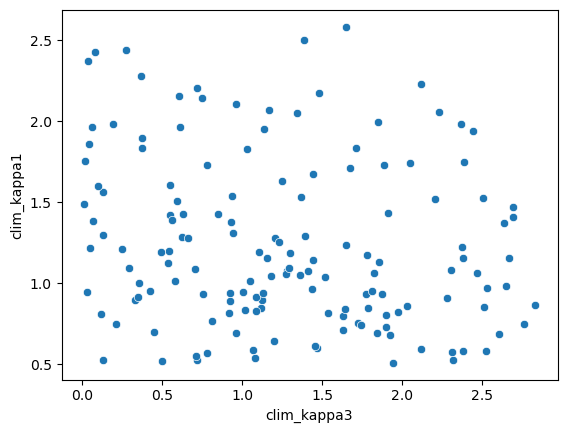

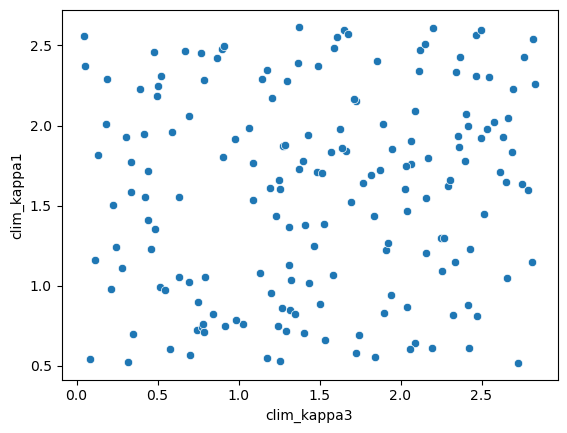

In [188]:
sns.scatterplot(x = params_fairSDckp['clim_kappa3'][constrained_by_co2T_SDckp], y = params_fairSDckp['clim_kappa1'][constrained_by_co2T_SDckp])
plt.show();plt.close()

sns.scatterplot(x = params_fairSD['clim_kappa3'][constrained_by_co2T_SD], y = params_fairSD['clim_kappa1'][constrained_by_co2T_SD])
plt.show();plt.close()

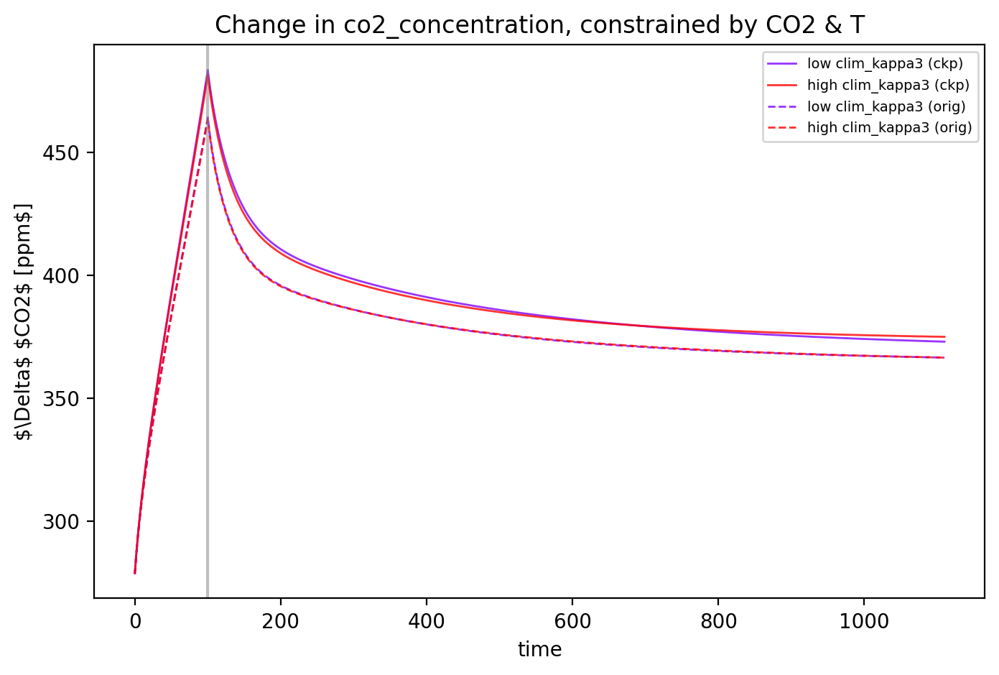

In [2599]:
fig, ax = plt.subplots(figsize = (8,5), dpi = 200)

plot_param = 'clim_kappa3'
variable = 'co2_concentration'
var= '$CO2$'
units = 'ppm$'

norm = Normalize(vmin=params_fairSDckp[plot_param].min(), vmax=params_fairSDckp[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)

kmin = params_fairSDckp[plot_param].min()
temp_low = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                   # layer = 0, 
                                                   config = params_fairSDckp.loc[params_fairSDckp[plot_param] < params_fairSDckp[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SDckp)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                       # layer = 0
                                                      )[:,i_low_co2]
ax.plot((temp_low_co2.mean('config')),
        color=scalar_map.to_rgba(kmin),
        alpha = 0.8, label = f'low {plot_param} (ckp)', lw = 1)


kmax = params_fairSDckp[plot_param].max()
temp_high = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                    # layer = 0, 
                                                    config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SDckp)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                        # layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')),
        color=scalar_map.to_rgba(kmax),
        alpha = 0.8, label = f'high {plot_param} (ckp)', lw = 1)

###################### ORIGINAL ######

norm = Normalize(vmin=params_fairSD[plot_param].min(), vmax=params_fairSD[plot_param].max())
scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)

kmin = params_fairSD[plot_param].min()
temp_low = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                # layer = 0, 
                                                config = params_fairSD.loc[params_fairSD[plot_param] < params_fairSD[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SD)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                    # layer = 0
                                                   )[:,i_low_co2]

ax.plot((temp_low_co2.mean('config')), color=scalar_map.to_rgba(kmin), alpha = 0.8, label = f'low {plot_param} (orig)', lw = 1, ls = 'dashed')


kmax = params_fairSD[plot_param].max()
temp_high = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                 # layer = 0, 
                                                 config = params_fairSD.loc[params_fairSD[plot_param] > params_fairSD[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SD)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                        # layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')), color=scalar_map.to_rgba(kmax), alpha = 0.8, label = f'high {plot_param} (orig)', lw = 1, ls = 'dashed')


####################### ORIGINAL ######


# plt.ylim(360,490)
# plt.xlim(90,110)
ax.axvline(100, c = 'grey', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.savefig(f'figures/PCC_EBM_{plot_param}_timeseries_constrained_by_CO2T.png', dpi = 300)
plt.legend(fontsize = 7, loc = 'best')
ax.set_ylabel(rf'$\Delta$ {var} [{units}]');ax.set_xlabel(r'time')
ax.set_title(f'Change in {variable}, constrained by CO2 & T')
plt.show();plt.close()

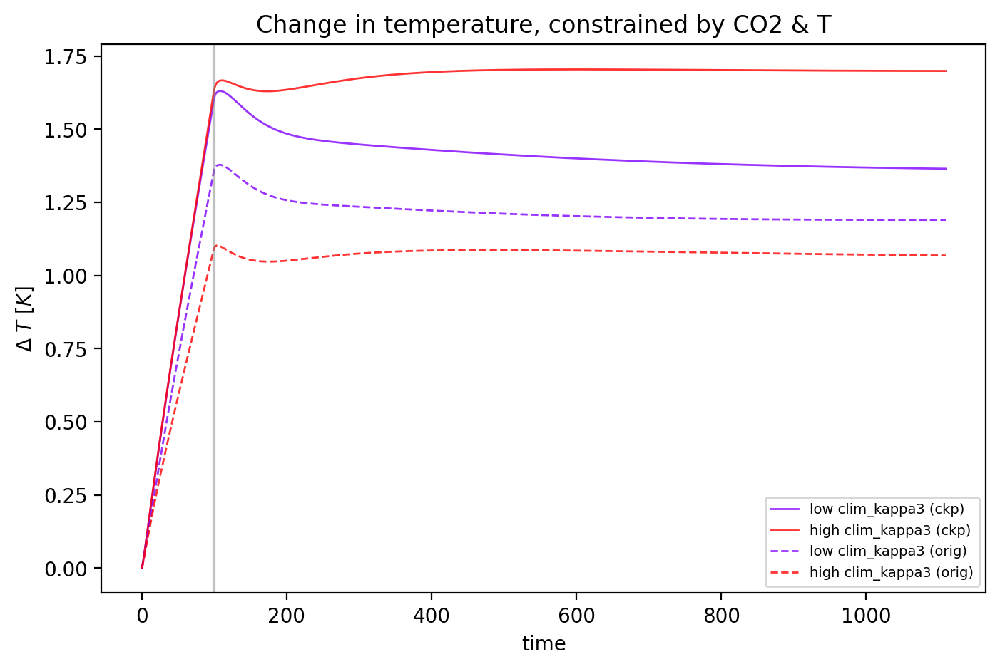

In [2639]:
fig, ax = plt.subplots(figsize = (8,5), dpi = 200)

# plot_param = 'clim_kappa3'
plot_param = 'clim_kappa3'
variable = 'temperature'
var= '$T$'
units = '$K$'

norm = Normalize(vmin=params_fairSDckp[plot_param].min(), vmax=params_fairSDckp[plot_param].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)

kmin = params_fairSDckp[plot_param].min()
temp_low = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                   layer = 0, 
                                                   config = params_fairSDckp.loc[params_fairSDckp[plot_param] < params_fairSDckp[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SDckp)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                       layer = 0
                                                      )[:,i_low_co2]
ax.plot((temp_low_co2.mean('config')),
        color=scalar_map.to_rgba(kmin),
        alpha = 0.8, label = f'low {plot_param} (ckp)', lw = 1)


kmax = params_fairSDckp[plot_param].max()
temp_high = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                    layer = 0, 
                                                    config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SDckp)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                        layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')),
        color=scalar_map.to_rgba(kmax),
        alpha = 0.8, label = f'high {plot_param} (ckp)', lw = 1)

###################### ORIGINAL ######

norm = Normalize(vmin=params_fairSD[plot_param].min(), vmax=params_fairSD[plot_param].max())
scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.rainbow)

kmin = params_fairSD[plot_param].min()
temp_low = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                layer = 0, 
                                                config = params_fairSD.loc[params_fairSD[plot_param] < params_fairSD[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SD)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                    layer = 0
                                                   )[:,i_low_co2]

ax.plot((temp_low_co2.mean('config')), color=scalar_map.to_rgba(kmin), alpha = 0.8, label = f'low {plot_param} (orig)', lw = 1, ls = 'dashed')


kmax = params_fairSD[plot_param].max()
temp_high = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                 layer = 0, 
                                                 config = params_fairSD.loc[params_fairSD[plot_param] > params_fairSD[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SD)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                        layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')), color=scalar_map.to_rgba(kmax), alpha = 0.8, label = f'high {plot_param} (orig)', lw = 1, ls = 'dashed')


####################### ORIGINAL ######


# plt.ylim(360,490)
# plt.xlim(90,110)
ax.axvline(100, c = 'grey', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.savefig(f'figures/PCC_EBM_{plot_param}_timeseries_constrained_by_CO2T.png', dpi = 300)
plt.legend(fontsize = 7, loc = 'best')
ax.set_ylabel(rf'$\Delta$ {var} [{units}]');ax.set_xlabel(r'time')
ax.set_title(f'Change in {variable}, constrained by CO2 & T')
plt.show();plt.close()

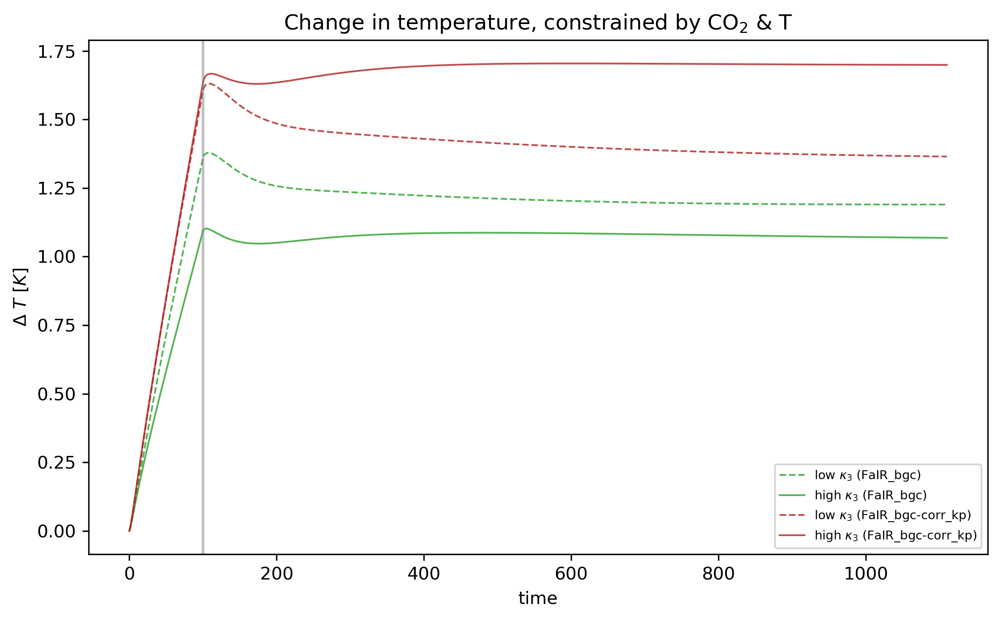

In [379]:
fig, ax = plt.subplots(figsize = (8,5), dpi = 300)

# plot_param = 'clim_kappa3'
plot_param = 'clim_kappa3'
variable = 'temperature'
var= '$T$'
units = '$K$'


###################### ORIGINAL ######

kmin = params_fairSD[plot_param].min()
temp_low = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                layer = 0, 
                                                config = params_fairSD.loc[params_fairSD[plot_param] < params_fairSD[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SD)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                    layer = 0
                                                   )[:,i_low_co2]

ax.plot((temp_low_co2.mean('config')), color='tab:green', alpha = 0.8, label = rf'low $\kappa_3$ (FaIR_bgc)', lw = 1, ls = 'dashed')


kmax = params_fairSD[plot_param].max()
temp_high = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                 layer = 0, 
                                                 config = params_fairSD.loc[params_fairSD[plot_param] > params_fairSD[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SD)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSD_flat10[variable].isel(scenario = 0, 
                                                        layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')), color='tab:green', alpha = 0.8, label = rf'high $\kappa_3$ (FaIR_bgc)', lw = 1,)


####################### ORIGINAL ######


kmin = params_fairSDckp[plot_param].min()
temp_low = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                   layer = 0, 
                                                   config = params_fairSDckp.loc[params_fairSDckp[plot_param] < params_fairSDckp[plot_param].mean()].index.values)
i_low_co2 = temp_low.config.where(np.isin(temp_low.config,constrained_by_co2T_SDckp)).values
i_low_co2 = i_low_co2[~np.isnan(i_low_co2)].astype(int)
temp_low_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                       layer = 0
                                                      )[:,i_low_co2]
ax.plot((temp_low_co2.mean('config')),
        color='firebrick', ls = 'dashed',
        alpha = 0.8, label = rf'low $\kappa_3$ (FaIR_bgc-corr_kp)', lw = 1)


kmax = params_fairSDckp[plot_param].max()
temp_high = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                    layer = 0, 
                                                    config = params_fairSDckp.loc[params_fairSDckp[plot_param] > params_fairSDckp[plot_param].mean()].index.values)
i_high_co2 = temp_high.config.where(np.isin(temp_high.config,constrained_by_co2T_SDckp)).values
i_high_co2 = i_high_co2[~np.isnan(i_high_co2)].astype(int)
temp_high_co2 = ds_fairSDckp_flat10[variable].isel(scenario = 0, 
                                                        layer = 0
                                                       )[:,i_high_co2]
ax.plot((temp_high_co2.mean('config')),
        color='firebrick',
        alpha = 0.8, label = rf'high $\kappa_3$ (FaIR_bgc-corr_kp)', lw = 1)




# plt.ylim(360,490)
# plt.xlim(90,110)
ax.axvline(100, c = 'grey', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
plt.legend(fontsize = 7, loc = 'best')
ax.set_ylabel(rf'$\Delta$ {var} [{units}]');ax.set_xlabel(r'time')
ax.set_title(rf'Change in {variable}, constrained by CO$_2$ & T')
plt.tight_layout()
plt.savefig(f'figures/PCC_EBM_{plot_param}_timeseries_constrained_by_CO2T_color_SD_ckp.png', dpi = 300)

plt.show();plt.close()

In [859]:
params_fairSDckp.columns

Index(['Unnamed: 0', 'clim_gamma', 'clim_c1', 'clim_c2', 'clim_c3',
       'clim_kappa1', 'clim_kappa2', 'clim_kappa3', 'clim_epsilon',
       'clim_sigma_eta', 'clim_sigma_xi', 'clim_F_4xCO2', 'cc_r0', 'cc_rU',
       'cc_rT', 'cc_rA', 'ari_BC', 'ari_CH4', 'ari_N2O', 'ari_NH3', 'ari_NOx',
       'ari_OC', 'ari_Sulfur', 'ari_VOC',
       'ari_Equivalent effective stratospheric chlorine', 'aci_shape_so2',
       'aci_shape_bc', 'aci_shape_oc', 'aci_beta', 'o3_CH4', 'o3_N2O',
       'o3_Equivalent effective stratospheric chlorine', 'o3_CO', 'o3_VOC',
       'o3_NOx', 'fscale_CH4', 'fscale_N2O', 'fscale_minorGHG',
       'fscale_Stratospheric water vapour', 'fscale_Land use',
       'fscale_Volcanic', 'fscale_solar_amplitude', 'fscale_solar_trend',
       'fscale_Light absorbing particles on snow and ice', 'fscale_Contrails',
       'fscale_CO2', 'cc_co2_concentration_1750', 'gems_beta_550',
       'gems_Q10_resp', 'gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb',
       'gems_patm0', 'TC

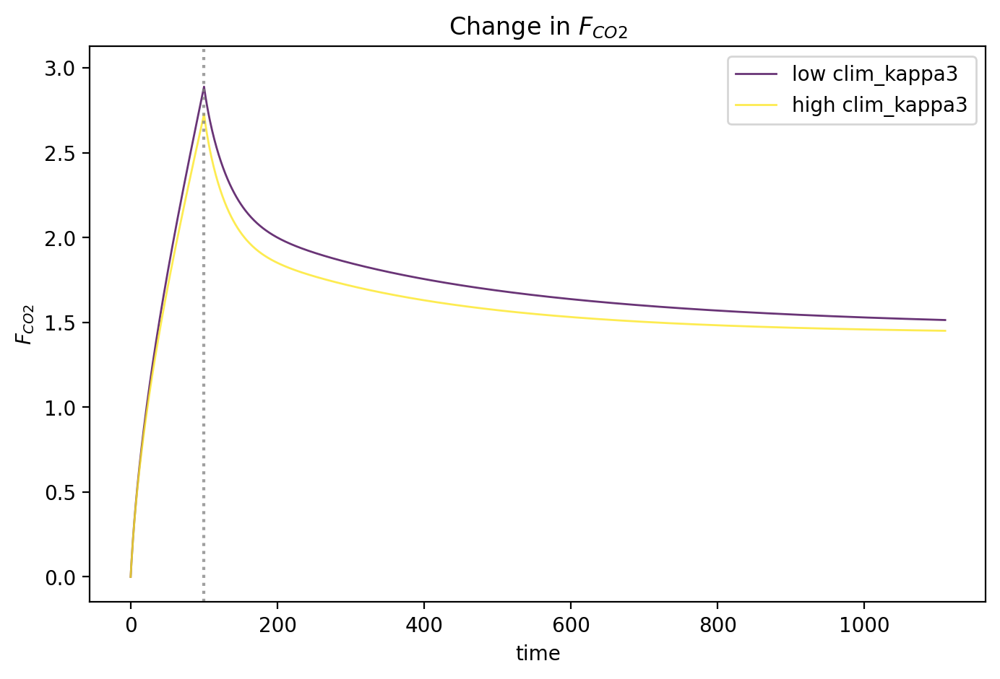

In [904]:
fig, ax = plt.subplots( figsize = (8,5), dpi = 200, sharey = True)

norm = Normalize(vmin=params_fairSDckp['clim_kappa3'].min(), vmax=params_fairSDckp['clim_kappa3'].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)
kmin = params_fairSDckp['clim_kappa3'].min()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] < params_fairSDckp['clim_kappa3'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low clim_kappa3', lw = 1)
# kmed = params_fairSDckp['clim_kappa3'].median()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] == kmed].index.values),
#          color=scalar_map.to_rgba(kmed), alpha = 0.8)
kmax = params_fairSDckp['clim_kappa3'].max()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] > params_fairSDckp['clim_kappa3'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high clim_kappa3', lw = 1)
ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
ax.set_title(f'Change in forcing')
# plt.show();plt.close()


norm = Normalize(vmin=params_fairSDckp['gems_beta_550'].min(), vmax=params_fairSDckp['gems_beta_550'].max())
scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.BrBG)
kmin = params_fairSDckp['gems_beta_550'].min()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_beta_550'] < params_fairSDckp['gems_beta_550'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmin), alpha = 0, label = '_low gems_beta_550', lw = 1)
# kmed = params_fairSDckp['clim_kappa3'].median()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] == kmed].index.values),
#          color=scalar_map.to_rgba(kmed), alpha = 0.8)
kmax = params_fairSDckp['gems_beta_550'].max()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_beta_550'] > params_fairSDckp['gems_beta_550'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmax), alpha = 0, label = '_high gems_beta_550', lw = 1)
ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)


# norm = Normalize(vmin=params_fairSDckp['gems_PsiScalar'].min(), vmax=params_fairSDckp['gems_PsiScalar'].max())
# scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.coolwarm)
# kmin = params_fairSDckp['gems_PsiScalar'].min()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_PsiScalar'] < params_fairSDckp['gems_PsiScalar'].mean()].index.values).mean('config'),
#          color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low gems_PsiScalar')
# # kmed = params_fairSDckp['clim_kappa3'].median()
# # ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] == kmed].index.values),
# #          color=scalar_map.to_rgba(kmed), alpha = 0.8)
# kmax = params_fairSDckp['gems_PsiScalar'].max()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_PsiScalar'] > params_fairSDckp['gems_PsiScalar'].mean()].index.values).mean('config'),
#          color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high gems_PsiScalar')
# ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)
plt.legend()
ax.set_ylabel(r'$F_{CO2}$');ax.set_xlabel(r'time')
ax.set_title(r'Change in $F_{CO2}$')
plt.show();plt.close()

plt.show();plt.close()

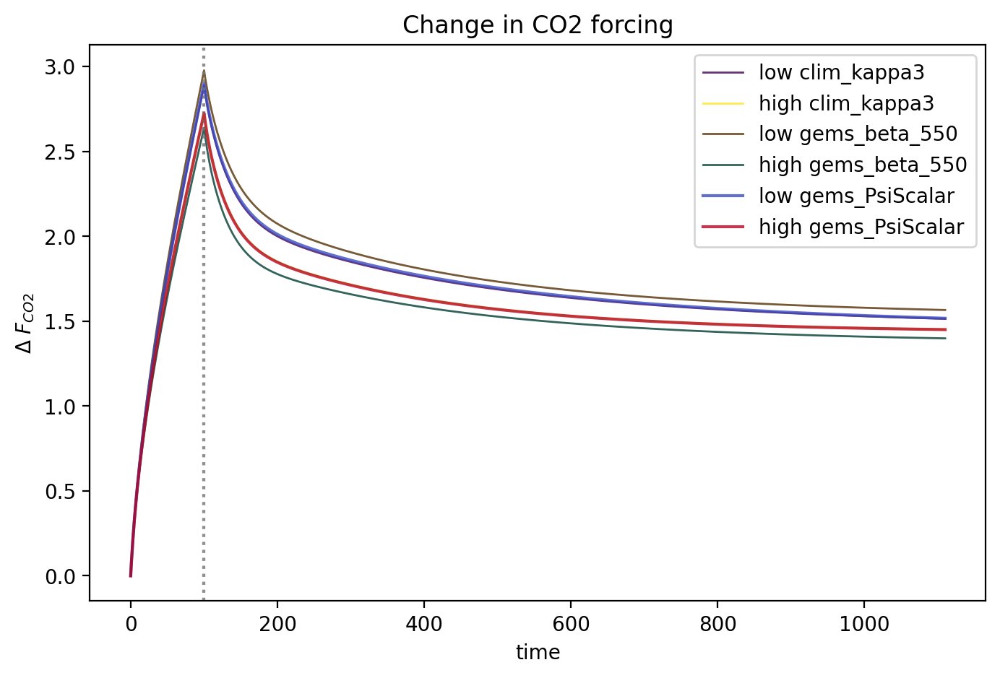

In [992]:
fig, ax = plt.subplots( figsize = (8,5), dpi = 200, sharey = True)

norm = Normalize(vmin=params_fairSDckp['clim_kappa3'].min(), vmax=params_fairSDckp['clim_kappa3'].max())

scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.viridis)
kmin = params_fairSDckp['clim_kappa3'].min()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] < params_fairSDckp['clim_kappa3'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low clim_kappa3', lw = 1)
# kmed = params_fairSDckp['clim_kappa3'].median()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] == kmed].index.values),
#          color=scalar_map.to_rgba(kmed), alpha = 0.8)
kmax = params_fairSDckp['clim_kappa3'].max()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] > params_fairSDckp['clim_kappa3'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high clim_kappa3', lw = 1)
ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)
# cb = plt.colorbar(scalar_map, ax = ax)
# cb.set_label('clim_kappa3')
ax.set_title(f'Change in forcing')
# plt.show();plt.close()


norm = Normalize(vmin=params_fairSDckp['gems_beta_550'].min(), vmax=params_fairSDckp['gems_beta_550'].max())
scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.BrBG)
kmin = params_fairSDckp['gems_beta_550'].min()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_beta_550'] < params_fairSDckp['gems_beta_550'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low gems_beta_550', lw = 1)
# kmed = params_fairSDckp['clim_kappa3'].median()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] == kmed].index.values),
#          color=scalar_map.to_rgba(kmed), alpha = 0.8)
kmax = params_fairSDckp['gems_beta_550'].max()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_beta_550'] > params_fairSDckp['gems_beta_550'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high gems_beta_550', lw = 1)
ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)


norm = Normalize(vmin=params_fairSDckp['gems_PsiScalar'].min(), vmax=params_fairSDckp['gems_PsiScalar'].max())
scalar_map = cm.ScalarMappable(norm=norm, cmap=cm.coolwarm)
kmin = params_fairSDckp['gems_PsiScalar'].min()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_PsiScalar'] < params_fairSDckp['gems_PsiScalar'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmin), alpha = 0.8, label = 'low gems_PsiScalar')
# kmed = params_fairSDckp['clim_kappa3'].median()
# ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['clim_kappa3'] == kmed].index.values),
#          color=scalar_map.to_rgba(kmed), alpha = 0.8)
kmax = params_fairSDckp['gems_PsiScalar'].max()
ax.plot((ds_fairSDckp_flat10['co2_forcing']).isel(scenario = 0, config = params_fairSDckp.loc[params_fairSDckp['gems_PsiScalar'] > params_fairSDckp['gems_PsiScalar'].mean()].index.values).mean('config'),
         color=scalar_map.to_rgba(kmax), alpha = 0.8, label = 'high gems_PsiScalar')
ax.axvline(100, c = 'grey', ls = 'dotted', alpha = 0.5)
ax.set_ylabel(r'$\Delta$ $F_{CO2}$');ax.set_xlabel(r'time')
plt.legend()
ax.set_title(f'Change in CO2 forcing')

plt.show();plt.close()

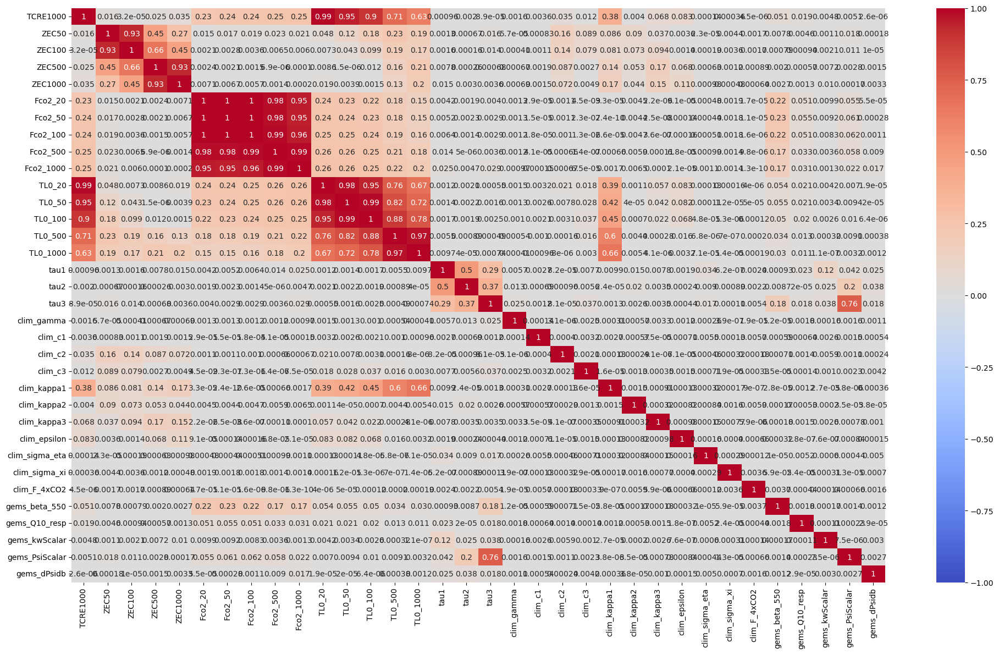

In [189]:
features1=['TCRE1000','ZEC50','ZEC100','ZEC500','ZEC1000','Fco2_20','Fco2_50','Fco2_100','Fco2_500','Fco2_1000',
           'TL0_20','TL0_50','TL0_100','TL0_500','TL0_1000',
           'tau1','tau2','tau3',
           'clim_gamma','clim_c1','clim_c2','clim_c3',
           'clim_kappa1','clim_kappa2', 'clim_kappa3', 
           'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
           'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']

plt.figure(figsize=(20, 12))
data = df_SD[features1]
corr = data.corr()**2

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'coolwarm')
plt.tight_layout()

In [190]:
df_SD_r2_pearson = data.corr().copy()
df_SD_pval_pearson = data.corr().copy()

In [191]:
for a in data.columns.to_list():
    for b in data.columns.to_list():
        # if b in ['tau1', 'tau2', 'tau3']:
        #     df_SD_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[top100_co2_SD][a], y = df_SD.iloc[top100_co2_SD][b])[0]
        #     df_SD_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[top100_co2_SD][a], y = df_SD.iloc[top100_co2_SD][b])[1]
        # elif a in ['tau1', 'tau2', 'tau3']:
        #     df_SD_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[top100_co2_SD][a], y = df_SD.iloc[top100_co2_SD][b])[0]
        #     df_SD_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[top100_co2_SD][a], y = df_SD.iloc[top100_co2_SD][b])[1]
        # else:
        #     df_SD_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD[a], y = df_SD[b])[0]
        #     df_SD_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD[a], y = df_SD[b])[1]
        # else:
        #     df_SD_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[constrained_by_co2_SD][a], y = df_SD.iloc[constrained_by_co2_SD][b])[0]
        #     df_SD_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[constrained_by_co2_SD][a], y = df_SD.iloc[constrained_by_co2_SD][b])[1]
        # else:
        df_SD_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[constrained_by_co2T_SD][a], y = df_SD.iloc[constrained_by_co2T_SD][b])[0]
        df_SD_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SD.iloc[constrained_by_co2T_SD][a], y = df_SD.iloc[constrained_by_co2T_SD][b])[1]

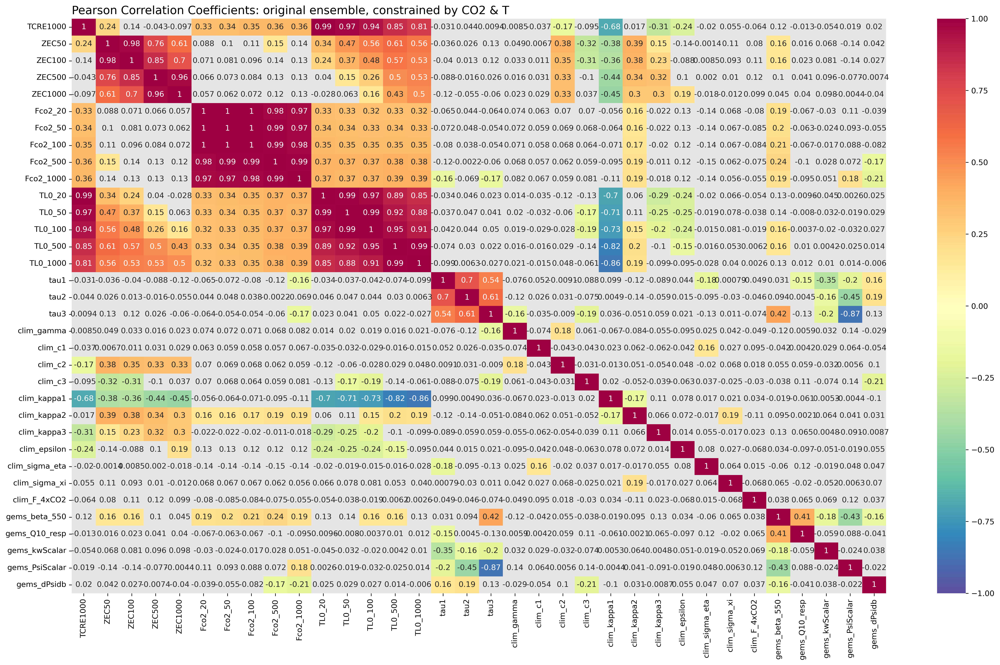

In [192]:
plt.figure(figsize=(20, 12), dpi=300)
corr = df_SD_r2_pearson['TCRE1000':].where(df_SD_pval_pearson['TCRE1000':]<0.05)
corr_nonsig = df_SD_r2_pearson['TCRE1000':].where(df_SD_pval_pearson['TCRE1000':]>0.05)

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
sns.heatmap(corr_nonsig, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
plt.tight_layout()
plt.title('Pearson Correlation Coefficients: original ensemble, constrained by CO2 & T', loc = 'left', fontsize = 15)
plt.savefig('figures/PCC_origSD_co2T.png', dpi = 300)
plt.show();plt.close()

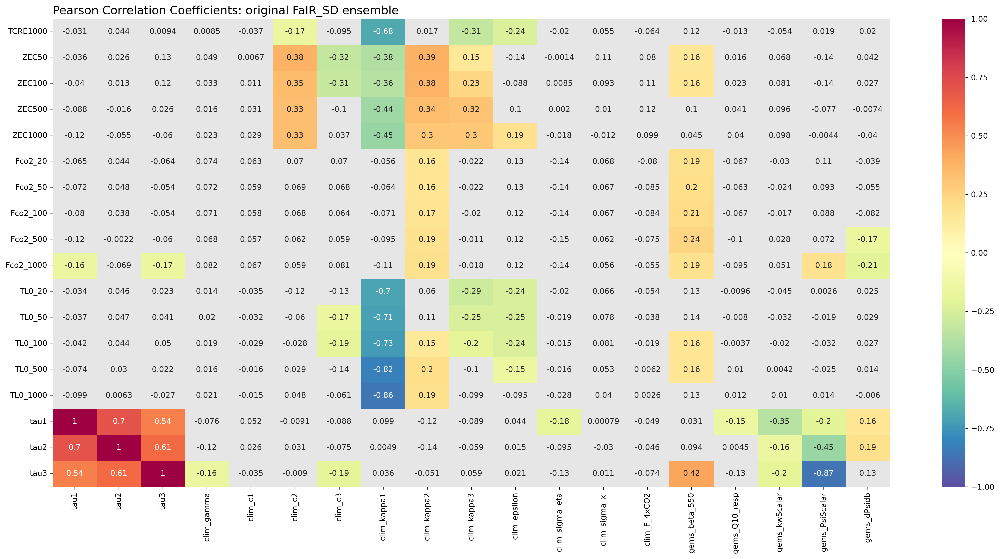

In [193]:
plt.figure(figsize=(20, 10), dpi=300)
corr = df_SD_r2_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb'].where(df_SD_pval_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb']<0.05)
corr_non = df_SD_r2_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb'].where(df_SD_pval_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb']>0.05)

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
sns.heatmap(corr_non, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
plt.tight_layout()
plt.title('Pearson Correlation Coefficients: original FaIR_SD ensemble', loc = 'left', fontsize = 15)
plt.savefig('figures/PCC_origSD_abridged_co2T.png', dpi = 300)
plt.show();plt.close()

In [194]:
df_SD_r2_pearson['gems_PsiScalar']

TCRE1000          0.019000
ZEC50            -0.143480
ZEC100           -0.138599
ZEC500           -0.077493
ZEC1000          -0.004440
Fco2_20           0.110378
Fco2_50           0.092965
Fco2_100          0.088226
Fco2_500          0.072440
Fco2_1000         0.183471
TL0_20            0.002625
TL0_50           -0.018532
TL0_100          -0.031975
TL0_500          -0.024868
TL0_1000          0.013879
tau1             -0.204987
tau2             -0.447761
tau3             -0.874534
clim_gamma        0.139109
clim_c1           0.063604
clim_c2           0.005623
clim_c3           0.141031
clim_kappa1      -0.004358
clim_kappa2       0.040771
clim_kappa3      -0.090933
clim_epsilon     -0.019272
clim_sigma_eta    0.047569
clim_sigma_xi    -0.006278
clim_F_4xCO2      0.120126
gems_beta_550    -0.432260
gems_Q10_resp     0.087771
gems_kwScalar    -0.024077
gems_PsiScalar    1.000000
gems_dPsidb      -0.021620
Name: gems_PsiScalar, dtype: float64

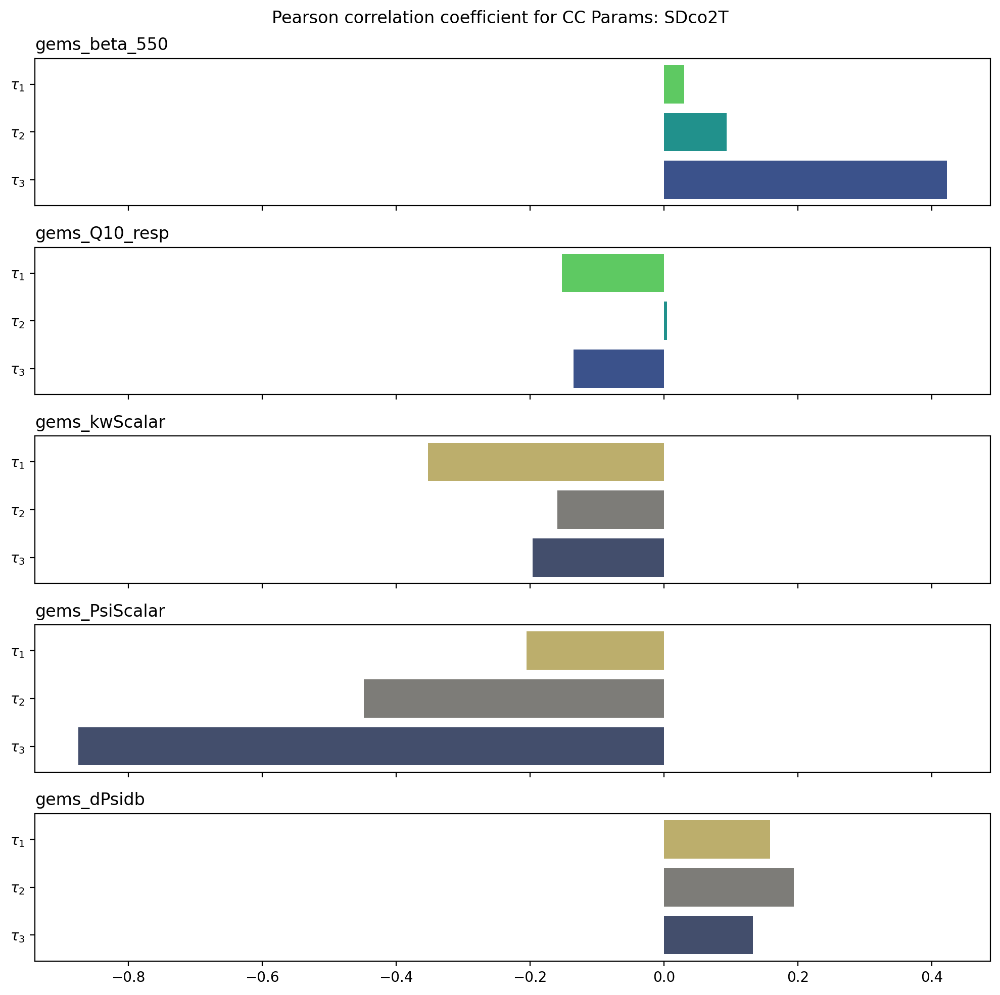

In [195]:
fig, ax = plt.subplots(5, 1, figsize = (10,10), dpi = 200, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
    
                     ]),
            np.array([df_SD_r2_pearson.loc[param,'tau3'],
                      df_SD_r2_pearson.loc[param,'tau2'],
                      df_SD_r2_pearson.loc[param,'tau1'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Pearson correlation coefficient for CC Params: SDco2T')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
# plt.savefig('figures/timescale_variance_explained_by_ccparams_co2T', dpi = 300)
# plt.xlim(0,1)
plt.show();plt.close()

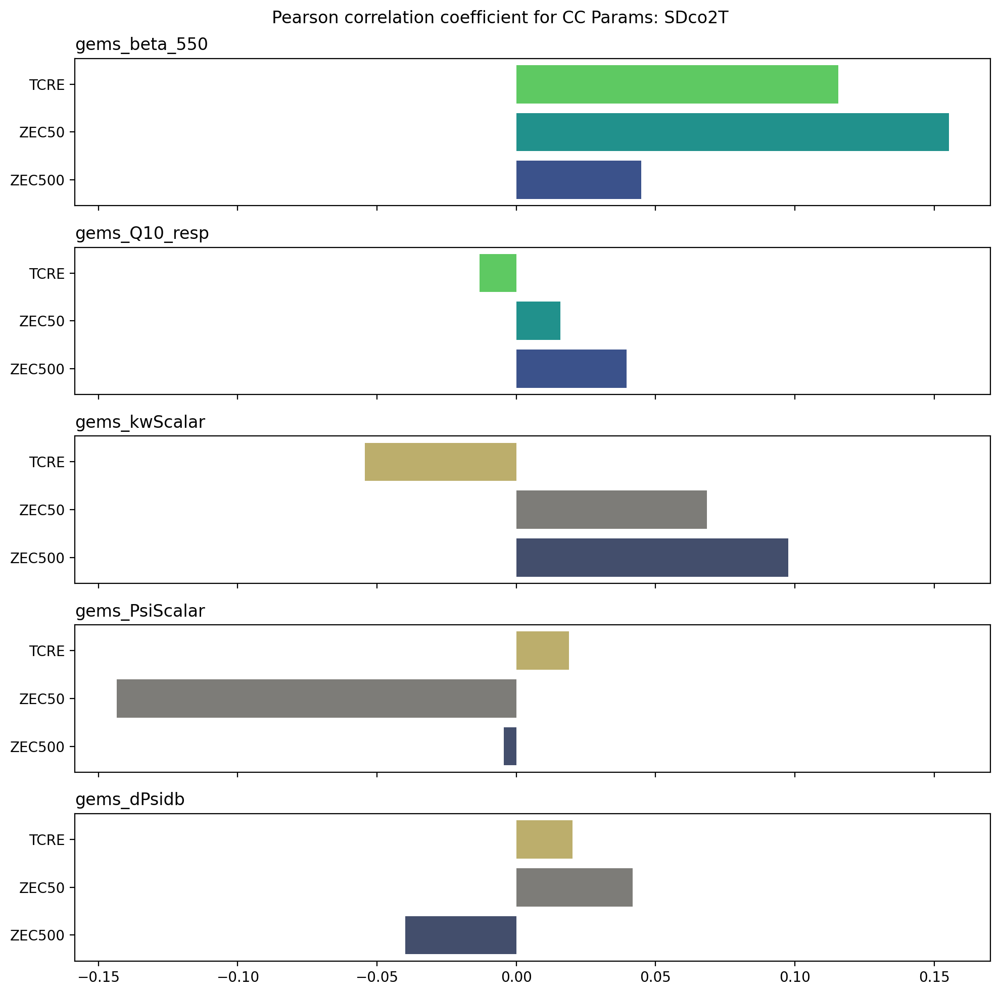

In [196]:
fig, ax = plt.subplots(5, 1, figsize = (10,10), dpi = 200, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE',
    
                     ]),
            np.array([df_SD_r2_pearson.loc[param,'ZEC1000'],
                      df_SD_r2_pearson.loc[param,'ZEC50'],
                      df_SD_r2_pearson.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Pearson correlation coefficient for CC Params: SDco2T')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
# plt.savefig('figures/timescale_variance_explained_by_ccparams_co2T', dpi = 300)
# plt.xlim(0,1)
plt.show();plt.close()

In [197]:
df_SD_r2_pearson.index[18:29]

Index(['clim_gamma', 'clim_c1', 'clim_c2', 'clim_c3', 'clim_kappa1',
       'clim_kappa2', 'clim_kappa3', 'clim_epsilon', 'clim_sigma_eta',
       'clim_sigma_xi', 'clim_F_4xCO2'],
      dtype='object')

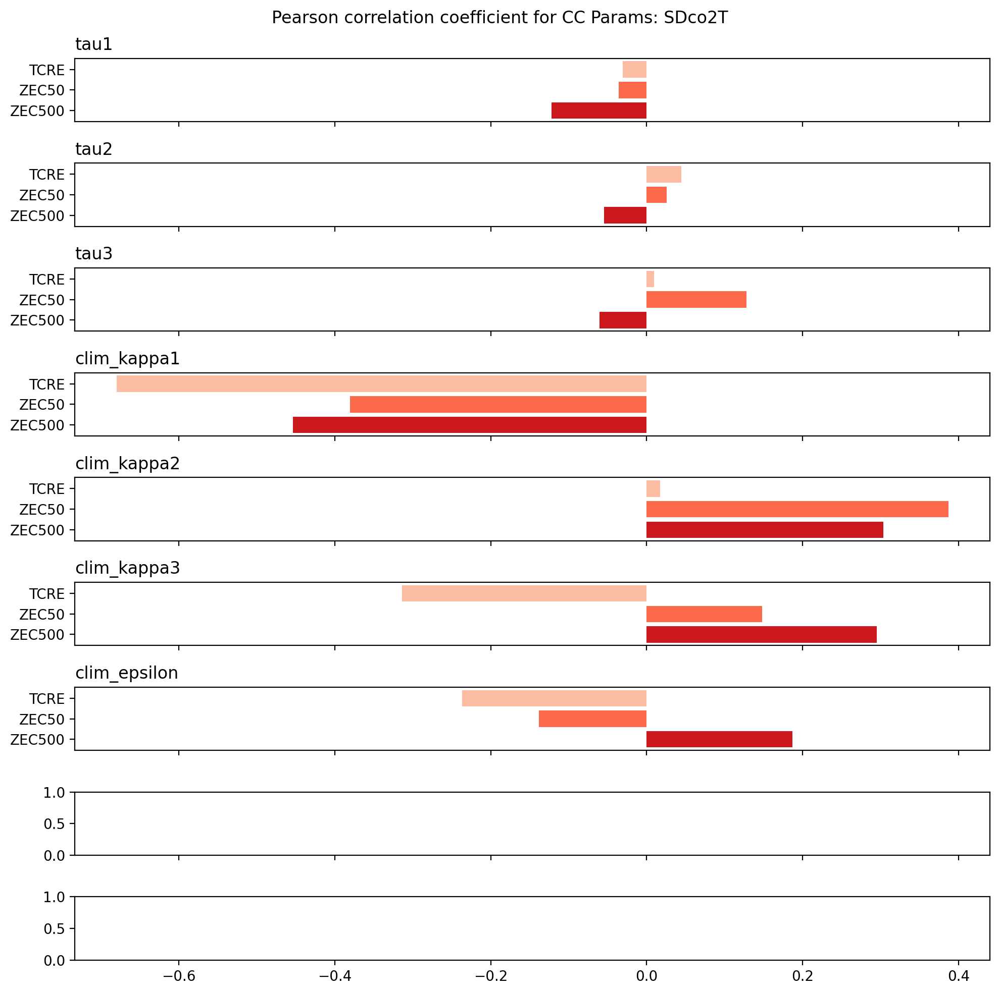

In [198]:
fig, ax = plt.subplots(9, 1, figsize = (10,10), dpi = 200, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['tau1', 'tau2', 'tau3','clim_kappa1','clim_kappa2', 'clim_kappa3', 'clim_epsilon',]):
    if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb']:
        color = sns.color_palette('cividis',3)
    elif param in ['gems_beta_550','gems_Q10_resp']:
        color = sns.color_palette('viridis',3)
    else:
        color = sns.color_palette('Reds_r',3)
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE',
    
                     ]),
            np.array([df_SD_r2_pearson.loc[param,'ZEC1000'],
                      df_SD_r2_pearson.loc[param,'ZEC50'],
                      df_SD_r2_pearson.loc[param,'TCRE1000'],
                     ]),
           color = color)
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Pearson correlation coefficient for CC Params: SDco2T')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ebmparams_co2T', dpi = 300)
# plt.xlim(0,1)
plt.show();plt.close()

In [204]:
# https://www.statology.org/r-squared-in-python/
from sklearn.linear_model import LinearRegression

#initiate linear regression model
model = LinearRegression()

#define predictor and response variables
# X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][['clim_gamma','clim_c1','clim_c2','clim_c3',
#                                            'clim_kappa1','clim_kappa2', 'clim_kappa3', 
#                                            'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
#                                            'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']],df_SDckp.iloc[constrained_by_co2T_SDckp][["ZEC1000"]]
for i in ['tau1','tau2','tau3',
          'clim_gamma','clim_c1','clim_c2','clim_c3',
          'clim_kappa1','clim_kappa2', 'clim_kappa3', 
          'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
          'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']:
    X, y = df_SD.iloc[constrained_by_co2T_SD][[i]],df_SD.iloc[constrained_by_co2T_SD][["ZEC1000"]]

    #fit regression model
    model.fit(X, y)
    
    #calculate R-squared of regression model
    r_squared = model.score(X, y)
    
    #view R-squared value
    print(i, r_squared)

tau1 0.014882840304769274
tau2 0.002970814564024704
tau3 0.0036418804316121767
clim_gamma 0.0005433053578169922
clim_c1 0.0008668691172235565
clim_c2 0.10902450742867231
clim_c3 0.0013336980909858243
clim_kappa1 0.20601411274256032
clim_kappa2 0.09213743739144253
clim_kappa3 0.08713299097375493
clim_epsilon 0.03501203194894076
clim_sigma_eta 0.0003133989110326585
clim_sigma_xi 0.0001367605283623119
clim_F_4xCO2 0.009871530193662714
gems_beta_550 0.0020131387003258228
gems_Q10_resp 0.001565486060292054
gems_kwScalar 0.009553305655251365
gems_PsiScalar 1.971637933295689e-05
gems_dPsidb 0.001591368179654662


In [205]:
# sns.scatterplot()
X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][['clim_kappa1']],df_SDckp.iloc[constrained_by_co2T_SDckp][["TCRE1000"]]

#fit regression model
model.fit(X, y)

LinearRegression()

0.4529373680054912


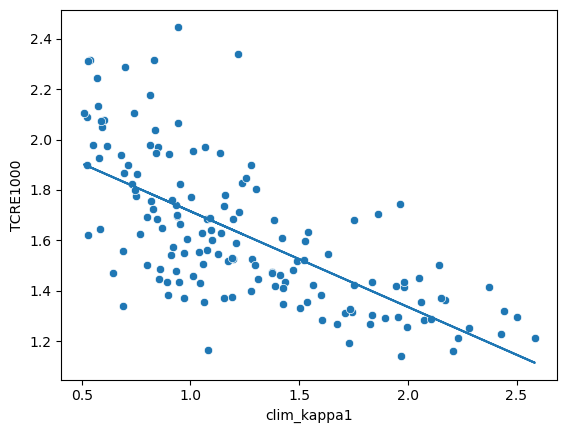

In [206]:
# sns.scatterplot()
X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][['clim_kappa1']],df_SDckp.iloc[constrained_by_co2T_SDckp][["TCRE1000"]]

#fit regression model
model.fit(X, y)
sns.scatterplot(x = df_SDckp.iloc[constrained_by_co2T_SDckp]['clim_kappa1'], y = df_SDckp.iloc[constrained_by_co2T_SDckp]["TCRE1000"])
plt.plot(X, model.predict(X))
print(model.score(X, y))

In [209]:
# https://www.statology.org/r-squared-in-python/
from sklearn.linear_model import LinearRegression

#initiate linear regression model
model = LinearRegression()

#define predictor and response variables
# X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][['clim_gamma','clim_c1','clim_c2','clim_c3',
#                                            'clim_kappa1','clim_kappa2', 'clim_kappa3', 
#                                            'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
#                                            'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']],df_SDckp.iloc[constrained_by_co2T_SDckp][["ZEC1000"]]
for i in ['tau1','tau2','tau3',
          'clim_gamma','clim_c1','clim_c2','clim_c3',
          'clim_kappa1','clim_kappa2', 'clim_kappa3', 
          'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
          'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']:
    X, y = df_SDck.iloc[constrained_by_co2T_SDck][[i]],df_SD.iloc[constrained_by_co2T_SDck][["ZEC1000"]]

    #fit regression model
    model.fit(X, y)
    
    #calculate R-squared of regression model
    r_squared = model.score(X, y)
    
    #view R-squared value
    print(i, r_squared)

tau1 0.0018372351379710716
tau2 0.008199172240105468
tau3 0.012524008871487968
clim_gamma 0.00487518837585621
clim_c1 0.014178344762814654
clim_c2 0.0005218046944291954
clim_c3 0.029861059466772755
clim_kappa1 0.0
clim_kappa2 0.0
clim_kappa3 0.0
clim_epsilon 0.00547130085837233
clim_sigma_eta 0.007444214759259826
clim_sigma_xi 0.0036945294658131678
clim_F_4xCO2 0.006043250002038425
gems_beta_550 0.0025357561884959967
gems_Q10_resp 0.0050396228941615995
gems_kwScalar 0.002080316850697872
gems_PsiScalar 0.0036684131500920314
gems_dPsidb 0.018580688371067522


In [210]:
# https://www.statology.org/r-squared-in-python/
from sklearn.linear_model import LinearRegression

#initiate linear regression model
model = LinearRegression()

#define predictor and response variables
# X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][['clim_gamma','clim_c1','clim_c2','clim_c3',
#                                            'clim_kappa1','clim_kappa2', 'clim_kappa3', 
#                                            'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
#                                            'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']],df_SDckp.iloc[constrained_by_co2T_SDckp][["ZEC1000"]]
for i in ['tau1','tau2','tau3',
          'clim_gamma','clim_c1','clim_c2','clim_c3',
          'clim_kappa1','clim_kappa2', 'clim_kappa3', 
          'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
          'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']:
    X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][[i]],df_SDckp.iloc[constrained_by_co2T_SDckp][["ZEC1000"]]

    #fit regression model
    model.fit(X, y)
    
    #calculate R-squared of regression model
    r_squared = model.score(X, y)
    
    #view R-squared value
    print(i, r_squared)

tau1 0.004029906171411635
tau2 2.780052330952909e-05
tau3 0.04945424985571556
clim_gamma 0.0009868065739168097
clim_c1 0.00012030534322171604
clim_c2 0.03585319310618418
clim_c3 0.00016636749826315356
clim_kappa1 0.4648317686679707
clim_kappa2 0.061817621579787985
clim_kappa3 0.13642513001500423
clim_epsilon 0.04040433010300215
clim_sigma_eta 0.006472696923320309
clim_sigma_xi 0.00032211732562992257
clim_F_4xCO2 0.0008240411783495549
gems_beta_550 0.003017436908425597
gems_Q10_resp 0.007850417537495047
gems_kwScalar 0.004199601051387947
gems_PsiScalar 0.08915980497556242
gems_dPsidb 0.005120794736299117


In [211]:
df_fair

,Unnamed: 0,clim_gamma,clim_c1,clim_c2,clim_c3,clim_kappa1,clim_kappa2,clim_kappa3,clim_epsilon,clim_sigma_eta,...,Fco2_20,Fco2_50,Fco2_100,Fco2_500,Fco2_1000,TL0_20,TL0_50,TL0_100,TL0_500,TL0_1000
0,0,2.445959,2.452934,33.287219,337.204496,0.888274,2.585481,1.858457,1.702734,2.326950,...,1.915281,1.687062,1.525917,1.467226,1.467219,0.929770,0.861086,0.830367,1.063725,1.279513
1,1,25.374588,6.390286,33.035725,183.229463,1.329261,4.655321,1.454788,1.219869,0.238848,...,2.072757,1.905756,1.742133,1.320593,1.296580,0.905632,0.901823,0.904410,0.936871,0.964412
2,2,13.966231,3.506602,64.786343,126.962717,0.966108,8.124577,0.377827,0.749934,0.308652,...,2.769775,2.492864,2.194631,1.796158,1.794769,1.810314,1.932834,1.937217,1.743226,1.817054
3,3,20.390658,4.343631,46.502430,196.157430,1.851074,7.329709,1.836328,1.922053,1.076498,...,2.086275,1.892624,1.690088,1.375120,1.371455,0.602793,0.596478,0.597710,0.675611,0.722885
4,4,26.630411,5.773597,57.611162,101.408429,1.872790,1.278552,2.581051,1.318375,1.878073,...,2.354070,2.122581,1.959057,1.882895,1.882880,0.929191,0.879319,0.859911,0.964316,0.998444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,14.333100,7.004087,66.312193,232.463045,1.747176,1.490316,1.789886,0.551503,1.388421,...,1.716741,1.611991,1.592590,1.591693,1.591677,0.741182,0.725824,0.742864,0.858397,0.898844
996,996,7.163511,5.143595,24.990217,151.470903,1.573063,4.856077,0.286956,1.689726,1.064564,...,3.643613,3.443339,3.233199,2.644177,2.366238,1.812678,1.784935,1.705298,1.528374,1.455109
997,997,3.827561,5.763281,52.464341,329.074854,2.123697,5.291463,0.480648,0.300645,2.459797,...,2.942050,2.683670,2.417910,2.046999,2.044156,1.228332,1.213060,1.124794,0.937218,0.948545
998,998,2.707282,6.416326,8.993852,20.548900,2.334156,7.249047,0.600537,0.443304,1.055709,...,1.854949,1.648924,1.510354,1.464282,1.464274,0.801631,0.720602,0.655386,0.627341,0.627336


In [213]:
df_fair_rsquared_co2T = pd.DataFrame(columns=['TCRE1000', 'ZEC50', 'ZEC100', 'ZEC500', 'ZEC1000', 'Fco2_20',
       'Fco2_50', 'Fco2_100', 'Fco2_500', 'Fco2_1000', 'TL0_20', 'TL0_50',
       'TL0_100', 'TL0_500', 'TL0_1000', 'tau1', 'tau2', 'tau3'],
                             index = ['tau1', 'tau2', 'tau3', 'clim_gamma',
       'clim_c1', 'clim_c2', 'clim_c3', 'clim_kappa1', 'clim_kappa2',
       'clim_kappa3', 'clim_epsilon', 'clim_sigma_eta', 'clim_sigma_xi',
       'clim_F_4xCO2', 'cc_r0', 'cc_rT', 'cc_rU'])

for c in df_fair_rsquared_co2T.columns.to_list():
    for i in df_fair_rsquared_co2T.index.to_list():
        
        X, y = df_fair.iloc[constrained_by_co2T_fair][[i]],df_fair.iloc[constrained_by_co2T_fair][[c]]
    
        #fit regression model
        model.fit(X, y)
        
        #calculate R-squared of regression model
        r_squared = model.score(X, y)
        
        # #view R-squared value
        # print(f'variance in {c} explained by variance in {i} = {r_squared}')

        #place r_squared in dataframe
        df_fair_rsquared_co2T.loc[i,c]  = r_squared
        
df_fair_rsquared_co2T

,TCRE1000,ZEC50,ZEC100,ZEC500,ZEC1000,Fco2_20,Fco2_50,Fco2_100,Fco2_500,Fco2_1000,TL0_20,TL0_50,TL0_100,TL0_500,TL0_1000,tau1,tau2,tau3
tau1,0.055355,0.030943,0.03416,0.010807,0.002673,0.061308,0.072726,0.096017,0.10333,0.021458,0.060739,0.0627,0.06697,0.05303,0.019252,1.0,0.160744,0.036941
tau2,0.000162,0.000582,0.000181,0.000055,0.001878,0.095451,0.085221,0.07772,0.15558,0.128729,0.000299,0.000308,0.000234,0.000181,0.00031,0.160744,1.0,0.07608
tau3,0.001856,0.011855,0.013013,0.004751,0.000001,0.080555,0.090976,0.102794,0.126826,0.084223,0.000611,0.00005,0.000095,0.000056,0.00101,0.036941,0.07608,1.0
clim_gamma,0.012419,0.004291,0.002313,0.000182,0.000164,0.002941,0.002631,0.001888,0.000503,0.001655,0.013025,0.01293,0.011522,0.007903,0.007886,0.008789,0.000213,0.025386
clim_c1,0.042595,0.007534,0.006421,0.000009,0.000926,0.000751,0.001071,0.001186,0.000236,0.000046,0.042584,0.040445,0.038156,0.023167,0.017147,0.009082,0.019693,0.001823
clim_c2,0.001151,0.148493,0.107814,0.033076,0.019787,0.016889,0.019685,0.023672,0.025291,0.017646,0.000363,0.005884,0.009962,0.006069,0.003898,0.001845,0.000008,0.006297
clim_c3,0.000869,0.105082,0.125804,0.050322,0.009337,0.000022,0.000067,0.000178,0.000214,0.000167,0.00019,0.00406,0.012888,0.011048,0.001475,0.00034,0.010518,0.000225
clim_kappa1,0.470861,0.156535,0.172653,0.313071,0.377106,0.050025,0.048077,0.046184,0.054009,0.058349,0.480689,0.487286,0.499909,0.666342,0.770895,0.001099,0.023348,0.020326
clim_kappa2,0.044088,0.093243,0.089081,0.124668,0.110715,0.016088,0.014088,0.011491,0.025241,0.036913,0.025129,0.009309,0.002699,0.002127,0.002866,0.003924,0.055808,0.031361
clim_kappa3,0.016947,0.035884,0.085644,0.206568,0.160884,0.005781,0.006223,0.007056,0.006318,0.00689,0.010159,0.003575,0.000087,0.026101,0.023638,0.0,0.000096,0.017211


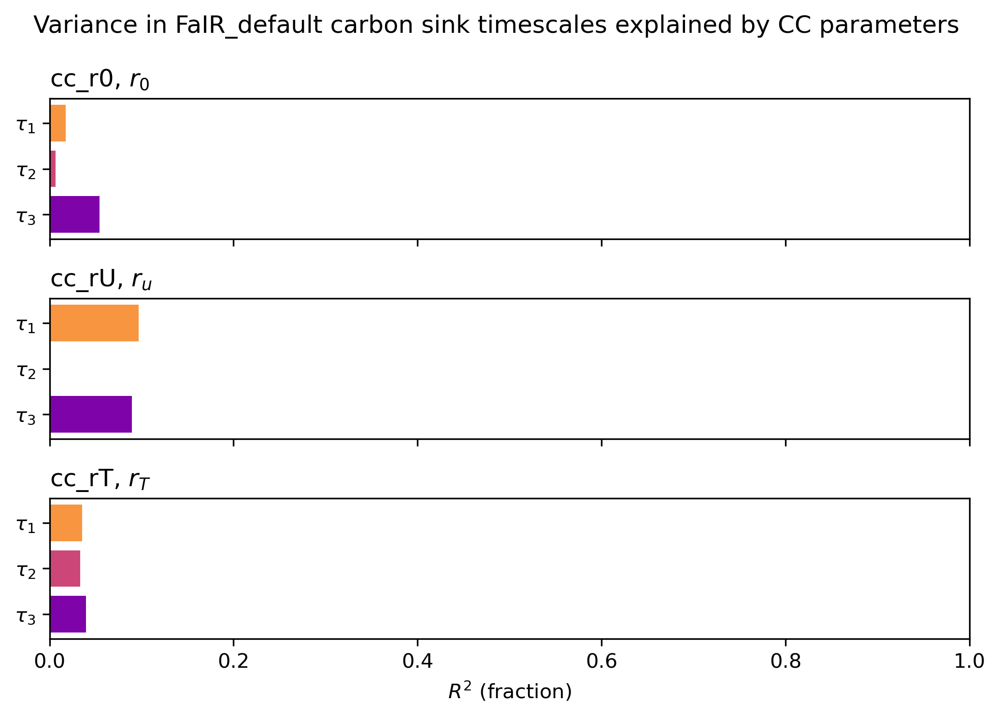

In [371]:
fig, ax = plt.subplots(3, 1, figsize = (7,5), dpi = 300, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['cc_r0','cc_rU','cc_rT',]):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
                     ]),
            np.array([df_fair_rsquared_co2T.loc[param,'tau3'],
                      df_fair_rsquared_co2T.loc[param,'tau2'],
                      df_fair_rsquared_co2T.loc[param,'tau1'],
                     ]),
            color = sns.color_palette('plasma',3))
    if param == 'cc_r0':
        ax[i].set_title(r'cc_r0, $r_0$', loc = 'left')
    if param == 'cc_rT':
        ax[i].set_title(r'cc_rT, $r_T$', loc = 'left')
    if param == 'cc_rU':
        ax[i].set_title(r'cc_rU, $r_u$', loc = 'left')
ax[0].set_xlim(0,1);ax[1].set_xlim(0,1);ax[2].set_xlim(0,1)
plt.suptitle(rf'Variance in FaIR_default carbon sink timescales explained by CC parameters ', fontsize = 12)
ax[2].set_xlabel('$R^2$ (fraction)')
plt.tight_layout()
plt.savefig('figures/rsquared_fairdefault_ccparams_taus_SD', dpi = 300)

plt.show();plt.close()

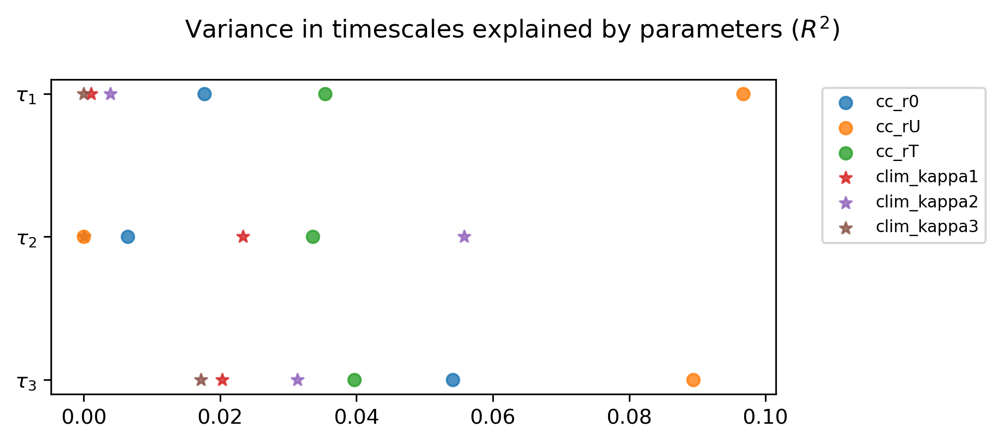

In [324]:
plt.figure(figsize = (7,3), dpi = 300,)
variable = 'ZEC500'


for i, param in enumerate(['cc_r0','cc_rU','cc_rT',]):
    plt.scatter(
            np.array([df_fair_rsquared_co2T.loc[param,'tau3'],
                      df_fair_rsquared_co2T.loc[param,'tau2'],
                      df_fair_rsquared_co2T.loc[param,'tau1'],
                     ]),
        np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
                     ]),label = param, alpha = 0.8, zorder = 6)

for i, param in enumerate(['clim_kappa1','clim_kappa2','clim_kappa3',]):
    plt.scatter(
            np.array([df_fair_rsquared_co2T.loc[param,'tau3'],
                      df_fair_rsquared_co2T.loc[param,'tau2'],
                      df_fair_rsquared_co2T.loc[param,'tau1'],
                     ]),
        np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
                     ]),label = param, marker = '*', alpha = 0.8, zorder = 4)

# for i, param in enumerate(['clim_c1','clim_c2','clim_c3','clim_epsilon','clim_F_4xCO2']):
#     plt.scatter(
#             np.array([df_fair_rsquared_co2T.loc[param,'tau3'],
#                       df_fair_rsquared_co2T.loc[param,'tau2'],
#                       df_fair_rsquared_co2T.loc[param,'tau1'],
#                      ]),
#         np.array([r'$\tau_3$',
#                          r'$\tau_2$',
#                          r'$\tau_1$',
#                      ]),label = param, marker = 's', alpha = 0.8, zorder = 2)
    

plt.legend(bbox_to_anchor = (1.3,1), fontsize = 8)
plt.suptitle(r'Variance in timescales explained by parameters ($R^2$)')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ccparams_co2T_fair', dpi = 300)
# plt.xlim(0,.5)
plt.show();plt.close()

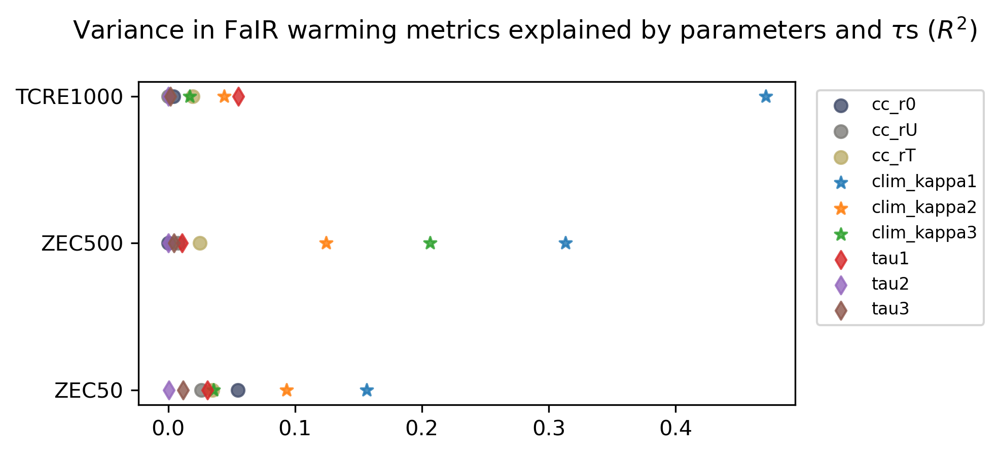

In [337]:
plt.figure(figsize = (7,3), dpi = 300,)
variable = 'ZEC500'

for i, param in enumerate(['cc_r0','cc_rU','cc_rT',]):
    plt.scatter(
            np.array([df_fair_rsquared_co2T.loc[param,'ZEC50'],
                      df_fair_rsquared_co2T.loc[param,'ZEC500'],
                      df_fair_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC50',
                         r'ZEC500',
                         r'TCRE1000',
                     ]),label = param, alpha = 0.8, color = sns.color_palette('cividis',3)[i])
for i, param in enumerate(['clim_kappa1','clim_kappa2','clim_kappa3',]):
    plt.scatter(
            np.array([df_fair_rsquared_co2T.loc[param,'ZEC50'],
                      df_fair_rsquared_co2T.loc[param,'ZEC500'],
                      df_fair_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC50',
                         r'ZEC500',
                         r'TCRE1000',
                     ]),label = param, marker = '*', alpha = 0.8, )

# for i, param in enumerate(['clim_c1','clim_c2','clim_c3','clim_epsilon','clim_F_4xCO2']):
#     plt.scatter(
#             np.array([df_fair_rsquared_co2T.loc[param,'ZEC50'],
#                       df_fair_rsquared_co2T.loc[param,'ZEC500'],
#                       df_fair_rsquared_co2T.loc[param,'TCRE1000'],
#                      ]),
        # np.array([r'ZEC50',
        #                  r'ZEC500',
        #                  r'TCRE1000',
        #              ]),label = param, marker = 's', alpha = 0.8, s = 20)

for i, param in enumerate(['tau1','tau2','tau3']):
    plt.scatter(
            np.array([df_fair_rsquared_co2T.loc[param,'ZEC50'],
                      df_fair_rsquared_co2T.loc[param,'ZEC500'],
                      df_fair_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC50',
                         r'ZEC500',
                         r'TCRE1000',
                     ]),label = param, marker = 'd', alpha = 0.8, )

plt.legend(bbox_to_anchor = (1.3,1), fontsize = 8)
plt.suptitle(r'Variance in FaIR warming metrics explained by parameters and $\tau$s ($R^2$)')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ebmparams_co2T_fair', dpi = 300)
# plt.xlim(0,1)
plt.show();plt.close()

In [275]:
df_SD_rsquared_co2T = pd.DataFrame(columns=['TCRE1000', 'ZEC50', 'ZEC100', 'ZEC500', 'ZEC1000', 'Fco2_20',
       'Fco2_50', 'Fco2_100', 'Fco2_500', 'Fco2_1000', 'TL0_20', 'TL0_50',
       'TL0_100', 'TL0_500', 'TL0_1000', 'tau1', 'tau2', 'tau3'],
                             index = ['tau1', 'tau2', 'tau3', 'clim_gamma',
       'clim_c1', 'clim_c2', 'clim_c3', 'clim_kappa1', 'clim_kappa2',
       'clim_kappa3', 'clim_epsilon', 'clim_sigma_eta', 'clim_sigma_xi',
       'clim_F_4xCO2', 'gems_beta_550', 'gems_Q10_resp', 'gems_kwScalar',
       'gems_PsiScalar', 'gems_dPsidb'])

for c in df_SD_rsquared_co2T.columns.to_list():
    for i in df_SD_rsquared_co2T.index.to_list():
        # remove this when the taus are finished and remove indent below:
        # if i in ['tau1', 'tau2', 'tau3']:
        #     X, y = df_SD.iloc[top100_co2_SD][[i]],df_SD.iloc[top100_co2_SD][[c]]
        # elif c in ['tau1', 'tau2', 'tau3']:
        #     X, y = df_SD.iloc[top100_co2_SD][[i]],df_SD.iloc[top100_co2_SD][[c]]
        # else:
        # remove this when the taus are finished and remove indent below:
        X, y = df_SD.iloc[constrained_by_co2T_SD][[i]],df_SD.iloc[constrained_by_co2T_SD][[c]]
    
        #fit regression model
        model.fit(X, y)
        
        #calculate R-squared of regression model
        r_squared = model.score(X, y)
        
        # #view R-squared value
        # print(f'variance in {c} explained by variance in {i} = {r_squared}')

        #place r_squared in dataframe
        df_SD_rsquared_co2T.loc[i,c]  = r_squared
        
df_SD_rsquared_co2T

,TCRE1000,ZEC50,ZEC100,ZEC500,ZEC1000,Fco2_20,Fco2_50,Fco2_100,Fco2_500,Fco2_1000,TL0_20,TL0_50,TL0_100,TL0_500,TL0_1000,tau1,tau2,tau3
tau1,0.000964,0.001281,0.001625,0.007814,0.014883,0.004189,0.005162,0.006437,0.014211,0.025388,0.001153,0.001384,0.001746,0.005502,0.009733,1.0,0.495598,0.292335
tau2,0.001956,0.000671,0.00016,0.000256,0.002971,0.001939,0.002276,0.001434,0.000005,0.004717,0.002131,0.002184,0.001913,0.000894,0.00004,0.495598,1.0,0.372373
tau3,0.000089,0.016422,0.013842,0.000685,0.003642,0.004035,0.002871,0.002871,0.003613,0.028593,0.000545,0.001649,0.002486,0.000492,0.000744,0.292335,0.372373,1.0
clim_gamma,0.000073,0.002398,0.001079,0.000252,0.000543,0.005496,0.005219,0.005024,0.004583,0.006728,0.000196,0.000401,0.000367,0.000253,0.000446,0.005711,0.013449,0.025337
clim_c1,0.00138,0.000045,0.000118,0.000968,0.000867,0.003918,0.003478,0.00333,0.003297,0.004444,0.001242,0.001034,0.000851,0.000245,0.000223,0.002658,0.000687,0.001216
clim_c2,0.028505,0.141722,0.119736,0.108797,0.109025,0.004857,0.004733,0.004604,0.003826,0.003524,0.014628,0.003565,0.000784,0.000866,0.002264,0.000082,0.00096,0.000081
clim_c3,0.009016,0.101904,0.097122,0.010828,0.001334,0.004903,0.004566,0.004053,0.003481,0.006636,0.016197,0.027613,0.037704,0.019062,0.003713,0.007658,0.005616,0.037082
clim_kappa1,0.462406,0.144777,0.131937,0.189755,0.206014,0.003171,0.004121,0.005098,0.008972,0.011644,0.488333,0.510003,0.5358,0.678062,0.734338,0.00986,0.000024,0.001278
clim_kappa2,0.000287,0.149613,0.141448,0.115551,0.092137,0.025588,0.026467,0.028885,0.034969,0.035781,0.003574,0.012547,0.021785,0.038501,0.037299,0.014639,0.019689,0.002613
clim_kappa3,0.098627,0.02183,0.0545,0.100795,0.087133,0.000481,0.000479,0.000402,0.000111,0.00034,0.082999,0.062018,0.03867,0.010683,0.009805,0.007843,0.00346,0.003466


<Axes: >

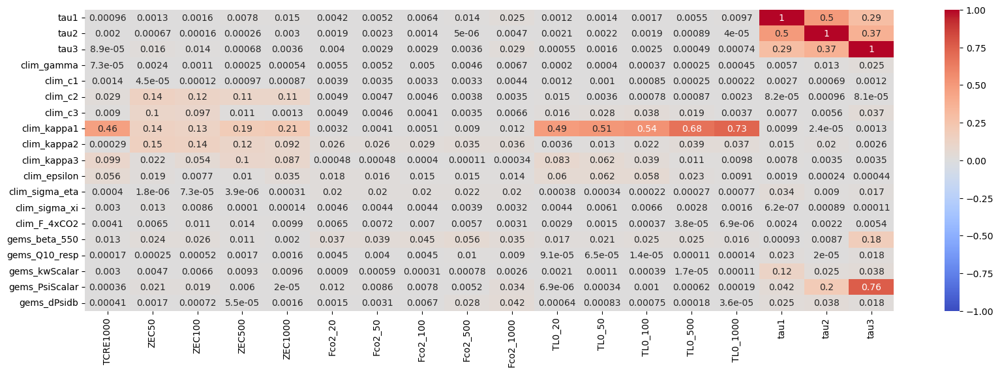

In [276]:
plt.figure(figsize=(20, 6))
sns.heatmap(df_SD_rsquared_co2T.astype(float), vmin=-1, vmax=1, annot=True, cmap = 'coolwarm')

In [277]:
df_SD_rsquared_co2T.loc['gems_beta_550','tau3']

0.17871134222656393

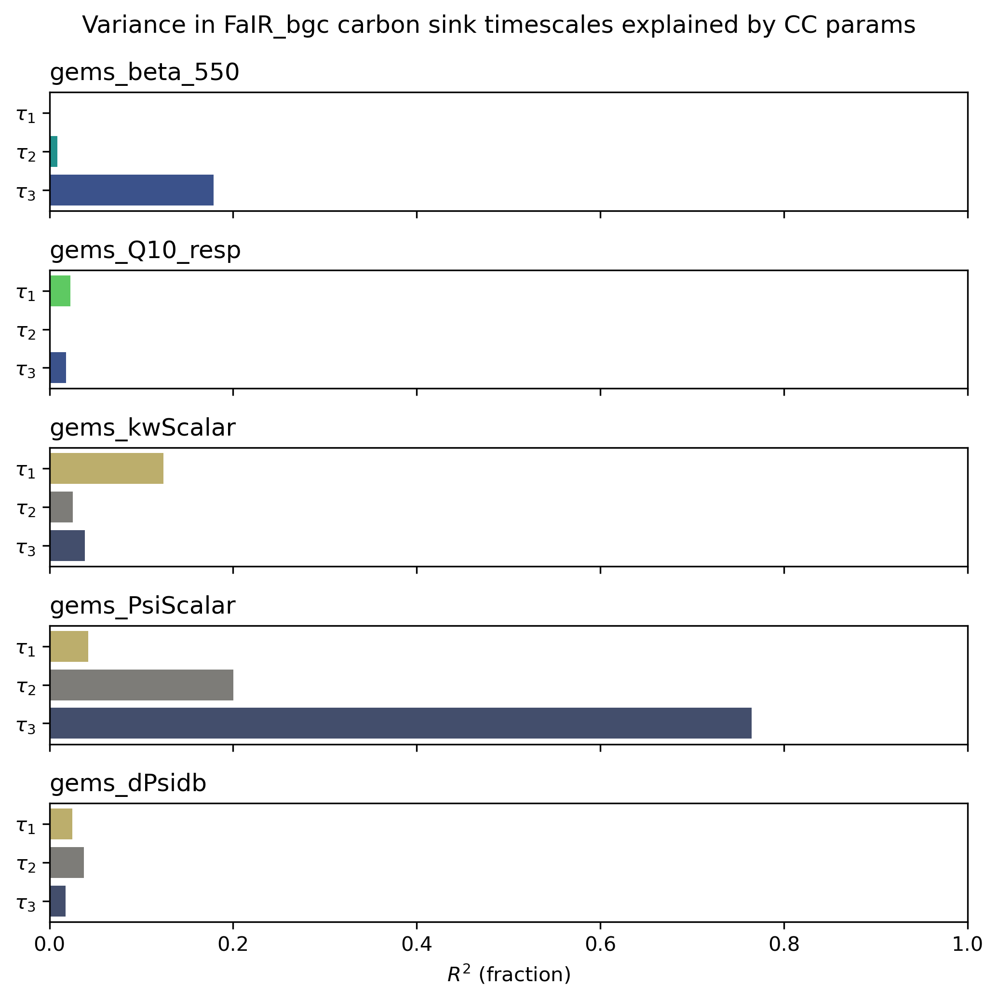

In [372]:
fig, ax = plt.subplots(5, 1, figsize = (7,7), dpi = 300, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
    
                     ]),
            np.array([df_SD_rsquared_co2T.loc[param,'tau3'],
                      df_SD_rsquared_co2T.loc[param,'tau2'],
                      df_SD_rsquared_co2T.loc[param,'tau1'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')
ax[0].set_xlim(0,1)
plt.suptitle(rf'Variance in FaIR_bgc carbon sink timescales explained by CC params')
ax[4].set_xlabel('$R^2$ (fraction)')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ccparams_co2T', dpi = 300)
plt.show();plt.close()

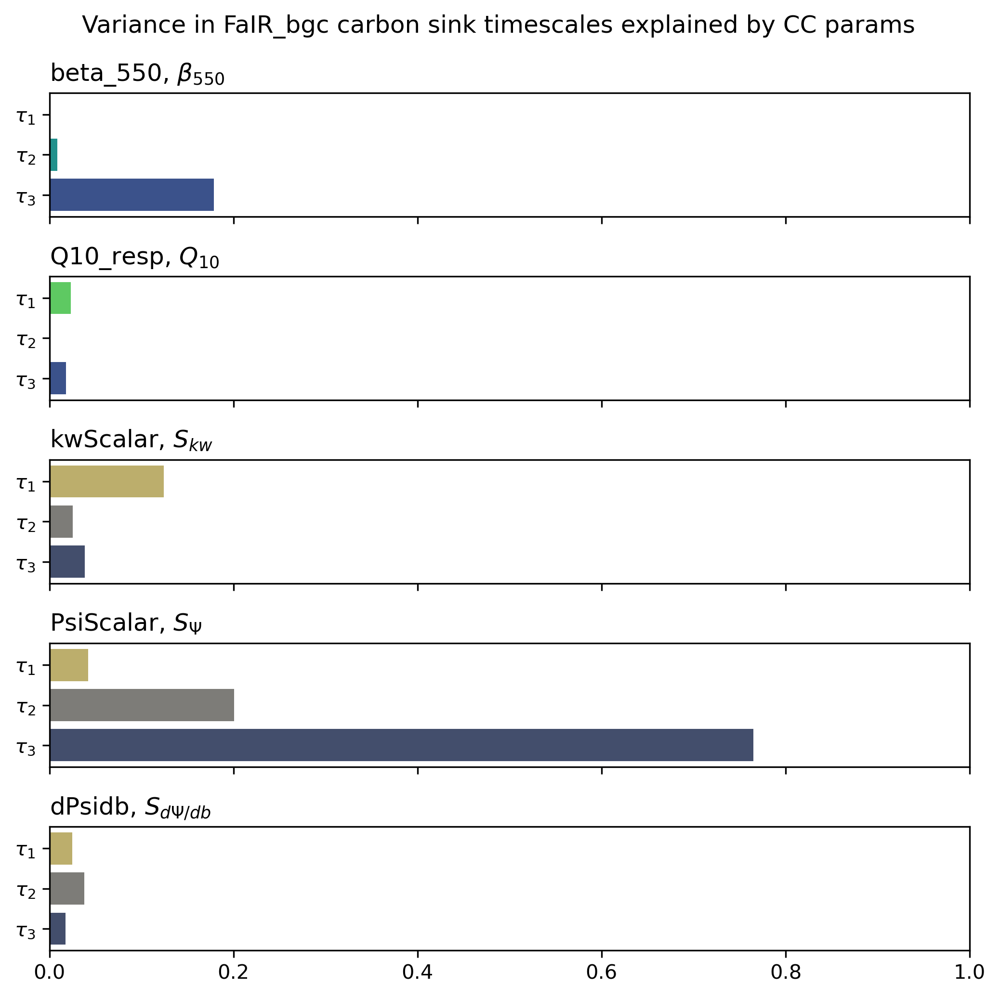

In [370]:
fig, ax = plt.subplots(5, 1, figsize = (7,7), dpi = 300, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
    
                     ]),
            np.array([df_SD_rsquared_co2T.loc[param,'tau3'],
                      df_SD_rsquared_co2T.loc[param,'tau2'],
                      df_SD_rsquared_co2T.loc[param,'tau1'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
ax[0].set_title(r'beta_550, $\beta_{550}$', loc = 'left')
ax[1].set_title(r'Q10_resp, $Q_{10}$', loc = 'left')
ax[2].set_title(r'kwScalar, $S_{kw}$', loc = 'left')
ax[3].set_title(r'PsiScalar, $S_{\Psi}$', loc = 'left')
ax[4].set_title(r'dPsidb, $S_{d\Psi/db}$', loc = 'left')

plt.suptitle(rf'Variance in FaIR_bgc carbon sink timescales explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ccparams_co2T_SD', dpi = 300)
plt.xlim(0,1)
plt.show();plt.close()

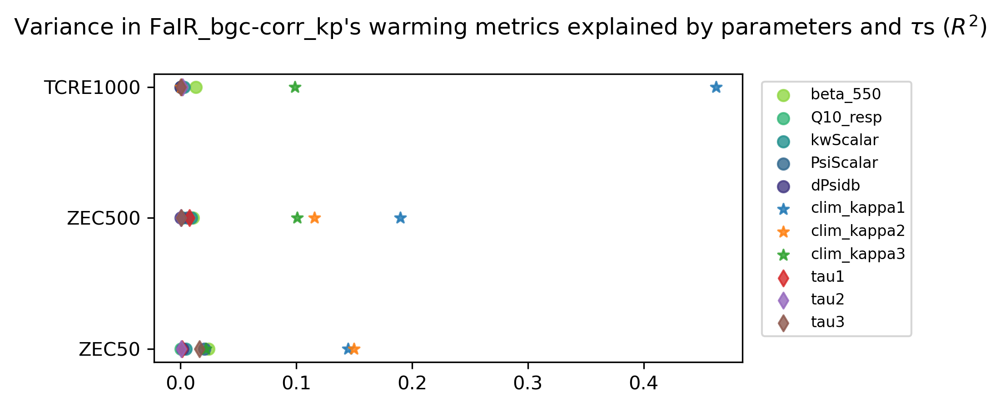

In [349]:
plt.figure(figsize = (7,3), dpi = 300,)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb',]):
    plt.scatter(
            np.array([df_SD_rsquared_co2T.loc[param,'ZEC50'],
                      df_SD_rsquared_co2T.loc[param,'ZEC500'],
                      df_SD_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC50',
                         r'ZEC500',
                         r'TCRE1000',
                     ]),label = param[5:], alpha = 0.8,color = sns.color_palette('viridis_r',5)[i]
    )
for i, param in enumerate(['clim_kappa1','clim_kappa2','clim_kappa3',]):
    plt.scatter(
            np.array([df_SD_rsquared_co2T.loc[param,'ZEC50'],
                      df_SD_rsquared_co2T.loc[param,'ZEC500'],
                      df_SD_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC50',
                         r'ZEC500',
                         r'TCRE1000',
                     ]),label = param, marker = '*', alpha = 0.8, )

# for i, param in enumerate(['clim_c1','clim_c2','clim_c3','clim_epsilon','clim_F_4xCO2']):
#     plt.scatter(
#             np.array([df_SD_rsquared_co2T.loc[param,'ZEC50'],
#                       df_SD_rsquared_co2T.loc[param,'ZEC500'],
#                       df_SD_rsquared_co2T.loc[param,'TCRE1000'],
#                      ]),
        # np.array([r'ZEC50',
        #                  r'ZEC500',
        #                  r'TCRE1000',
        #              ]),label = param, marker = 's', alpha = 0.8, s = 20)

for i, param in enumerate(['tau1','tau2','tau3']):
    plt.scatter(
            np.array([df_SD_rsquared_co2T.loc[param,'ZEC50'],
                      df_SD_rsquared_co2T.loc[param,'ZEC500'],
                      df_SD_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC50',
                         r'ZEC500',
                         r'TCRE1000',
                     ]),label = param, marker = 'd', alpha = 0.8,)

plt.legend(bbox_to_anchor = (1.3,1), fontsize = 8)
# plt.margins(0.1) 

plt.suptitle(r"Variance in FaIR_bgc-corr_kp's warming metrics explained by parameters and $\tau$s ($R^2$)")
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ebmparams_co2T_fairSD', dpi = 300)
# plt.xlim(0,1)
plt.show();plt.close()

In [355]:
params_fairSD.loc[435]

Unnamed: 0                                          4.350000e+02
clim_gamma                                          9.346956e+00
clim_c1                                             7.469964e+00
clim_c2                                             6.005630e+01
clim_c3                                             1.901962e+02
clim_kappa1                                         1.201942e+00
clim_kappa2                                         7.344098e+00
clim_kappa3                                         2.158236e+00
clim_epsilon                                        7.709348e-01
clim_sigma_eta                                      1.015436e+00
clim_sigma_xi                                       7.952668e-01
clim_F_4xCO2                                        4.647990e+00
cc_r0                                               3.888562e+01
cc_rU                                               5.660902e-03
cc_rT                                               1.093389e+00
cc_rA                    

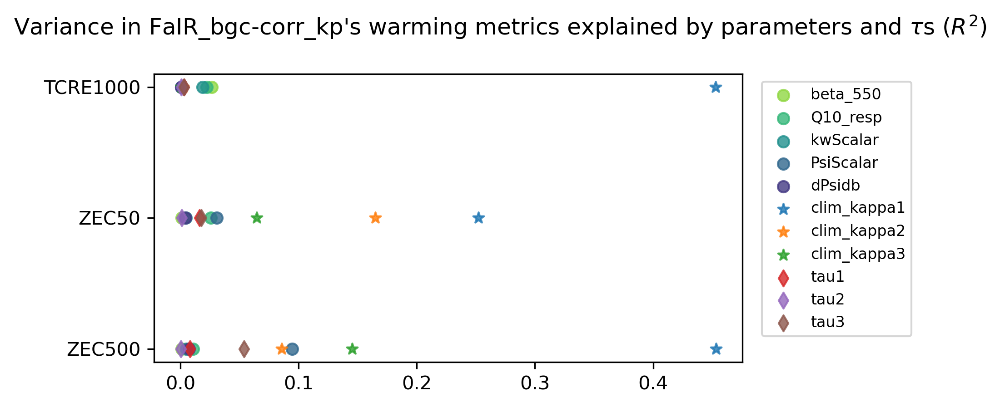

In [348]:
plt.figure(figsize = (7,3), dpi = 300,)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb',]):
    plt.scatter(
            np.array([df_SDckp_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDckp_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC500',
                  r'ZEC50',
                  r'TCRE1000',
                     ]),label = param[5:], alpha = 0.8, color = sns.color_palette('viridis_r',5)[i])
for i, param in enumerate(['clim_kappa1','clim_kappa2','clim_kappa3',]):
    plt.scatter(
            np.array([df_SDckp_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDckp_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
        np.array([r'ZEC500',
                  r'ZEC50',
                  r'TCRE1000',
                     ]),label = param, marker = '*', alpha = 0.8, )

# for i, param in enumerate(['clim_c1','clim_c2','clim_c3','clim_epsilon','clim_F_4xCO2']):
#     plt.scatter(
#             np.array([df_SD_rsquared_co2T.loc[param,'ZEC50'],
#                       df_SD_rsquared_co2T.loc[param,'ZEC500'],
#                       df_SD_rsquared_co2T.loc[param,'TCRE1000'],
#                      ]),
        # np.array([r'ZEC50',
        #                  r'ZEC500',
        #                  r'TCRE1000',
        #              ]),label = param, marker = 's', alpha = 0.8, s = 20)

for i, param in enumerate(['tau1','tau2','tau3']):
    plt.scatter(
            np.array([df_SDckp_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDckp_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],                      
                     ]),
        np.array([r'ZEC500',
                  r'ZEC50',
                  r'TCRE1000',
                     ]),label = param, marker = 'd', alpha = 0.8,)
# plt.margins(0.1) 

plt.legend(bbox_to_anchor = (1.3,1), fontsize = 8)
plt.suptitle(r"Variance in FaIR_bgc-corr_kp's warming metrics explained by parameters and $\tau$s ($R^2$)")
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ebmparams_co2T_fairSDckp', dpi = 300)
# plt.xlim(0,1)
plt.show();plt.close()

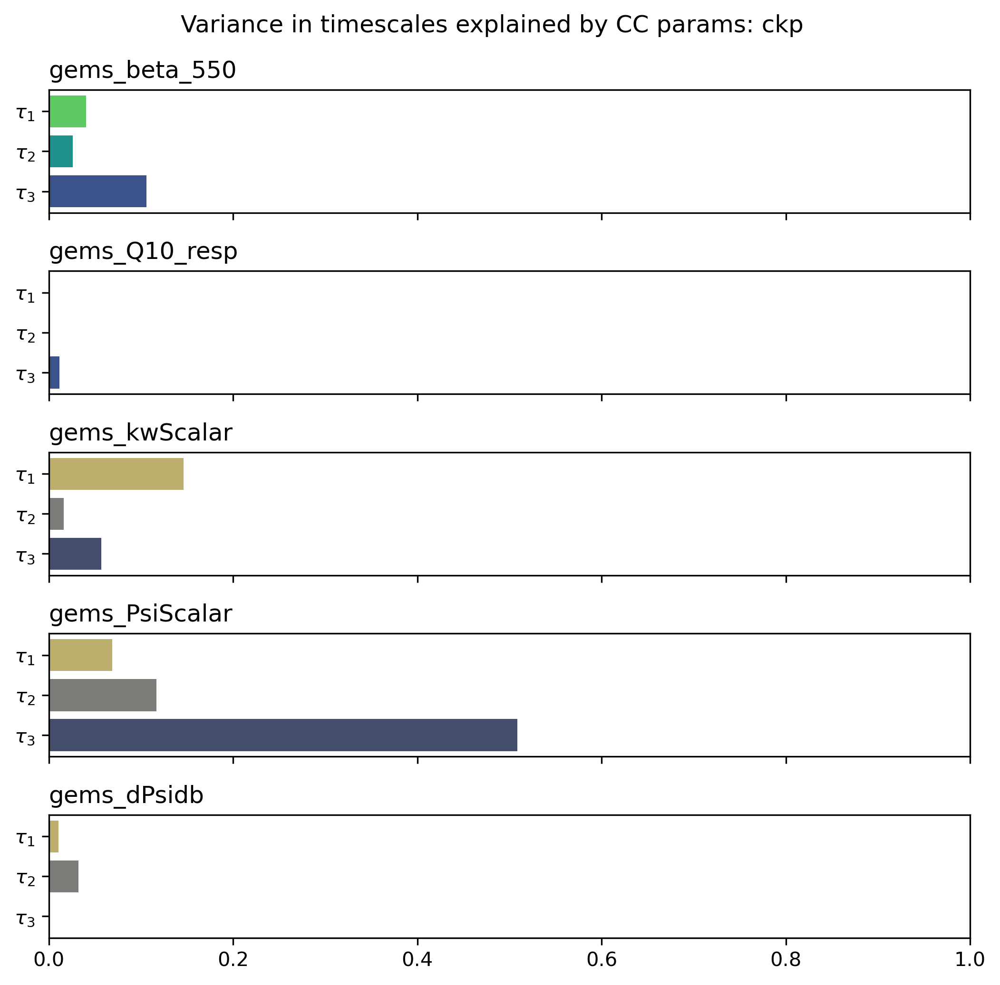

In [2641]:
fig, ax = plt.subplots(5, 1, figsize = (7,7), dpi = 300, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
    
                     ]),
            np.array([df_SDckp_rsquared_co2T.loc[param,'tau3'],
                      df_SDckp_rsquared_co2T.loc[param,'tau2'],
                      df_SDckp_rsquared_co2T.loc[param,'tau1'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Variance in timescales explained by CC params: ckp')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ccparams_co2T_ckp', dpi = 300)
plt.xlim(0,1)
plt.show();plt.close()

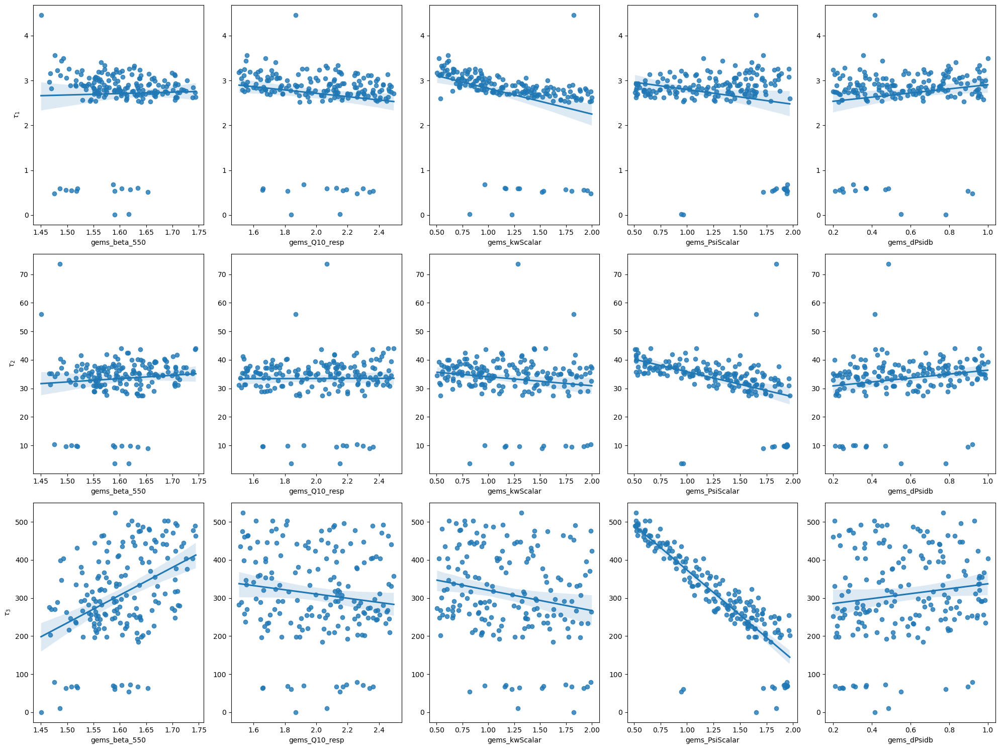

In [2528]:
fig, ax = plt.subplots(3, 5, figsize = (20,15), )


for i , param in enumerate(['gems_beta_550', 'gems_Q10_resp', 'gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']):
    sns.regplot(x = ds_params_fairSD[param][np.array(constrained_by_co2T_SD).astype(int)],#.where(ds_params_fairSD['tau3']>100), 
                    y = np.array(df_SD['tau1'])[constrained_by_co2T_SD], ax = ax[0,i])
    sns.regplot(x = ds_params_fairSD[param][np.array(constrained_by_co2T_SD).astype(int)],#.where(ds_params_fairSD['tau3']>100), 
                    y = np.array(df_SD['tau2'])[constrained_by_co2T_SD], ax = ax[1,i])
    sns.regplot(x = ds_params_fairSD[param][np.array(constrained_by_co2T_SD).astype(int)],#.where(ds_params_fairSD['tau3']>100), 
                    y = np.array(df_SD['tau3'])[constrained_by_co2T_SD], ax = ax[2,i])#;ax[2,i].set_ylim(-100,900)
    ax[0,0].set_ylabel(rf'$\tau_1$')
    ax[1,0].set_ylabel(rf'$\tau_2$')
    ax[2,0].set_ylabel(rf'$\tau_3$')

plt.tight_layout();plt.show();plt.close()

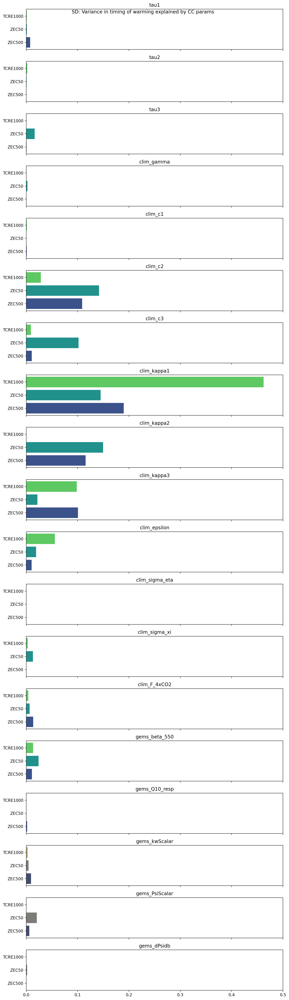

In [2038]:
fig, ax = plt.subplots(len(df_SDck_rsquared_co2T.index.to_list()), 1, 
                       figsize = (10,35),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(df_SD_rsquared_co2T.index.to_list()):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SD_rsquared_co2T.loc[param,'ZEC500'],
                      df_SD_rsquared_co2T.loc[param,'ZEC50'],
                      df_SD_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param)

plt.suptitle(rf'SD: Variance in timing of warming explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SD_co2T', dpi = 300)
plt.xlim(0,0.5)

plt.show();plt.close()

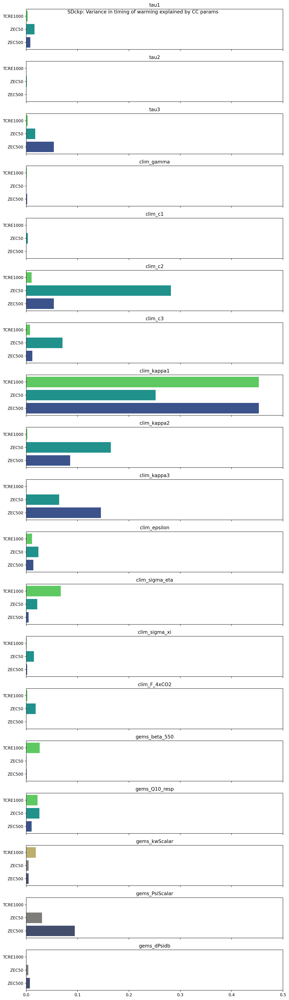

In [2642]:
fig, ax = plt.subplots(len(df_SDck_rsquared_co2T.index.to_list()), 1, 
                       figsize = (10,35),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(df_SD_rsquared_co2T.index.to_list()):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SDckp_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDckp_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param)

plt.suptitle(rf'SDckp: Variance in timing of warming explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SDckp_co2T', dpi = 300)
plt.xlim(0,0.5)

plt.show();plt.close()

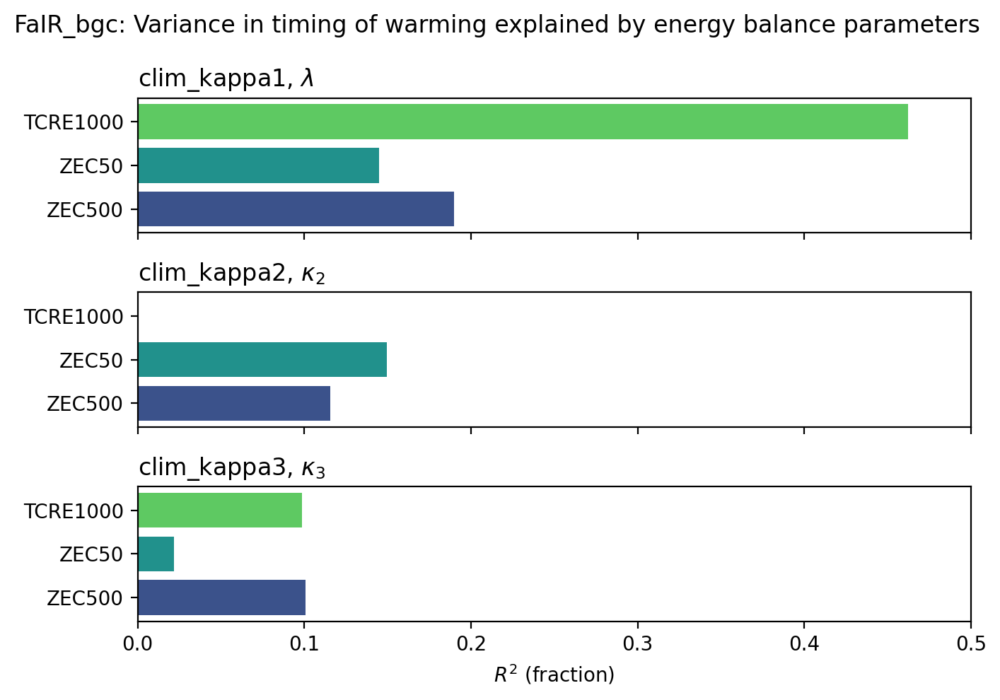

In [382]:
fig, ax = plt.subplots(3, 1, 
                       figsize = (7,5),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate([#'tau1', 'tau2', 'tau3', 
                           'clim_kappa1', 'clim_kappa2', 'clim_kappa3'
                          ]):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SD_rsquared_co2T.loc[param,'ZEC500'],
                      df_SD_rsquared_co2T.loc[param,'ZEC50'],
                      df_SD_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    
ax[0].set_title(rf'clim_kappa1, $\lambda$', loc = 'left')
ax[1].set_title(rf'clim_kappa2, $\kappa_2$', loc = 'left')
ax[2].set_title(rf'clim_kappa3, $\kappa_3$', loc = 'left')

plt.suptitle(rf'FaIR_bgc: Variance in warming metrics explained by energy balance parameters')
ax[2].set_xlabel('$R^2$ (fraction)')
plt.tight_layout()
plt.savefig('figures/rsquared_fairbgc_ebmparams', dpi = 300)
plt.xlim(0,0.5)

plt.show();plt.close()

In [1953]:
df_SDck_rsquared_co2T = pd.DataFrame(columns=['TCRE1000', 'ZEC50', 'ZEC100', 'ZEC500', 'ZEC1000', 'Fco2_20',
       'Fco2_50', 'Fco2_100', 'Fco2_500', 'Fco2_1000', 'TL0_20', 'TL0_50',
       'TL0_100', 'TL0_500', 'TL0_1000', 'tau1', 'tau2', 'tau3'],
                             index = ['tau1', 'tau2', 'tau3', 'clim_gamma',
       'clim_c1', 'clim_c2', 'clim_c3', 'clim_kappa1', 'clim_kappa2',
       'clim_kappa3', 'clim_epsilon', 'clim_sigma_eta', 'clim_sigma_xi',
       'clim_F_4xCO2', 'gems_beta_550', 'gems_Q10_resp', 'gems_kwScalar',
       'gems_PsiScalar', 'gems_dPsidb'])

for c in df_SDck_rsquared_co2T.columns.to_list():
    for i in df_SDck_rsquared_co2T.index.to_list():
        # remove this when the taus are finished and remove indent below:
        if i in ['tau1', 'tau2', 'tau3']:
            X, y = df_SDck.iloc[constrained_by_co2T_SDck][[i]],df_SDck.iloc[constrained_by_co2T_SDck][[c]]
        elif c in ['tau1', 'tau2', 'tau3']:
            X, y = df_SDck.iloc[constrained_by_co2T_SDck][[i]],df_SDck.iloc[constrained_by_co2T_SDck][[c]]
        else:
        # remove this when the taus are finished and remove indent below:
            X, y = df_SDck.iloc[constrained_by_co2T_SDck][[i]],df_SDck.iloc[constrained_by_co2T_SDck][[c]]
    
        #fit regression model
        model.fit(X, y)
        
        #calculate R-squared of regression model
        r_squared = model.score(X, y)
        
        # #view R-squared value
        # print(f'variance in {c} explained by variance in {i} = {r_squared}')

        #place r_squared in dataframe
        df_SDck_rsquared_co2T.loc[i,c]  = r_squared
        
df_SDck_rsquared_co2T

,TCRE1000,ZEC50,ZEC100,ZEC500,ZEC1000,Fco2_20,Fco2_50,Fco2_100,Fco2_500,Fco2_1000,TL0_20,TL0_50,TL0_100,TL0_500,TL0_1000,tau1,tau2,tau3
tau1,0.00805,0.003139,0.000919,0.000822,0.000991,0.000466,0.00145,0.002336,0.007591,0.01041,0.012057,0.016694,0.018097,0.011216,0.011038,1.0,0.000042,0.017726
tau2,0.001585,0.000273,0.000296,0.002685,0.000881,0.015797,0.016729,0.017059,0.019819,0.014112,0.001462,0.001284,0.003932,0.023716,0.016552,0.000042,1.0,0.032374
tau3,0.000062,0.000276,0.000541,0.007959,0.00042,0.039126,0.046129,0.047625,0.042962,0.001292,0.00013,0.000302,0.000803,0.026032,0.002796,0.017726,0.032374,1.0
clim_gamma,0.000439,0.000066,0.000011,0.000001,0.000528,0.000527,0.000668,0.001133,0.003155,0.00946,0.000459,0.000368,0.000804,0.001187,0.006645,0.011742,0.013669,0.019063
clim_c1,0.030707,0.016178,0.0265,0.051819,0.052384,0.006871,0.006937,0.007668,0.009491,0.011766,0.026796,0.016772,0.007118,0.006049,0.011978,0.000113,0.021201,0.000076
clim_c2,0.056895,0.613949,0.459984,0.162969,0.11895,0.041528,0.04015,0.041747,0.041213,0.037282,0.008549,0.019769,0.063539,0.068356,0.044795,0.000141,0.014156,0.007364
clim_c3,0.035829,0.090752,0.071575,0.004828,0.024988,0.001288,0.001196,0.000917,0.000611,0.000069,0.070998,0.135135,0.200154,0.043468,0.002435,0.03016,0.00008,0.045001
clim_kappa1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
clim_kappa2,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,0.0
clim_kappa3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0


<Axes: >

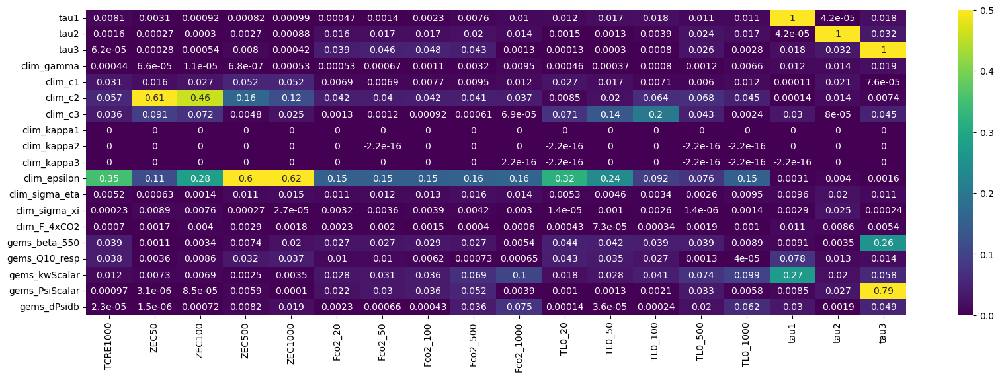

In [1954]:
plt.figure(figsize=(20, 6))
sns.heatmap(df_SDck_rsquared_co2T.astype(float), vmin=0, vmax=0.5, annot=True, cmap = 'viridis')

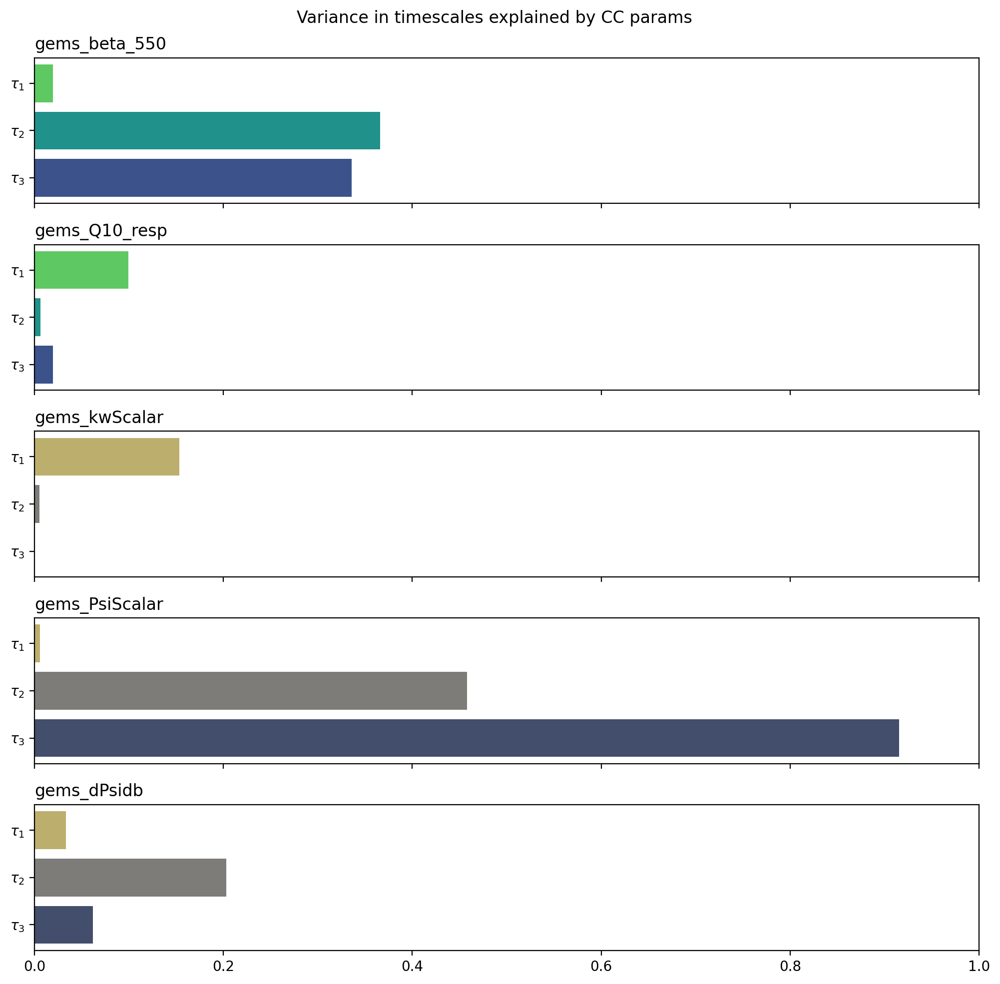

In [1741]:
fig, ax = plt.subplots(5, 1, figsize = (10,10), dpi = 200, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
    
                     ]),
            np.array([df_SDck_rsquared_co2T.loc[param,'tau3'],
                      df_SDck_rsquared_co2T.loc[param,'tau2'],
                      df_SDck_rsquared_co2T.loc[param,'tau1'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Variance in timescales explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ccparams_SDck_co2T', dpi = 300)
plt.xlim(0,1)
plt.show();plt.close()

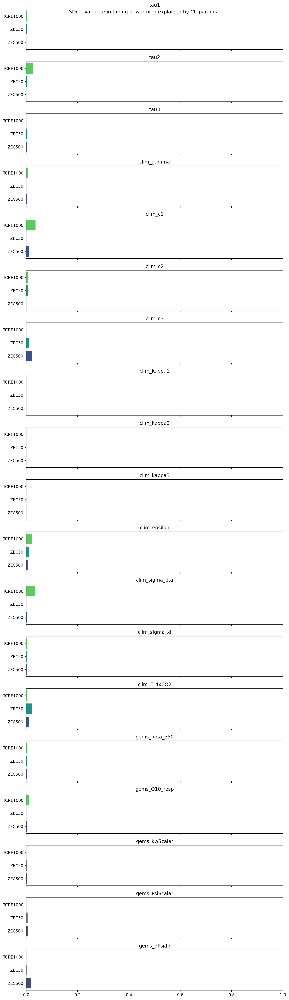

In [1756]:
fig, ax = plt.subplots(len(df_SDck_rsquared_co2T.index.to_list()), 1, 
                       figsize = (10,35),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(df_SDckp_rsquared_co2T.index.to_list()):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SDck_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDck_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDck_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param)

plt.suptitle(rf'SDck: Variance in timing of warming explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SDck_co2T', dpi = 300)
plt.xlim(0,1)

plt.show();plt.close()

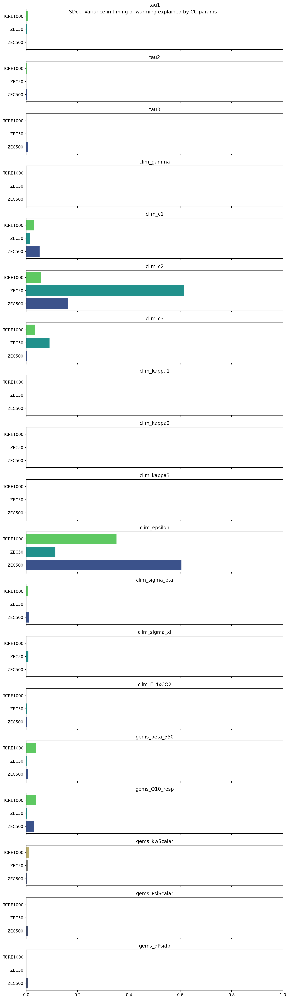

In [1956]:
fig, ax = plt.subplots(19, 1, 
                       figsize = (10,35),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(['tau1', 'tau2', 'tau3', 'clim_gamma',
       'clim_c1', 'clim_c2', 'clim_c3', 'clim_kappa1', 'clim_kappa2',
       'clim_kappa3', 'clim_epsilon', 'clim_sigma_eta', 'clim_sigma_xi',
       'clim_F_4xCO2', 'gems_beta_550', 'gems_Q10_resp', 'gems_kwScalar',
       'gems_PsiScalar', 'gems_dPsidb']):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SDck_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDck_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDck_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param)

plt.suptitle(rf'SDck: Variance in timing of warming explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SDck_co2T', dpi = 300)
plt.xlim(0,1)

plt.show();plt.close()

0.4529373680054912


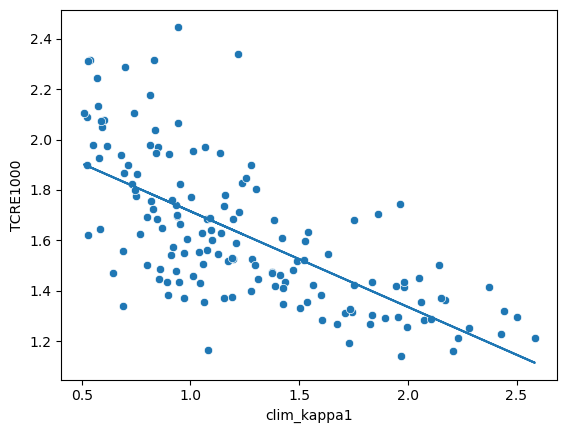

In [1792]:
# sns.scatterplot()
X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][['clim_kappa1']],df_SDckp.iloc[constrained_by_co2T_SDckp][["TCRE1000"]]

#fit regression model
model.fit(X, y)
sns.scatterplot(x = df_SDckp.iloc[constrained_by_co2T_SDckp]['clim_kappa1'], y = df_SDckp.iloc[constrained_by_co2T_SDckp]["TCRE1000"])
plt.plot(X, model.predict(X))
print(model.score(X, y))

In [1793]:
model.score?

Signature: model.score(X, y, sample_weight=None)
Docstring:
Return the coefficient of determination of the prediction.

The coefficient of determination :math:`R^2` is defined as
:math:`(1 - \frac{u}{v})`, where :math:`u` is the residual
sum of squares ``((y_true - y_pred)** 2).sum()`` and :math:`v`
is the total sum of squares ``((y_true - y_true.mean()) ** 2).sum()``.
The best possible score is 1.0 and it can be negative (because the
model can be arbitrarily worse). A constant model that always predicts
the expected value of `y`, disregarding the input features, would get
a :math:`R^2` score of 0.0.

Parameters
----------
X : array-like of shape (n_samples, n_features)
    Test samples. For some estimators this may be a precomputed
    kernel matrix or a list of generic objects instead with shape
    ``(n_samples, n_samples_fitted)``, where ``n_samples_fitted``
    is the number of samples used in the fitting for the estimator.

y : array-like of shape (n_samples,) or (n_samples, n_ou

In [286]:
df_SDckp_rsquared_co2T = pd.DataFrame(columns=['TCRE1000', 'ZEC50', 'ZEC100', 'ZEC500', 'ZEC1000', 'Fco2_20',
       'Fco2_50', 'Fco2_100', 'Fco2_500', 'Fco2_1000', 'TL0_20', 'TL0_50',
       'TL0_100', 'TL0_500', 'TL0_1000', 'tau1', 'tau2', 'tau3'
                                              ],
                             index = [
                                 'tau1', 'tau2', 'tau3', 
                                  'Fco2_20',
       'Fco2_50', 'Fco2_100', 'Fco2_500', 'Fco2_1000', 
                                 'clim_gamma',
       'clim_c1', 'clim_c2', 'clim_c3', 'clim_kappa1', 'clim_kappa2',
       'clim_kappa3', 'clim_epsilon', 'clim_sigma_eta', 'clim_sigma_xi',
       'clim_F_4xCO2', 'gems_beta_550', 'gems_Q10_resp', 'gems_kwScalar',
       'gems_PsiScalar', 'gems_dPsidb'])

for c in df_SDckp_rsquared_co2T.columns.to_list():
    for i in df_SDckp_rsquared_co2T.index.to_list():
        # remove this when the taus are finished and remove indent below:
        if i in ['tau1', 'tau2', 'tau3']:
            X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][[i]],df_SDckp.iloc[constrained_by_co2T_SDckp][[c]]
        elif c in ['tau1', 'tau2', 'tau3']:
            X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][[i]],df_SDckp.iloc[constrained_by_co2T_SDckp][[c]]
        else:
        # remove this when the taus are finished and remove indent below:
            X, y = df_SDckp.iloc[constrained_by_co2T_SDckp][[i]], df_SDckp.iloc[constrained_by_co2T_SDckp][[c]]
    
        #fit regression model
        model.fit(X, y)
        
        #calculate R-squared of regression model
        r_squared = model.score(X, y)
        
        # #view R-squared value
        # print(f'variance in {c} explained by variance in {i} = {r_squared}')

        #place r_squared in dataframe
        df_SDckp_rsquared_co2T.loc[i,c]  = r_squared
        
df_SDckp_rsquared_co2T

,TCRE1000,ZEC50,ZEC100,ZEC500,ZEC1000,Fco2_20,Fco2_50,Fco2_100,Fco2_500,Fco2_1000,TL0_20,TL0_50,TL0_100,TL0_500,TL0_1000,tau1,tau2,tau3
tau1,0.002968,0.016099,0.022354,0.007978,0.00403,0.038615,0.036863,0.033451,0.020667,0.010222,0.005476,0.009105,0.013743,0.00796,0.0051,1.0,0.518236,0.342458
tau2,0.000471,0.001115,0.00349,0.000041,0.000028,0.069189,0.069421,0.065707,0.052493,0.033778,0.000222,0.000008,0.000286,0.000037,0.000187,0.518236,1.0,0.325042
tau3,0.002808,0.017516,0.038414,0.05376,0.049454,0.00212,0.002552,0.002584,0.002264,0.000559,0.005544,0.009322,0.019923,0.035536,0.035382,0.342458,0.325042,1.0
Fco2_20,0.001164,0.003101,0.001701,0.005022,0.013264,1.0,0.998916,0.996215,0.95852,0.922919,0.000633,0.00001,0.000001,0.004402,0.010084,0.038615,0.069189,0.00212
Fco2_50,0.001897,0.001944,0.001007,0.005561,0.013714,0.998916,1.0,0.99834,0.96247,0.9262,0.001309,0.000237,0.000159,0.005409,0.011257,0.036863,0.069421,0.002552
Fco2_100,0.002944,0.000855,0.000233,0.008172,0.017236,0.996215,0.99834,1.0,0.975661,0.943017,0.002378,0.000895,0.000824,0.008076,0.014736,0.033451,0.065707,0.002584
Fco2_500,0.008586,0.000155,0.001455,0.026358,0.041046,0.95852,0.96247,0.975661,1.0,0.986401,0.008319,0.005959,0.006965,0.025302,0.036614,0.020667,0.052493,0.002264
Fco2_1000,0.01235,0.002061,0.007008,0.050757,0.072011,0.922919,0.9262,0.943017,0.986401,1.0,0.013048,0.011097,0.014511,0.045042,0.061616,0.010222,0.033778,0.000559
clim_gamma,0.001372,0.000025,0.000235,0.001831,0.000987,0.000162,0.000201,0.000265,0.000469,0.001191,0.001299,0.000953,0.000288,0.000143,0.000043,0.000684,0.001448,0.002415
clim_c1,0.000315,0.003097,0.001438,0.000002,0.00012,0.013821,0.013667,0.014174,0.014939,0.017166,0.00002,0.00009,0.000068,0.000092,0.0,0.004067,0.011086,0.015689


Text(0.0, 1.0, 'Coefficient of Determination, $R^2$')

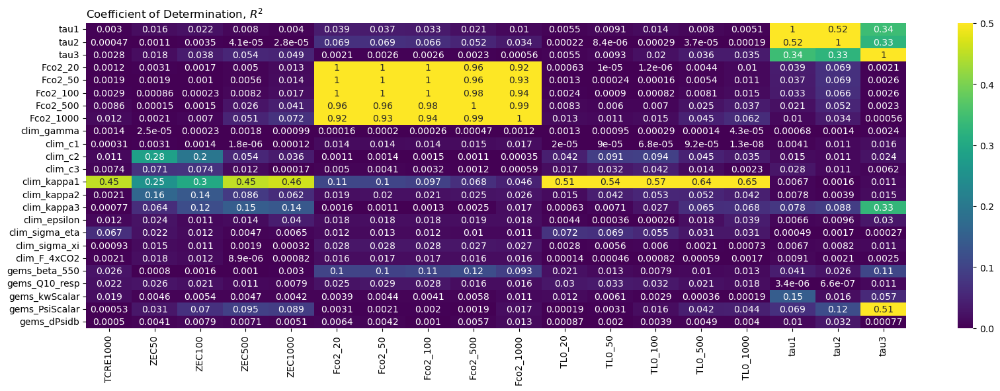

In [287]:
plt.figure(figsize=(20, 6))
sns.heatmap(df_SDckp_rsquared_co2T.astype(float), vmin=0, vmax=0.5, annot=True, cmap = 'viridis')
plt.title('Coefficient of Determination, $R^2$', loc = 'left')

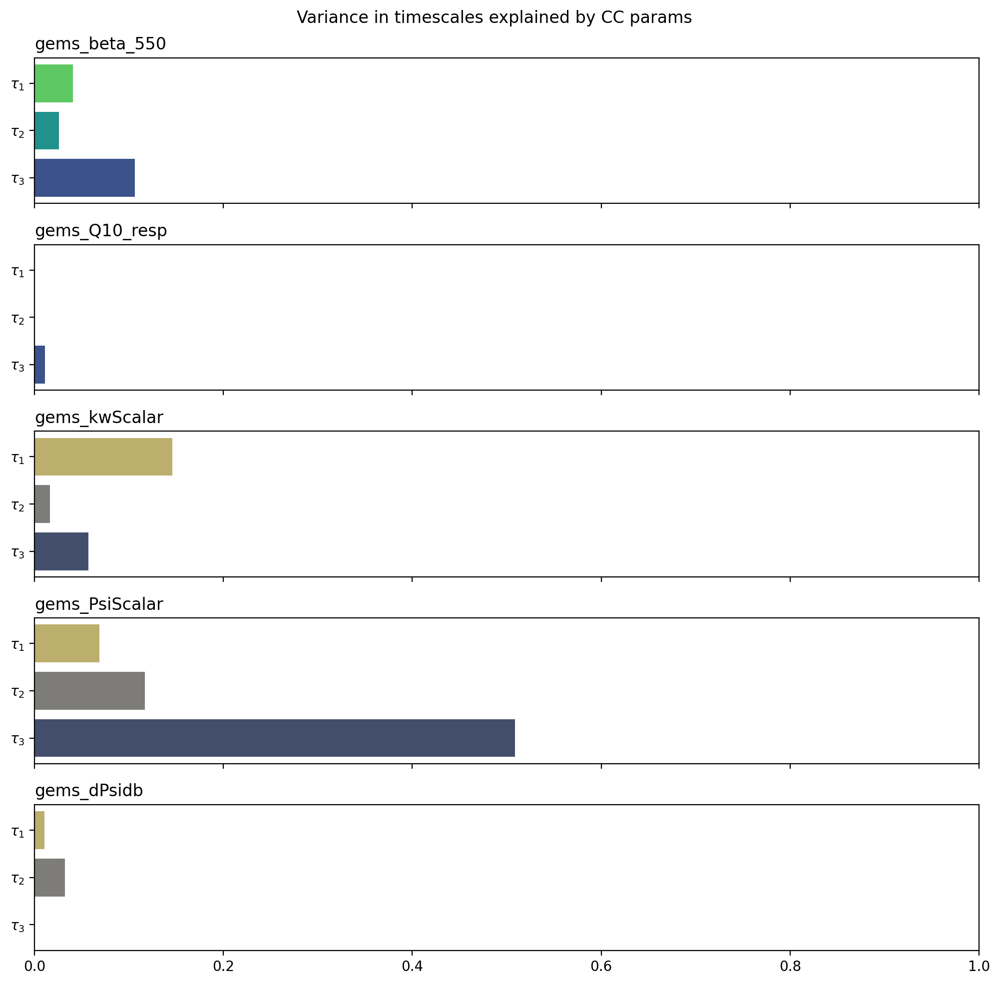

In [1932]:
fig, ax = plt.subplots(5, 1, figsize = (10,10), dpi = 200, sharex = True)
variable = 'ZEC500'

for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
    
                     ]),
            np.array([df_SDckp_rsquared_co2T.loc[param,'tau3'],
                      df_SDckp_rsquared_co2T.loc[param,'tau2'],
                      df_SDckp_rsquared_co2T.loc[param,'tau1'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Variance in timescales explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ccparams_SDckp_co2T', dpi = 300)
plt.xlim(0,1)
plt.show();plt.close()

In [2114]:
df_SDckp_rsquared_co2T

,TCRE1000,ZEC50,ZEC100,ZEC500,ZEC1000,Fco2_20,Fco2_50,Fco2_100,Fco2_500,Fco2_1000,TL0_20,TL0_50,TL0_100,TL0_500,TL0_1000,tau1,tau2,tau3
tau1,0.002968,0.016099,0.022354,0.007978,0.00403,0.038615,0.036863,0.033451,0.020667,0.010222,0.005476,0.009105,0.013743,0.00796,0.0051,1.0,0.518236,0.342458
tau2,0.000471,0.001115,0.00349,0.000041,0.000028,0.069189,0.069421,0.065707,0.052493,0.033778,0.000222,0.000008,0.000286,0.000037,0.000187,0.518236,1.0,0.325042
tau3,0.002808,0.017516,0.038414,0.05376,0.049454,0.00212,0.002552,0.002584,0.002264,0.000559,0.005544,0.009322,0.019923,0.035536,0.035382,0.342458,0.325042,1.0
Fco2_20,0.001164,0.003101,0.001701,0.005022,0.013264,1.0,0.998916,0.996215,0.95852,0.922919,0.000633,0.00001,0.000001,0.004402,0.010084,0.038615,0.069189,0.00212
Fco2_50,0.001897,0.001944,0.001007,0.005561,0.013714,0.998916,1.0,0.99834,0.96247,0.9262,0.001309,0.000237,0.000159,0.005409,0.011257,0.036863,0.069421,0.002552
Fco2_100,0.002944,0.000855,0.000233,0.008172,0.017236,0.996215,0.99834,1.0,0.975661,0.943017,0.002378,0.000895,0.000824,0.008076,0.014736,0.033451,0.065707,0.002584
Fco2_500,0.008586,0.000155,0.001455,0.026358,0.041046,0.95852,0.96247,0.975661,1.0,0.986401,0.008319,0.005959,0.006965,0.025302,0.036614,0.020667,0.052493,0.002264
Fco2_1000,0.01235,0.002061,0.007008,0.050757,0.072011,0.922919,0.9262,0.943017,0.986401,1.0,0.013048,0.011097,0.014511,0.045042,0.061616,0.010222,0.033778,0.000559
clim_gamma,0.001372,0.000025,0.000235,0.001831,0.000987,0.000162,0.000201,0.000265,0.000469,0.001191,0.001299,0.000953,0.000288,0.000143,0.000043,0.000684,0.001448,0.002415
clim_c1,0.000315,0.003097,0.001438,0.000002,0.00012,0.013821,0.013667,0.014174,0.014939,0.017166,0.00002,0.00009,0.000068,0.000092,0.0,0.004067,0.011086,0.015689


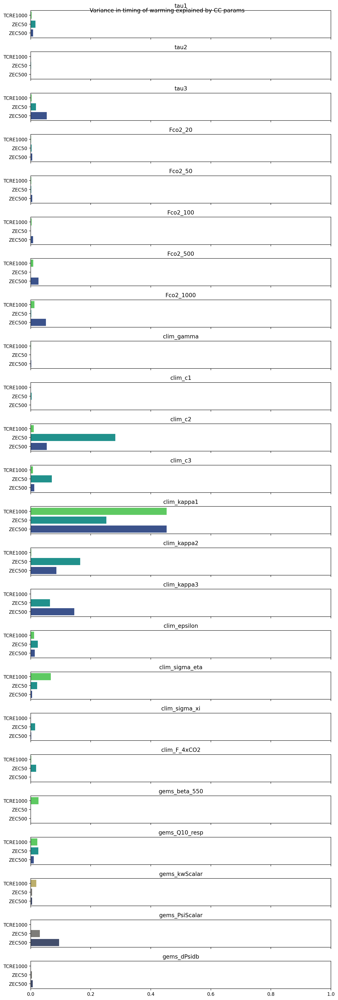

In [1933]:
fig, ax = plt.subplots(len(df_SDckp_rsquared_co2T.index.to_list()), 1, 
                       figsize = (10,30),
                       dpi = 200, sharex = True)
variable = 'F'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(df_SDckp_rsquared_co2T.index.to_list()):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SDckp_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDckp_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param)

plt.suptitle(rf'Variance in timing of warming explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SDckp_co2T', dpi = 300)
plt.xlim(0,1)

plt.show();plt.close()

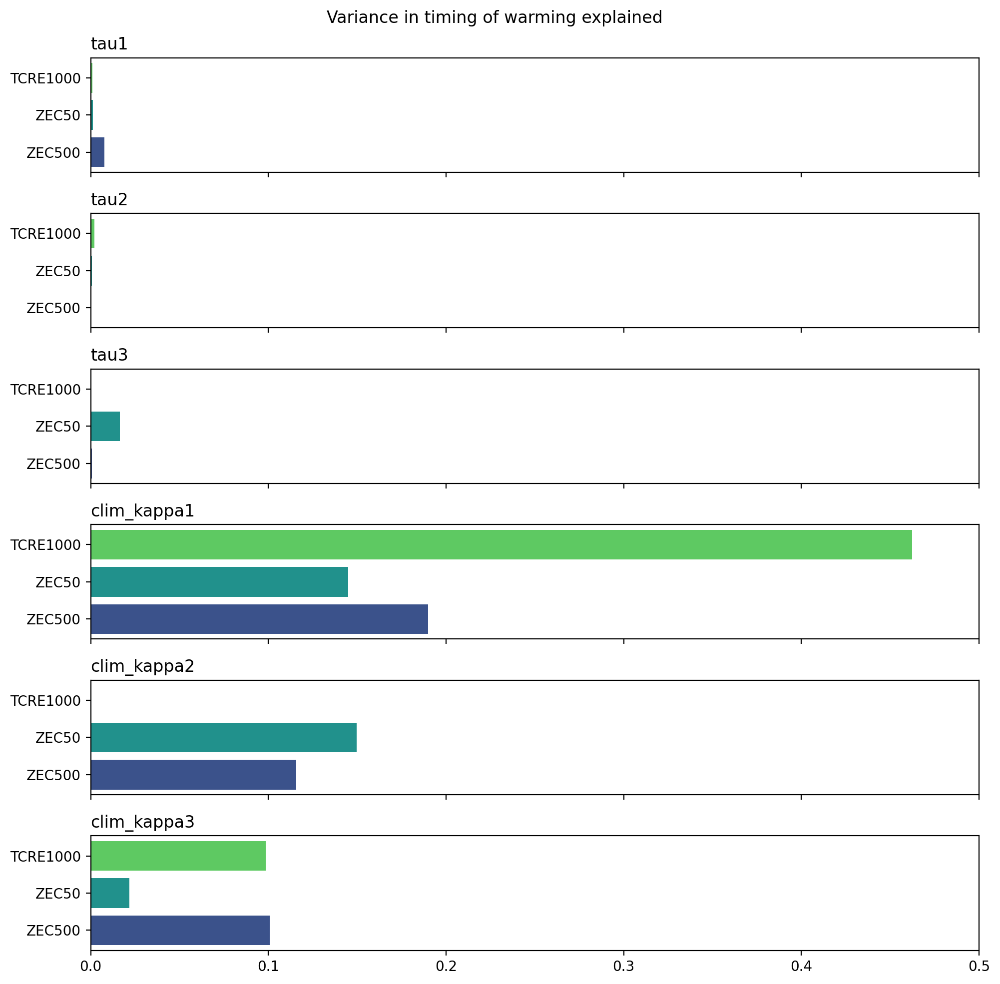

In [2148]:
fig, ax = plt.subplots(6, 1, 
                       figsize = (10,10),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(['tau1', 'tau2', 'tau3', 
                           'clim_kappa1', 'clim_kappa2', 'clim_kappa3'
                          ]):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SD_rsquared_co2T.loc[param,'ZEC500'],
                      df_SD_rsquared_co2T.loc[param,'ZEC50'],
                      df_SD_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

ax[0].set_title


plt.suptitle(rf'Variance in timing of warming explained')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SD_co2T', dpi = 300)
plt.xlim(0,0.5)

plt.show();plt.close()

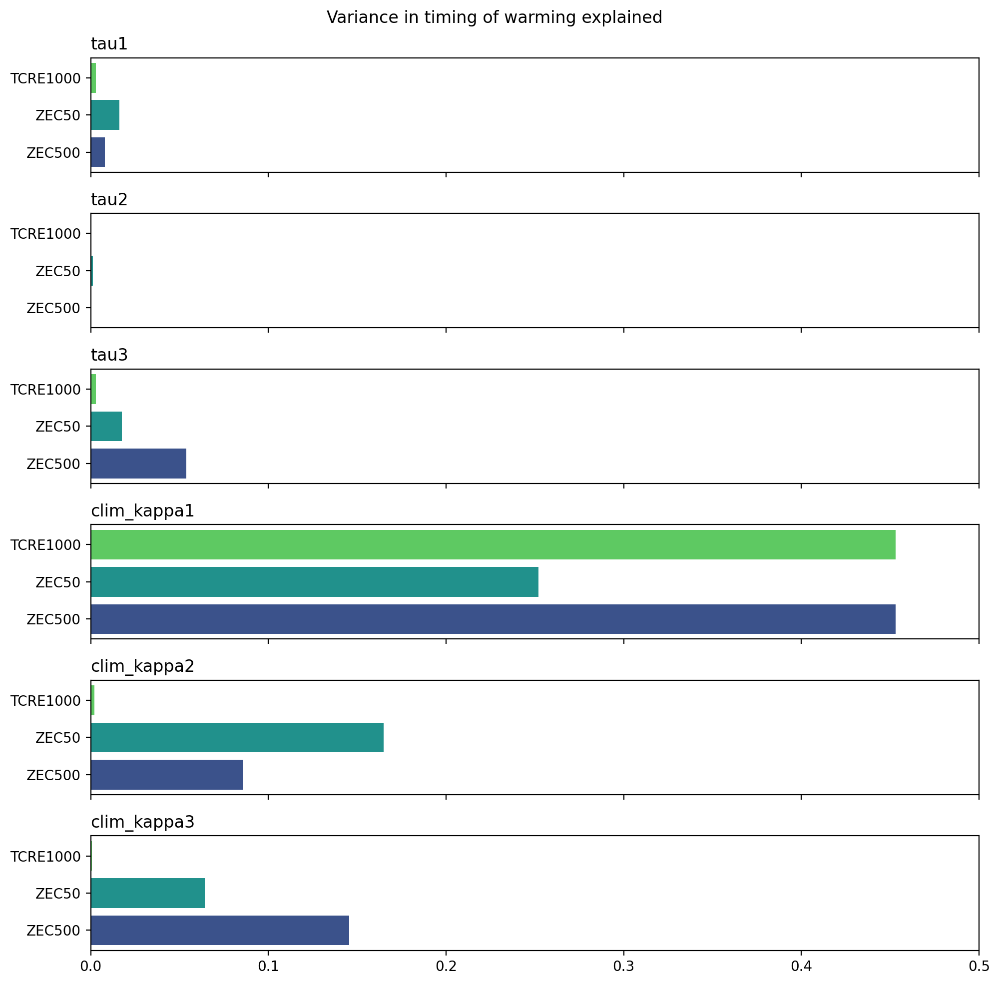

In [1939]:
fig, ax = plt.subplots(6, 1, 
                       figsize = (10,10),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(['tau1', 'tau2', 'tau3', 'clim_kappa1', 'clim_kappa2', 'clim_kappa3']):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SDckp_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDckp_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Variance in timing of warming explained')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SDckp_co2T', dpi = 300)
plt.xlim(0,0.5)

plt.show();plt.close()

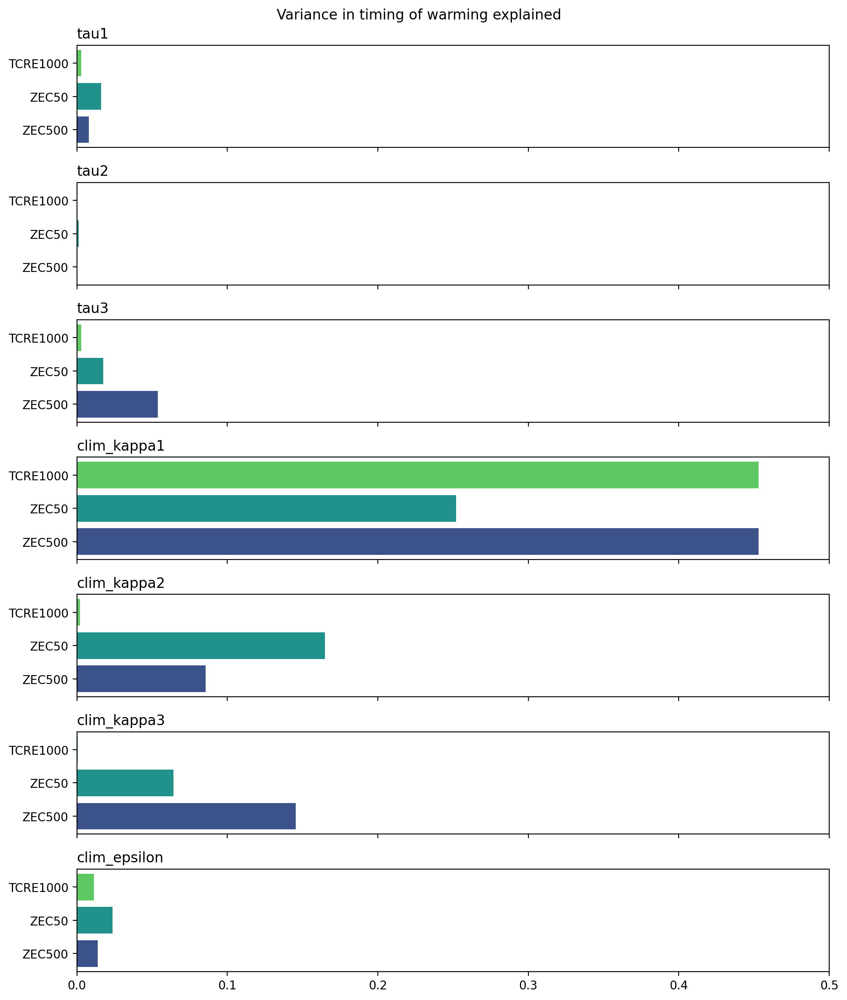

In [2113]:
fig, ax = plt.subplots(7, 1, 
                       figsize = (10,12),
                       dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(['tau1', 'tau2', 'tau3', 'clim_kappa1', 'clim_kappa2', 'clim_kappa3', 'clim_epsilon']):
    ax[i].barh(np.array([r'ZEC500',
                         r'ZEC50',
                         r'TCRE1000',
                     ]),
            np.array([df_SDckp_rsquared_co2T.loc[param,'ZEC500'],
                      df_SDckp_rsquared_co2T.loc[param,'ZEC50'],
                      df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_title(param, loc = 'left')

plt.suptitle(rf'Variance in timing of warming explained')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/warming_variance_explained_by_ccparams_SDckp_co2T', dpi = 300)
plt.xlim(0,0.5)

plt.show();plt.close()

Constant kappa ensemble:

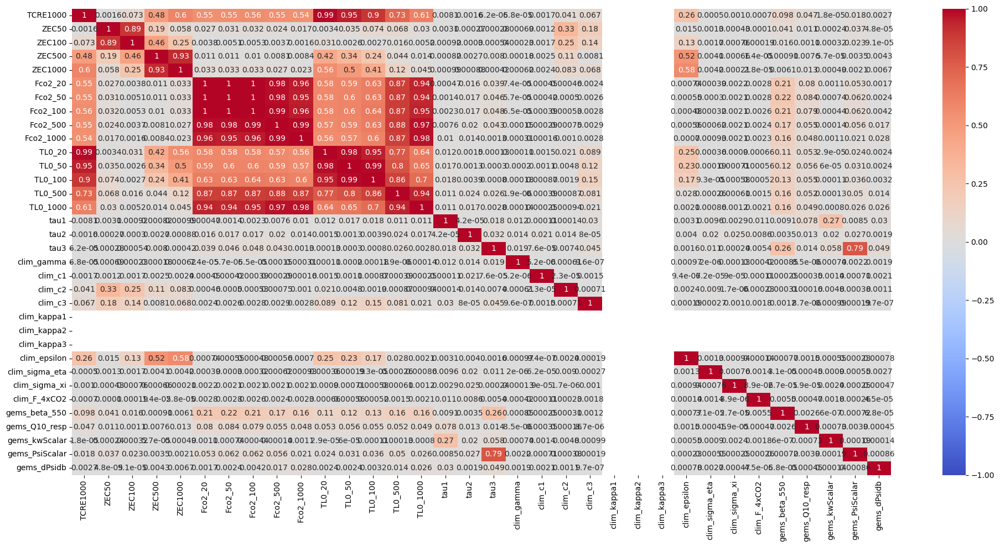

In [2059]:
features1=['TCRE1000','ZEC50','ZEC100','ZEC500','ZEC1000','Fco2_20','Fco2_50','Fco2_100','Fco2_500','Fco2_1000',
           'TL0_20','TL0_50','TL0_100','TL0_500','TL0_1000',
           'tau1','tau2','tau3',
           'clim_gamma','clim_c1','clim_c2','clim_c3',
           'clim_kappa1','clim_kappa2', 'clim_kappa3', 
           'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
           'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']

plt.figure(figsize=(20, 10))
data_ck = df_SDck[features1]
corr = data_ck.corr()**2

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'coolwarm')
plt.tight_layout()

In [2060]:
df_SDck_r2_pearson = data_ck.corr().copy()
df_SDck_pval_pearson = data_ck.corr().copy()

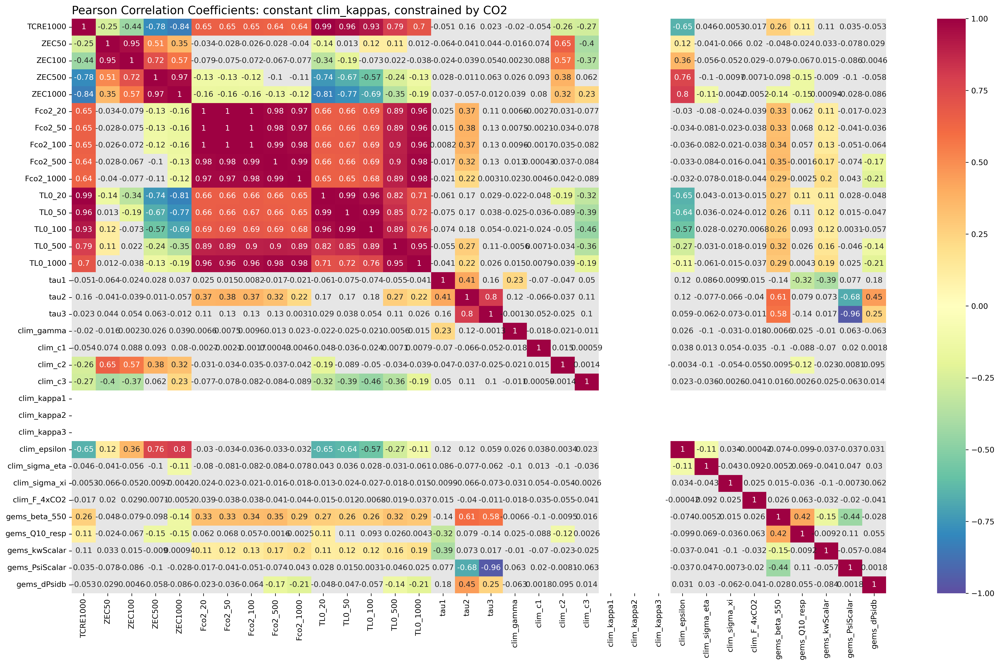

In [1448]:
# features1=['TCRE1000','ZEC50','ZEC100','ZEC500','ZEC1000',
           
#            'clim_gamma','clim_c1','clim_c2','clim_c3',
#            # 'clim_kappa1','clim_kappa2', 'clim_kappa3', 
#            'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
#           'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']

# plt.figure(figsize=(20, 12), dpi=300)
# corr = df_SDck_r2_pearson['TCRE1000':].where(df_SDck_pval_pearson['TCRE1000':]<0.05)
# corr_nonsig = df_SDck_r2_pearson['TCRE1000':].where(df_SDck_pval_pearson['TCRE1000':]>0.05)

# sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
# sns.heatmap(corr_nonsig, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
# plt.tight_layout()
# plt.title('Pearson Correlation Coefficients: constant clim_kappas, constrained by CO2', loc = 'left', fontsize = 15)
# plt.savefig('figures/PCC_constantkappas_co2.png', dpi = 300)
# plt.show();plt.close()

In [2062]:
for a in data_ck.columns.to_list():
    for b in data_ck.columns.to_list():
        # if b in ['tau1', 'tau2', 'tau3']:
        #     df_SDck_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck.iloc[top100_co2_SDck][a], y = df_SDck.iloc[top100_co2_SDck][b])[0]
        #     df_SDck_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck.iloc[top100_co2_SDck][a], y = df_SDck.iloc[top100_co2_SDck][b])[1]
        # elif a in ['tau1', 'tau2', 'tau3']:
        df_SDck_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck.iloc[constrained_by_co2T_SDck][a], y = df_SDck.iloc[constrained_by_co2T_SDck][b])[0]
        df_SDck_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck.iloc[constrained_by_co2T_SDck][a], y = df_SDck.iloc[constrained_by_co2T_SDck][b])[1]
        # else:
        #     df_SDck_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck[a], y = df_SDck[b])[0]
        #     df_SDck_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck[a], y = df_SDck[b])[1]
        # else:
        #     df_SDck_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck.iloc[constrained_by_co2_SDck][a], y = df_SDck.iloc[constrained_by_co2_SDck][b])[0]
        #     df_SDck_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDck.iloc[constrained_by_co2_SDck][a], y = df_SDck.iloc[constrained_by_co2_SDck][b])[1]

/home/disk/p/gshum/anaconda3/envs/simple_mip/lib/python3.12/site-packages/scipy/stats/_stats_py.py:4781: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(msg))


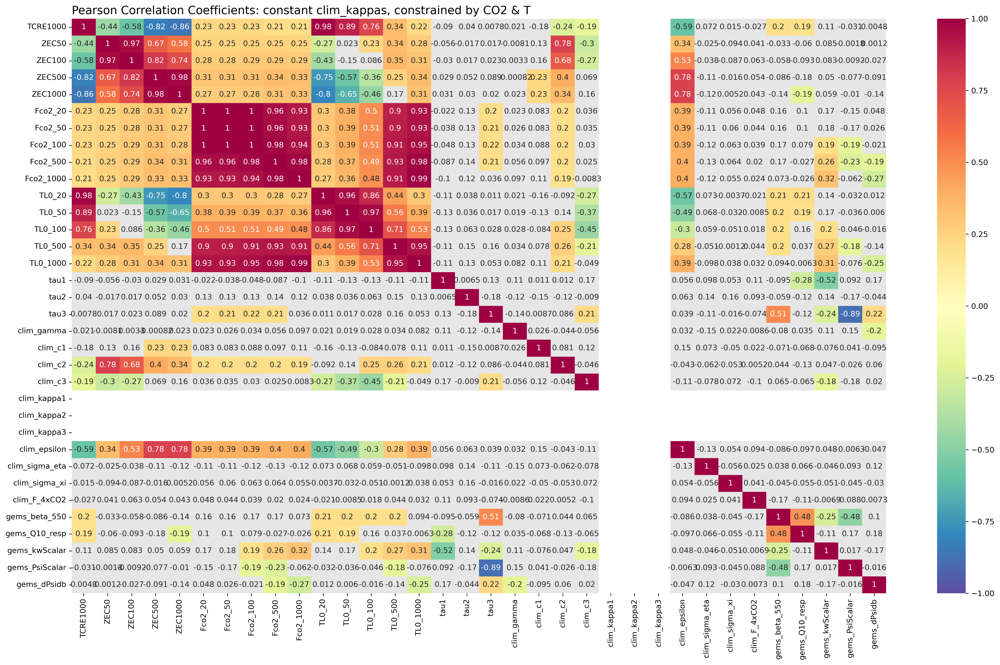

In [2063]:
features1=['TCRE1000','ZEC50','ZEC100','ZEC500','ZEC1000',
           
           'clim_gamma','clim_c1','clim_c2','clim_c3',
           # 'clim_kappa1','clim_kappa2', 'clim_kappa3', 
           'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
          'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']

plt.figure(figsize=(20, 12), dpi=300)
corr = df_SDck_r2_pearson['TCRE1000':].where(df_SDck_pval_pearson['TCRE1000':]<0.05)
corr_nonsig = df_SDck_r2_pearson['TCRE1000':].where(df_SDck_pval_pearson['TCRE1000':]>0.05)

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
sns.heatmap(corr_nonsig, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
plt.tight_layout()
plt.title('Pearson Correlation Coefficients: constant clim_kappas, constrained by CO2 & T', loc = 'left', fontsize = 15)
plt.savefig('figures/PCC_constantkappas_co2T.png', dpi = 300)
plt.show();plt.close()

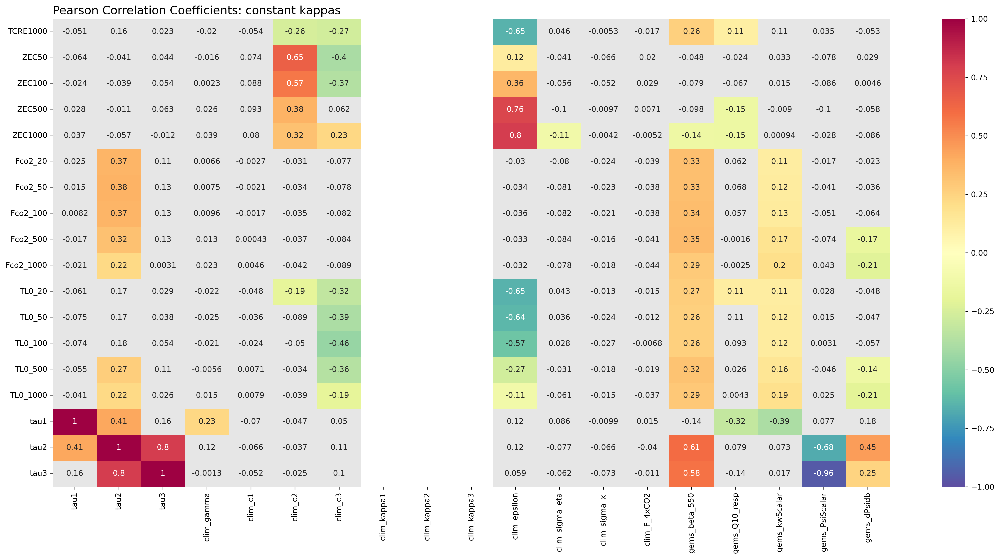

In [1453]:
plt.figure(figsize=(20, 10), dpi=300)
corr = df_SDck_r2_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb'].where(df_SDck_pval_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb']<0.05)
corr_non = df_SDck_r2_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb'].where(df_SDck_pval_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb']>0.05)

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
sns.heatmap(corr_non, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
plt.tight_layout()
plt.title('Pearson Correlation Coefficients: constant kappas', loc = 'left', fontsize = 15)
plt.savefig('figures/PCC_constantkappa_abridged.png', dpi = 300)
plt.show();plt.close()

In [152]:
# Now let's look at the corrlated kappa/psi ensemble:
df_SDckp = params_fairSDckp
df_SDckp['TCRE1000'] = tcre1000_SDckp
df_SDckp['ZEC20'] = ZEC20_SD_ckp.values
df_SDckp['ZEC50'] = ZEC50_SD_ckp.values
df_SDckp['ZEC100'] = ZEC100_SD_ckp.values
df_SDckp['ZEC500'] = ZEC500_SD_ckp.values
df_SDckp['ZEC1000'] = ZEC1000_SD_ckp.values

df_SDckp['Fco2_20'] = FCO2_20_SDckp.values
df_SDckp['Fco2_50'] = FCO2_50_SDckp.values
df_SDckp['Fco2_100'] = FCO2_100_SDckp.values
df_SDckp['Fco2_500'] = FCO2_500_SDckp.values
df_SDckp['Fco2_1000'] = FCO2_1000_SDckp.values

df_SDckp['TL0_20'] = TL0_20_SD_ckp.values; df_SDckp['TL1_20'] = TL1_20_SD_ckp.values; df_SDckp['TL2_20'] = TL2_20_SD_ckp.values
df_SDckp['TL0_50'] = TL0_50_SD_ckp.values; df_SDckp['TL1_50'] = TL1_50_SD_ckp.values; df_SDckp['TL2_50'] = TL2_50_SD_ckp.values
df_SDckp['TL0_100'] = TL0_100_SD_ckp.values; df_SDckp['TL1_100'] = TL1_100_SD_ckp.values; df_SDckp['TL2_100'] = TL2_100_SD_ckp.values
df_SDckp['TL0_500'] = TL0_500_SD_ckp.values; df_SDckp['TL1_500'] = TL1_500_SD_ckp.values; df_SDckp['TL2_500'] = TL2_500_SD_ckp.values
df_SDckp['TL0_1000'] = TL0_1000_SD_ckp.values; df_SDckp['TL1_1000'] = TL1_1000_SD_ckp.values; df_SDckp['TL2_1000'] = TL2_1000_SD_ckp.values

df_SDckp['tau1'] = np.nan; df_SDckp['tau1'][top100_co2_SDckp]=curvefit_params_3xp_SDckp100['tau1_total_decarb']
df_SDckp['tau2'] = np.nan; df_SDckp['tau2'][top100_co2_SDckp]=curvefit_params_3xp_SDckp100['tau2_total_decarb']
df_SDckp['tau3'] = np.nan; df_SDckp['tau3'][top100_co2_SDckp]=curvefit_params_3xp_SDckp100['tau3_total_decarb']

/tmp/ipykernel_83215/3008546181.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_SDckp['tau1'] = np.nan; df_SDckp['tau1'][top100_co2_SDckp]=curvefit_params_3xp_SDckp100['tau1_total_decarb']


ValueError: cannot set using a list-like indexer with a different length than the value

In [1462]:
FCO2_1000_SDckp

<xarray.DataArray 'co2_forcing' (config: 1000)>
array([1.6155401 , 1.63461066, 1.24664348, 1.73584613, 1.80244746,
       1.54051513, 1.34984672, 1.76772408, 1.54131175, 1.44310531,
       1.26045881, 1.4422337 , 1.64352231, 1.54473029, 1.4732382 ,
       1.15593508, 1.57798953, 1.52786091, 1.06271175, 1.63882121,
       1.64045179, 1.23736127, 1.37827877, 1.41045528, 1.64598262,
       1.53794298, 1.65659306, 1.99789366, 1.27109049, 1.23063337,
       1.26750738, 1.47348775, 1.45938639, 1.53959889, 1.78666898,
       1.01870632, 0.96348064, 1.58471505, 1.40630829, 1.88832067,
       1.27367831, 1.80700893, 1.77917146, 1.19370265, 1.60133149,
       1.57674313, 1.19555685, 1.23330583, 1.66039382, 1.05487316,
       1.34724798, 1.43719034, 1.30722926, 1.77945925, 0.95859588,
       1.60368965, 1.6772766 , 1.91725706, 1.19239841, 1.7270123 ,
       1.0570199 , 1.65378946, 1.71127368, 1.66329088, 1.05169638,
       1.0112782 , 1.24107578, 1.1348811 , 1.63042225, 1.63839675,
       1.19352848, 1.51662267, 1.37375427, 1.88649534, 1.26322757,
       1.94544131, 2.14048069, 0.94159724, 1.48607532, 1.20991898,
       1.57980844, 1.28837835, 1.70096233, 1.53194941, 1.54454243,
       1.26405072, 1.19396248, 1.31222925, 1.23954282, 2.16055222,
       1.63800566, 1.16195244, 2.01422084, 1.13150056, 1.76063128,
       1.02712506, 1.31216472, 1.7298563 , 1.16439804, 1.63613602,
...
       1.06480609, 1.04734059, 1.55064283, 1.25170529, 1.25568717,
       1.55189071, 1.66622791, 1.64264871, 1.9818079 , 1.66070995,
       1.66182258, 1.41543037, 1.25789468, 1.10500413, 1.74765647,
       1.69861618, 1.3706695 , 1.93477908, 1.54512217, 2.16318423,
       1.70972414, 1.3463459 , 1.63189385, 1.42095419, 1.86400684,
       1.67164741, 1.85992452, 1.88677875, 1.47324725, 1.55393215,
       1.30402592, 0.94733663, 1.83623995, 1.51883475, 1.15083289,
       1.19396118, 1.45846587, 1.36095488, 1.50083907, 1.35696465,
       1.3175982 , 1.31346926, 1.68177385, 1.7774013 , 1.0539837 ,
       1.35837227, 1.93768504, 1.23913822, 1.62708994, 1.68111008,
       1.13200838, 1.89212312, 1.36737149, 1.58438722, 1.24649724,
       1.60057963, 1.42324188, 1.66311864, 1.10006436, 1.69604237,
       1.09431368, 1.42059935, 1.89495931, 1.49956365, 1.06532787,
       1.90668126, 1.81737251, 1.91477573, 1.55691913, 1.70285297,
       1.68860381, 1.93309108, 1.30968887, 1.89909802, 1.58394873,
       1.58949423, 1.40770113, 1.38285016, 1.61408584, 1.0677181 ,
       1.3065431 , 2.4263539 , 1.78625901, 1.28018434, 1.83605465,
       2.01353307, 1.72443277, 1.94676764, 1.68082234, 1.70862263,
       1.34625627, 1.49014833, 1.26498109, 1.3749835 , 1.45362075,
       1.33294098, 1.66981147, 2.02554387, 1.12155459, 1.62419134])
Coordinates:
  * config    (config) int32 0 1 2 3 4 5 6 7 ... 992 993 994 995 996 997 998 999
    scenario  <U14 'esm-flat10_zec'

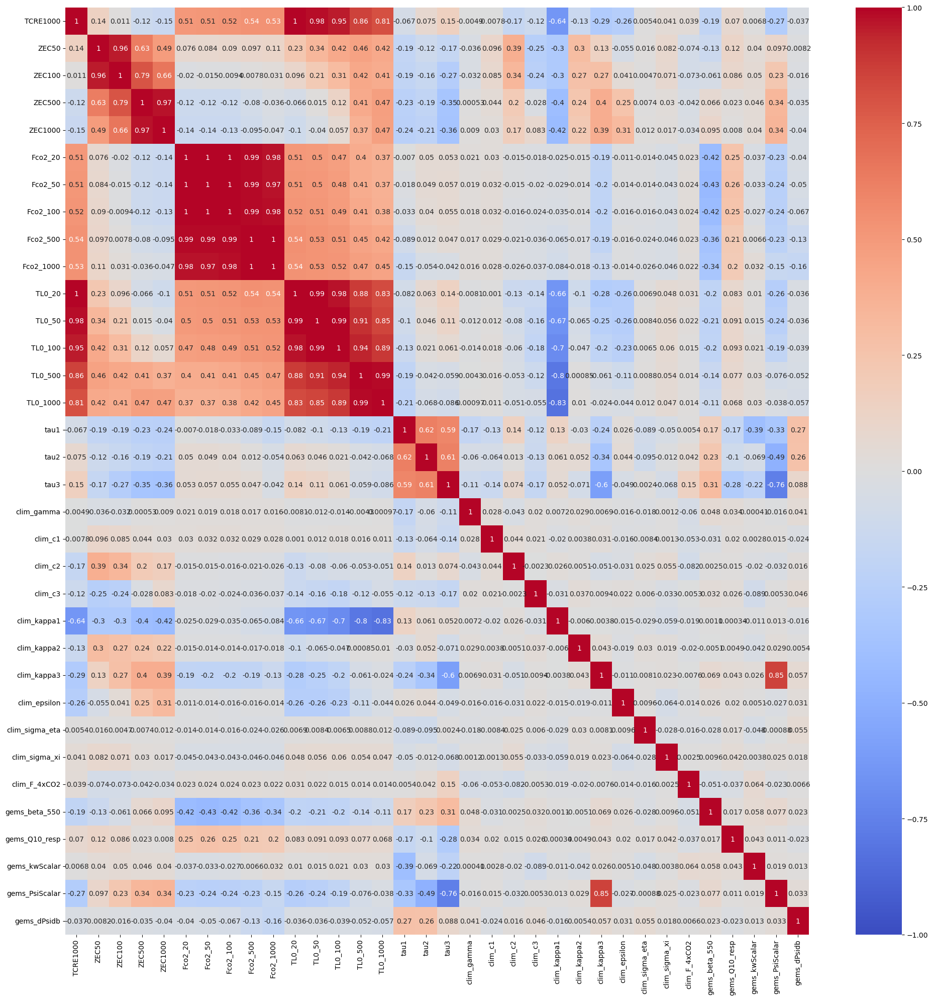

In [1510]:
features1=['TCRE1000','ZEC50','ZEC100','ZEC500','ZEC1000','Fco2_20','Fco2_50','Fco2_100','Fco2_500','Fco2_1000',
           'TL0_20','TL0_50','TL0_100','TL0_500','TL0_1000',
           # 'TL1_20','TL1_50','TL1_100','TL1_500','TL1_1000',
           # 'TL2_20','TL2_50','TL2_100','TL2_500','TL2_1000',
           'tau1','tau2','tau3',
           'clim_gamma','clim_c1','clim_c2','clim_c3',
           'clim_kappa1','clim_kappa2', 'clim_kappa3', 
           'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
           'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']

plt.figure(figsize=(20, 20))
data_ckp = df_SDckp[features1]
corr = data_ckp.corr()

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'coolwarm')
plt.tight_layout()

In [1511]:
df_SDckp.iloc[top100_co2_SDckp]

,Unnamed: 0,clim_gamma,clim_c1,clim_c2,clim_c3,clim_kappa1,clim_kappa2,clim_kappa3,clim_epsilon,clim_sigma_eta,...,TL2_100,TL0_500,TL1_500,TL2_500,TL0_1000,TL1_1000,TL2_1000,tau1,tau2,tau3
110,110,2.705403,5.851647,3.565449,225.783550,1.604760,3.336980,0.552151,0.992587,0.917901,...,0.323317,0.900483,0.867241,0.664843,0.880127,0.870048,0.808719,2.920963,34.122289,327.480815
830,830,5.833965,2.365009,43.765593,28.968832,1.301651,5.620695,0.130405,0.586060,2.630689,...,0.828875,1.461139,1.463255,1.415013,1.337806,1.339620,1.377514,3.040267,45.234454,1014.917580
915,915,7.180752,6.042249,59.906963,263.593513,2.093294,3.941474,1.491785,1.437285,2.178733,...,0.346406,0.799207,0.757955,0.686645,0.799352,0.792913,0.781556,3.219977,37.051386,420.073020
375,375,5.170712,4.273403,46.430423,171.398273,0.691347,3.019095,1.839015,0.633542,1.051211,...,1.021657,1.947793,1.917238,1.852580,1.962812,1.963228,1.963192,2.901464,32.467195,205.557463
809,809,2.189748,2.473933,41.148245,15.169517,2.355759,6.489905,2.694971,1.276680,1.230386,...,0.791235,0.586483,0.588252,0.589337,0.542859,0.543184,0.543382,3.189401,36.672923,317.700756
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0,20.663682,6.846014,5.412922,268.340258,1.239437,2.876407,1.645962,0.306327,2.265838,...,0.905124,1.374031,1.369686,1.343350,1.309749,1.312299,1.326066,2.980012,32.281104,261.142598
539,539,0.892210,4.290162,63.773531,116.758898,1.921322,8.623386,1.982325,2.076306,1.062718,...,0.636837,0.938999,0.936786,0.932240,0.907831,0.909873,0.913314,2.511353,33.990166,214.867656
659,659,10.191880,5.765981,48.968341,167.625289,2.370175,2.532550,0.697187,1.743809,0.725287,...,0.275055,0.671920,0.633361,0.555031,0.640100,0.636154,0.627232,3.274246,46.744788,563.825430
986,986,15.209704,7.734149,4.841934,185.677998,1.981095,2.726696,2.366547,0.112288,0.233588,...,1.027823,0.926522,0.929136,0.951815,0.871383,0.871940,0.876811,2.975738,32.204556,260.464424


In [1512]:
df_SDckp_r2_pearson = data_ckp.corr().copy()
df_SDckp_pval_pearson = data_ckp.corr().copy()

In [1513]:
for a in data_ckp.columns.to_list():
    for b in data_ckp.columns.to_list():
        if b in ['tau1', 'tau2', 'tau3']:
            df_SDckp_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[top100_co2_SDckp][a], y = df_SDckp.iloc[top100_co2_SDckp][b])[0]
            df_SDckp_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[top100_co2_SDckp][a], y = df_SDckp.iloc[top100_co2_SDckp][b])[1]
        elif a in ['tau1', 'tau2', 'tau3']:
            df_SDckp_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[top100_co2_SDckp][a], y = df_SDckp.iloc[top100_co2_SDckp][b])[0]
            df_SDckp_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[top100_co2_SDckp][a], y = df_SDckp.iloc[top100_co2_SDckp][b])[1]
        # else:
        #     df_SDckp_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp[a], y = df_SDckp[b])[0]
        #     df_SDckp_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp[a], y = df_SDckp[b])[1]
        # else:
        #     df_SDckp_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[constrained_by_co2_SDckp][a], y = df_SDckp.iloc[constrained_by_co2_SDckp][b])[0]
        #     df_SDckp_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[constrained_by_co2_SDckp][a], y = df_SDckp.iloc[constrained_by_co2_SDckp][b])[1]
        else:
            df_SDckp_r2_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[constrained_by_co2T_SDckp][a], y = df_SDckp.iloc[constrained_by_co2T_SDckp][b])[0]
            df_SDckp_pval_pearson.loc[b,a] = scipy.stats.pearsonr(x = df_SDckp.iloc[constrained_by_co2T_SDckp][a], y = df_SDckp.iloc[constrained_by_co2T_SDckp][b])[1]

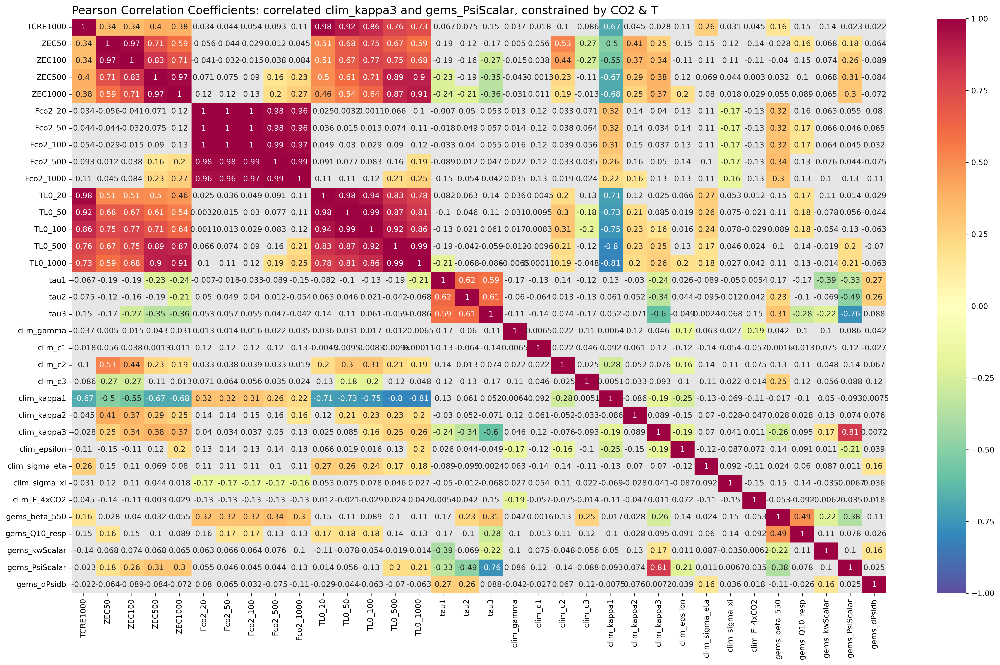

In [1514]:
features1=['TCRE1000','ZEC50','ZEC100','ZEC500','ZEC1000',
           
           'clim_gamma','clim_c1','clim_c2','clim_c3',
           'clim_kappa1','clim_kappa2', 'clim_kappa3', 
           'clim_epsilon','clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
          'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']

plt.figure(figsize=(20, 12), dpi=300)
corr = df_SDckp_r2_pearson['TCRE1000':].where(df_SDckp_pval_pearson['TCRE1000':]<0.05)
corr_nonsig = df_SDckp_r2_pearson['TCRE1000':].where(df_SDckp_pval_pearson['TCRE1000':]>0.05)

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
sns.heatmap(corr_nonsig, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
plt.tight_layout()
plt.title('Pearson Correlation Coefficients: correlated clim_kappa3 and gems_PsiScalar, constrained by CO2 & T', loc = 'left', fontsize = 15)
plt.savefig('figures/PCC_correlatedkappapsi_co2T.png', dpi = 300)
plt.show();plt.close()

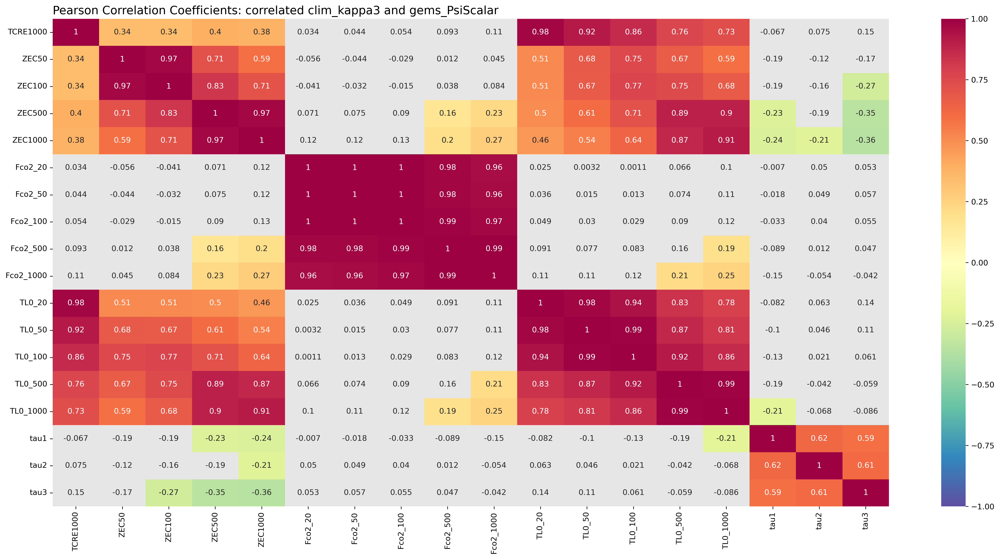

In [1505]:
features1=['TCRE1000','ZEC50','ZEC100','ZEC500','ZEC1000','Fco2_20','Fco2_50','Fco2_100','Fco2_500','Fco2_1000',
            'TL0_20','TL0_50','TL0_100','TL0_500','TL0_1000',
           # 'TL1_20','TL1_50','TL1_100','TL1_500','TL1_1000',
           # 'TL2_20','TL2_50','TL2_100','TL2_500','TL2_1000',
           'clim_gamma','clim_c1','clim_c2','clim_c3','clim_kappa1','clim_kappa2', 'clim_kappa3', 'clim_epsilon', 'clim_sigma_eta','clim_sigma_xi','clim_F_4xCO2',
          'gems_beta_550', 'gems_Q10_resp','gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']
# features2=['Cat1', 'Cat2','num1','num2']

plt.figure(figsize=(20, 10), dpi=300)
corr = df_SDckp_r2_pearson.loc['TCRE1000':'tau3','TCRE1000':'tau3'].where(df_SDckp_pval_pearson.loc['TCRE1000':'tau3','TCRE1000':'tau3']<0.05)
corr_non = df_SDckp_r2_pearson.loc['TCRE1000':'tau3','TCRE1000':'tau3'].where(df_SDckp_pval_pearson.loc['TCRE1000':'tau3','TCRE1000':'tau3']>0.05)

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
sns.heatmap(corr_non, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
plt.tight_layout()
plt.title('Pearson Correlation Coefficients: correlated clim_kappa3 and gems_PsiScalar', loc = 'left', fontsize = 15)
plt.savefig('figures/PCC_correlatedkappapsi.png', dpi = 300)
plt.show();plt.close()

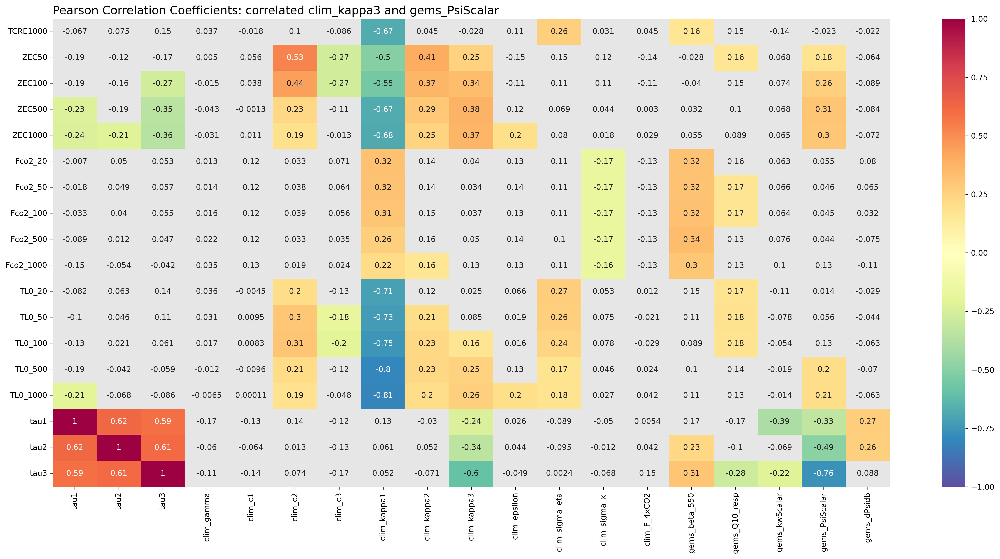

In [1506]:
plt.figure(figsize=(20, 10), dpi=300)
corr = df_SDckp_r2_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb'].where(df_SDckp_pval_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb']<0.05)
corr_non = df_SDckp_r2_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb'].where(df_SDckp_pval_pearson.loc['TCRE1000':'tau3','tau1':'gems_dPsidb']>0.05)

sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap = 'Spectral_r')
sns.heatmap(corr_non, vmin=0, vmax=1, annot=True, cmap=grey_colormap, cbar =None)
plt.tight_layout()
plt.title('Pearson Correlation Coefficients: correlated clim_kappa3 and gems_PsiScalar', loc = 'left', fontsize = 15)
plt.savefig('figures/PCC_correlatedkappapsi.png', dpi = 300)
plt.show();plt.close()

In [ ]:
fig, ax = plt.subplots(5, 1, figsize = (10,10), dpi = 200, sharex = True)
variable = 'ZEC500'

models = (
    "FaIR_default",
    "FaIR_SD",
    "HECTOR",
)
for i, param in enumerate(['gems_beta_550','gems_Q10_resp','gems_kwScalar','gems_PsiScalar','gems_dPsidb']):
    ax[i].barh(np.array([r'$\tau_3$',
                         r'$\tau_2$',
                         r'$\tau_1$',
    
                     ]),
            np.array([r2(x = test_SD[param][nonoutlier_i], y = test_SD['3xp_tau3'][nonoutlier_i]),
                      r2(x = test_SD[param][nonoutlier_i], y = test_SD['3xp_tau2'][nonoutlier_i]),
                      r2(x = test_SD[param][nonoutlier_i], y = test_SD['3xp_tau1'][nonoutlier_i]),
                     ]),
           color = sns.color_palette('cividis',3) if param in ['gems_kwScalar','gems_PsiScalar','gems_dPsidb'] else sns.color_palette('viridis',3))
    ax[i].set_xlabel(param)

plt.suptitle(rf'Variance in timescales explained by CC params')
# ax[4].set_xlabel('variance explained')
plt.tight_layout()
plt.savefig('figures/timescale_variance_explained_by_ccparams', dpi = 300)

plt.show();plt.close()

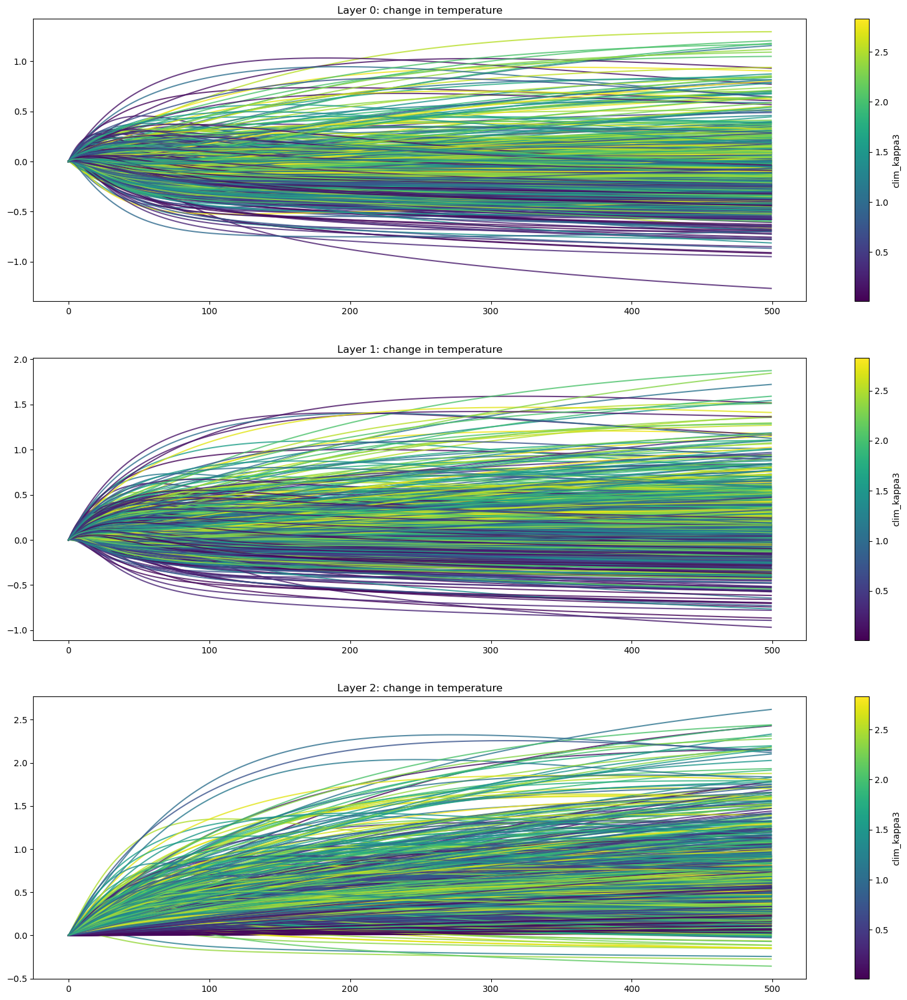

In [1958]:
df_SDckp_rsquared_co2T.index.to_list()

['tau1',
 'tau2',
 'tau3',
 'Fco2_20',
 'Fco2_50',
 'Fco2_100',
 'Fco2_500',
 'Fco2_1000',
 'clim_gamma',
 'clim_c1',
 'clim_c2',
 'clim_c3',
 'clim_kappa1',
 'clim_kappa2',
 'clim_kappa3',
 'clim_epsilon',
 'clim_sigma_eta',
 'clim_sigma_xi',
 'clim_F_4xCO2',
 'gems_beta_550',
 'gems_Q10_resp',
 'gems_kwScalar',
 'gems_PsiScalar',
 'gems_dPsidb']

In [1961]:
np.array([[df_SDck_rsquared_co2T.loc[param,'ZEC500'],df_SDckp_rsquared_co2T.loc[param,'ZEC500'],],
          [df_SDck_rsquared_co2T.loc[param,'ZEC50'],df_SDckp_rsquared_co2T.loc[param,'ZEC50'],],
          [df_SDck_rsquared_co2T.loc[param,'TCRE1000'],df_SDckp_rsquared_co2T.loc[param,'TCRE1000'],]
          ])

array([0.05375955, 0.01751574, 0.00280797])

In [2664]:
df_fair_rsquared_co2T

,TCRE1000,ZEC50,ZEC100,ZEC500,ZEC1000,Fco2_20,Fco2_50,Fco2_100,Fco2_500,Fco2_1000,TL0_20,TL0_50,TL0_100,TL0_500,TL0_1000,tau1,tau2,tau3
tau1,0.055355,0.030943,0.03416,0.010807,0.002673,0.061308,0.072726,0.096017,0.10333,0.021458,0.060739,0.0627,0.06697,0.05303,0.019252,1.0,0.160744,0.036941
tau2,0.000162,0.000582,0.000181,0.000055,0.001878,0.095451,0.085221,0.07772,0.15558,0.128729,0.000299,0.000308,0.000234,0.000181,0.00031,0.160744,1.0,0.07608
tau3,0.001856,0.011855,0.013013,0.004751,0.000001,0.080555,0.090976,0.102794,0.126826,0.084223,0.000611,0.00005,0.000095,0.000056,0.00101,0.036941,0.07608,1.0
clim_gamma,0.012419,0.004291,0.002313,0.000182,0.000164,0.002941,0.002631,0.001888,0.000503,0.001655,0.013025,0.01293,0.011522,0.007903,0.007886,0.008789,0.000213,0.025386
clim_c1,0.042595,0.007534,0.006421,0.000009,0.000926,0.000751,0.001071,0.001186,0.000236,0.000046,0.042584,0.040445,0.038156,0.023167,0.017147,0.009082,0.019693,0.001823
clim_c2,0.001151,0.148493,0.107814,0.033076,0.019787,0.016889,0.019685,0.023672,0.025291,0.017646,0.000363,0.005884,0.009962,0.006069,0.003898,0.001845,0.000008,0.006297
clim_c3,0.000869,0.105082,0.125804,0.050322,0.009337,0.000022,0.000067,0.000178,0.000214,0.000167,0.00019,0.00406,0.012888,0.011048,0.001475,0.00034,0.010518,0.000225
clim_kappa1,0.470861,0.156535,0.172653,0.313071,0.377106,0.050025,0.048077,0.046184,0.054009,0.058349,0.480689,0.487286,0.499909,0.666342,0.770895,0.001099,0.023348,0.020326
clim_kappa2,0.044088,0.093243,0.089081,0.124668,0.110715,0.016088,0.014088,0.011491,0.025241,0.036913,0.025129,0.009309,0.002699,0.002127,0.002866,0.003924,0.055808,0.031361
clim_kappa3,0.016947,0.035884,0.085644,0.206568,0.160884,0.005781,0.006223,0.007056,0.006318,0.00689,0.010159,0.003575,0.000087,0.026101,0.023638,0.0,0.000096,0.017211


In [2667]:
['tab:orange','tab:green', 'tab:yellow', 'firebrick']

['orange',
 [(0.229739, 0.322361, 0.545706),
  (0.127568, 0.566949, 0.550556),
  (0.369214, 0.788888, 0.382914)]]

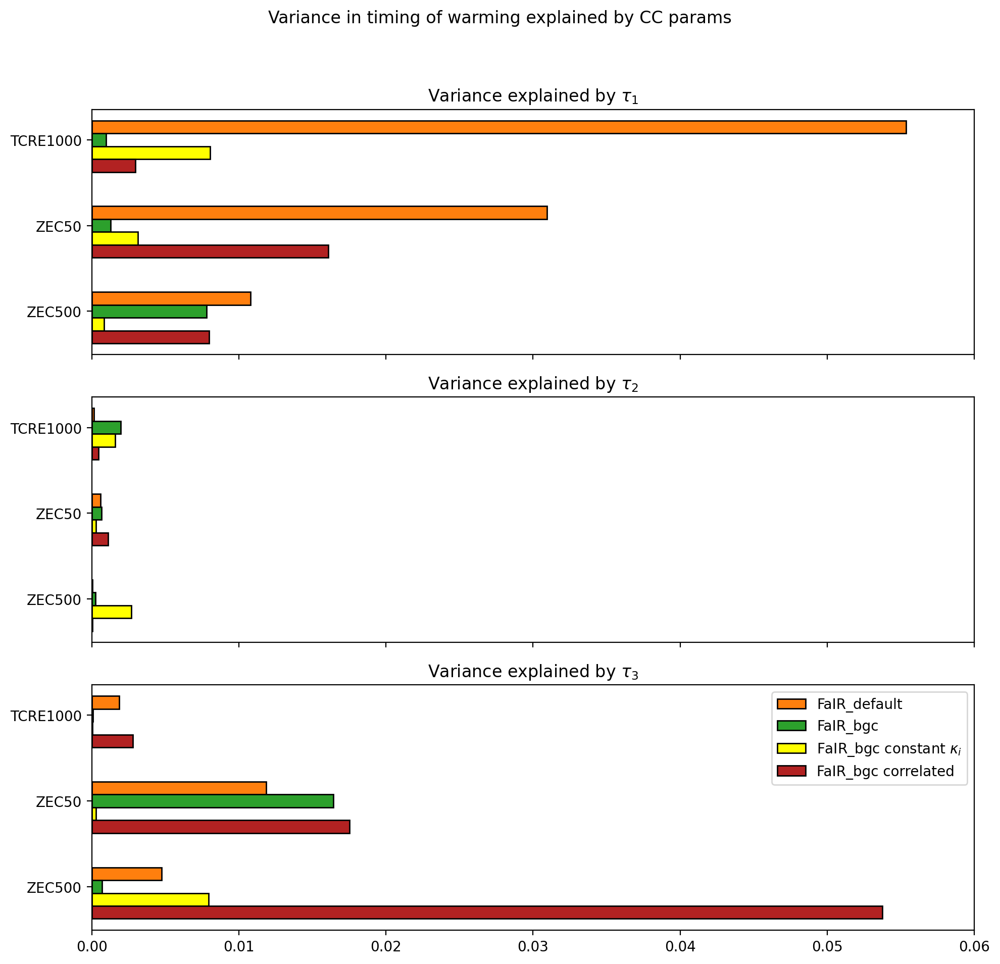

In [2677]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

params_to_plot = ['tau1', 'tau2', 'tau3']
experiments = ['FaIR_default', 
               'FaIR_bgc', 
               r'FaIR_bgc constant $\kappa_i$',
               'FaIR_bgc correlated']
# experiments = ['FaIR_bgc',]
# experiments = ['FaIR_bgc', 'FaIR_bgc, no kappas', 'FaIR_bgc, correlated']

dataframes = [df_fair_rsquared_co2T,
              df_SD_rsquared_co2T,
              df_SDck_rsquared_co2T, 
              df_SDckp_rsquared_co2T]

fig, ax = plt.subplots(len(params_to_plot), 1, 
                       figsize=(10, 10), dpi=200, sharex=True)

# Define the order of bars within each group
bar_order = ['TCRE1000', 'ZEC50', 'ZEC500',]

bar_width = 0.15  # Width of each bar
bar_positions = np.arange(len(bar_order))  # Positions for each group of bars

for i, param in enumerate(params_to_plot):
    for j, exp in enumerate(experiments):
        df = dataframes[j]
        
        # Define the labels for bars and their corresponding data
        bar_data = [df.loc[param, f'{group}'] for group in bar_order]
        # Adjust position for each set of bars
        positions = bar_positions + j * bar_width
        # Plot the bars with the defined labels and data
        bars = ax[i].barh(positions, bar_data, height=bar_width,
                          color=['tab:orange','tab:green', 'yellow', 'firebrick'][j],
                          label=exp, alpha = 1,
                          edgecolor='black')  # Add black outline to each bar

        # # Add labels at the end of each bar
        # for pos, val in zip(positions, bar_data):
        #     ax[i].text(val, pos, f' {exp}', va='center', ha='left', fontsize=8)

    # Set y-ticks to the middle of each group of bars
    ax[i].set_yticks(bar_positions + bar_width)
    ax[i].set_yticklabels(bar_order)
    ax[i].invert_yaxis()  # Reverse y-axis for each subplot
    
    # # Add title for each subplot
    # ax[i].set_title(f'{param}', loc = 'left')
# Add title for each subplot
ax[0].set_title(r'Variance explained by $\tau_1$', loc = 'center')
ax[1].set_title(r'Variance explained by $\tau_2$', loc = 'center')
ax[2].set_title(r'Variance explained by $\tau_3$', loc = 'center')

# Add legend
ax[-1].legend()
plt.xlim(0, .06)
plt.suptitle(rf'Variance in timing of warming explained by CC params')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust the layout to accommodate suptitle
plt.savefig('figures/warming_variance_explained_by_taus_SDall_co2T', dpi=300)

plt.show()
plt.close()


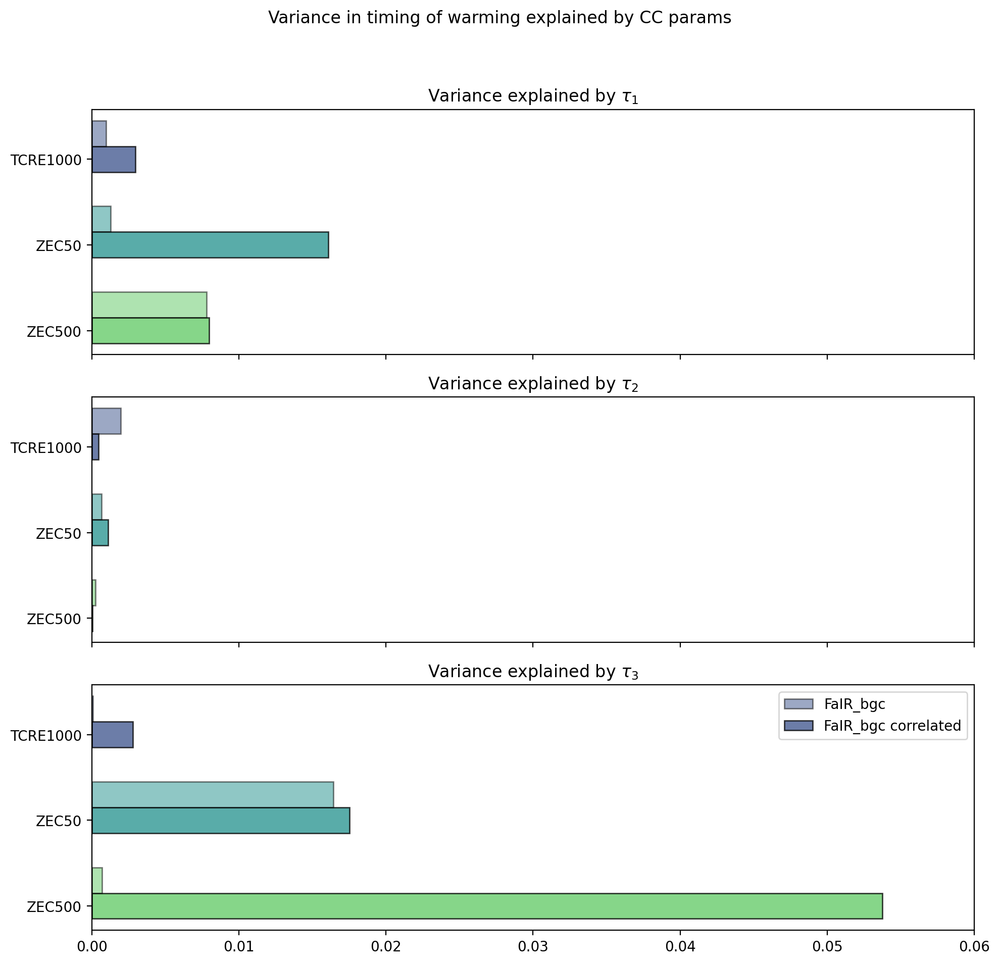

In [2137]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

params_to_plot = ['tau1', 'tau2', 'tau3']
experiments = ['FaIR_bgc', 
               # 'ck',
               'FaIR_bgc correlated']
# experiments = ['FaIR_bgc',]
# experiments = ['FaIR_bgc', 'FaIR_bgc, no kappas', 'FaIR_bgc, correlated']

dataframes = [df_SD_rsquared_co2T,
              # df_SDck_rsquared_co2T, 
              df_SDckp_rsquared_co2T]

fig, ax = plt.subplots(len(params_to_plot), 1, 
                       figsize=(10, 10), dpi=200, sharex=True)

# Define the order of bars within each group
bar_order = ['TCRE1000', 'ZEC50', 'ZEC500',]

bar_width = 0.3  # Width of each bar
bar_positions = np.arange(len(bar_order))  # Positions for each group of bars

for i, param in enumerate(params_to_plot):
    for j, exp in enumerate(experiments):
        df = dataframes[j]
        
        # Define the labels for bars and their corresponding data
        bar_data = [df.loc[param, f'{group}'] for group in bar_order]
        # Adjust position for each set of bars
        positions = bar_positions + j * bar_width
        # Plot the bars with the defined labels and data
        bars = ax[i].barh(positions, bar_data, height=bar_width,
                          color=sns.color_palette('viridis', 3),
                          label=exp, alpha=[.5, 0.75, 1][j],
                          edgecolor='black')  # Add black outline to each bar

        # # Add labels at the end of each bar
        # for pos, val in zip(positions, bar_data):
        #     ax[i].text(val, pos, f' {exp}', va='center', ha='left', fontsize=8)

    # Set y-ticks to the middle of each group of bars
    ax[i].set_yticks(bar_positions + bar_width)
    ax[i].set_yticklabels(bar_order)
    ax[i].invert_yaxis()  # Reverse y-axis for each subplot
    
    # # Add title for each subplot
    # ax[i].set_title(f'{param}', loc = 'left')
# Add title for each subplot
ax[0].set_title(r'Variance explained by $\tau_1$', loc = 'center')
ax[1].set_title(r'Variance explained by $\tau_2$', loc = 'center')
ax[2].set_title(r'Variance explained by $\tau_3$', loc = 'center')

# Add legend
ax[-1].legend()
plt.xlim(0, .06)
plt.suptitle(rf'Variance in timing of warming explained by CC params')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust the layout to accommodate suptitle
plt.savefig('figures/warming_variance_explained_by_taus_SDall_co2T', dpi=300)

plt.show()
plt.close()


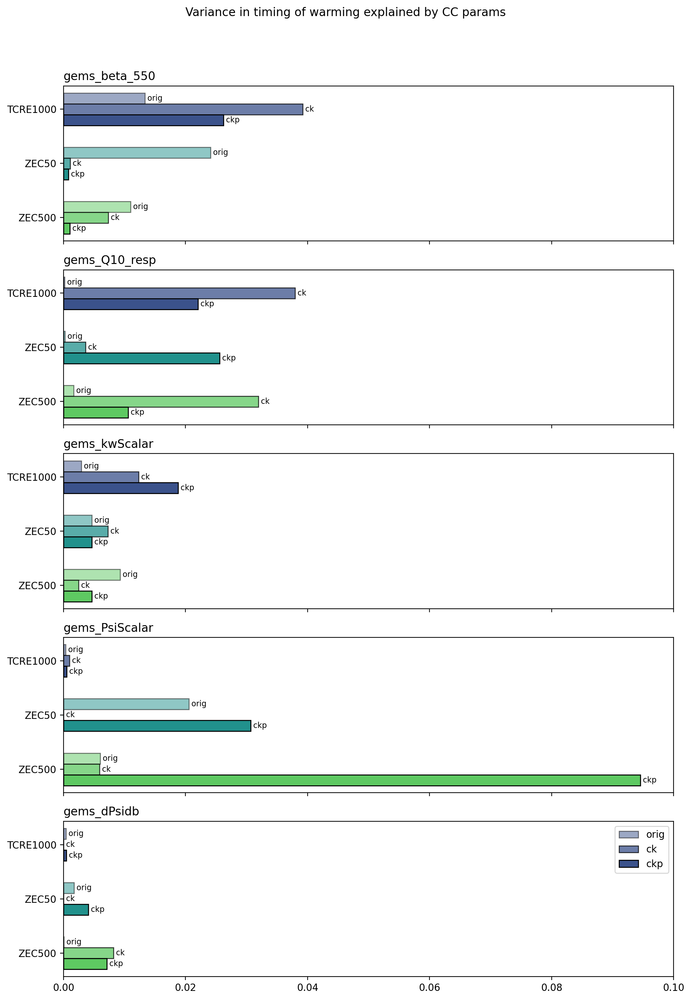

In [2077]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

params_to_plot = ['gems_beta_550', 'gems_Q10_resp', 'gems_kwScalar', 'gems_PsiScalar', 'gems_dPsidb']
experiments = ['orig', 'ck', 'ckp']
# experiments = ['FaIR_bgc',]
# experiments = ['FaIR_bgc', 'FaIR_bgc, no kappas', 'FaIR_bgc, correlated']

dataframes = [df_SD_rsquared_co2T, df_SDck_rsquared_co2T, df_SDckp_rsquared_co2T]

fig, ax = plt.subplots(len(params_to_plot), 1, 
                       figsize=(10, 15), dpi=200, sharex=True)

# Define the order of bars within each group
bar_order = ['TCRE1000', 'ZEC50', 'ZEC500',]

bar_width = 0.2  # Width of each bar
bar_positions = np.arange(len(bar_order))  # Positions for each group of bars

for i, param in enumerate(params_to_plot):
    for j, exp in enumerate(experiments):
        df = dataframes[j]
        
        # Define the labels for bars and their corresponding data
        bar_data = [df.loc[param, f'{group}'] for group in bar_order]
        # Adjust position for each set of bars
        positions = bar_positions + j * bar_width
        # Plot the bars with the defined labels and data
        bars = ax[i].barh(positions, bar_data, height=bar_width,
                          color=sns.color_palette('viridis', 3),
                          label=exp, alpha=[.5, 0.75, 1][j],
                          edgecolor='black')  # Add black outline to each bar

        # Add labels at the end of each bar
        for pos, val in zip(positions, bar_data):
            ax[i].text(val, pos, f' {exp}', va='center', ha='left', fontsize=8)

    # Set y-ticks to the middle of each group of bars
    ax[i].set_yticks(bar_positions + bar_width)
    ax[i].set_yticklabels(bar_order)
    ax[i].invert_yaxis()  # Reverse y-axis for each subplot
    
    # Add title for each subplot
    ax[i].set_title(f'{param}', loc = 'left')

# Add legend
ax[-1].legend()
plt.xlim(0, .1)
plt.suptitle(rf'Variance in timing of warming explained by CC params')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust the layout to accommodate suptitle
plt.savefig('figures/warming_variance_explained_by_ccparams_SDall_co2T', dpi=300)

plt.show()
plt.close()


In [2644]:
ds_fairSDckp_flat10['flux']

<xarray.DataArray 'flux' (time: 1111, scenario: 1, config: 1000, gasbox: 31)>
[34441000 values with dtype=float64]
Coordinates:
  * time      (time) int32 0 1 2 3 4 5 6 ... 1104 1105 1106 1107 1108 1109 1110
  * config    (config) int32 0 1 2 3 4 5 6 7 ... 992 993 994 995 996 997 998 999
  * gasbox    (gasbox) int32 0 1 2 3 4 5 6 7 8 9 ... 22 23 24 25 26 27 28 29 30
  * scenario  (scenario) object 'esm-flat10_zec'